<h1 style="text-align:center;">Labo 2 — Onduleur triphasé (AFE) raccordé au réseau : simulation et validation HIL</h1>


<br>

<p style="text-align:center;">
<strong>Auteurs:</strong><br>
Martin Majstorovic<br>
Noémie Mousquès
</p>

<p style="text-align:center;">
<strong>Cours:</strong> Electronique de puissance 2<br>
<strong>Professeur:</strong> Daniel Siemaszko<br>
<strong>Assistant:</strong> Eliott Sefaranga<br>
<strong>Institution:</strong> HEIG-VD<br>
<strong>Date:</strong> Octobre-Novembre 2026  
</p>

# Partie A - Simulation

# 2.1 Prise en main : modèle de réseau et synchronisation

## 2.1.2 Modèle de réseau

Le réseau électrique est modélisé par une source de tension triphasée équilibrée idéale ($V_{\text{grid}} = 230\text{ V}_{\text{eff}}$, $f_{\text{grid}} = 50\text{ Hz}$) en série avec une inductance de ligne $L_{\text{grid}} = 20\text{ }\mu\text{H}$ en amont du Point de Couplage Commun (PCC).

**Calcul de la puissance de court-circuit ($SSC$) :**
La réactance de ligne vaut :
$$X_{\text{grid}} = 2\pi \cdot f_{\text{grid}} \cdot L_{\text{grid}} = 2\pi \cdot 50 \cdot 20 \cdot 10^{-6} \approx 6{,}28\text{ m}\Omega$$

La puissance de court-circuit triphasée au PCC est donc :
$$SSC = \frac{3 \cdot V_{\text{grid}}^2}{X_{\text{grid}}} = \frac{3 \cdot 230^2}{6{,}283 \cdot 10^{-3}} \approx \mathbf{25{,}26\text{ MVA}}$$

**Calcul du rapport de force ($SCR$) :**
$$SCR = \frac{SSC}{S_n} = \frac{25{,}26 \cdot 10^6}{10 \cdot 10^3} \approx \mathbf{2526}$$

**Conclusion :** Avec un $SCR \approx 2526 \gg 10$, le réseau nominal est **extrêmement fort (*stiff grid*)**. L'impédance de ligne étant très faible, les courants injectés ou absorbés par le convertisseur de $10\text{ kVA}$ ne perturbent pratiquement pas la tension au PCC, garantissant une excellente stabilité pour la synchronisation (PLL).


## 2.1.3 Synchronisation (PLL)

In [1]:
import math

# Paramètres du PLL selon la méthode du cours
f_n = 20.0     # Fréquence naturelle [Hz]
zeta = 0.7     # Coefficient d'amortissement

# 1. Pulsation naturelle
omega_n = 2 * math.pi * f_n

# 2. Gains du PLL
Kp_pll = 2 * zeta * omega_n
Ki_pll = omega_n**2 / (2 * math.pi)

# 3. Affichage
print("=== Dimensionnement du PLL ===")
print(f"Fréquence naturelle : f_n = {f_n:.2f} Hz")
print(f"Amortissement       : zeta = {zeta:.2f}")
print(f"Pulsation naturelle : omega_n = {omega_n:.4f} rad/s")

print("\nA reporter dans PLECS :")
print(f"Kp_pll = {Kp_pll:.4f};")
print(f"Ki_pll = {Ki_pll:.4f};")

=== Dimensionnement du PLL ===
Fréquence naturelle : f_n = 20.00 Hz
Amortissement       : zeta = 0.70
Pulsation naturelle : omega_n = 125.6637 rad/s

A reporter dans PLECS :
Kp_pll = 175.9292;
Ki_pll = 2513.2741;


### Validation de la PLL en simulation hors-ligne (Offline)

Les trois signaux en sortie du bloc PLL valident le réglage théorique des gains ($K_p$ et $K_i$) en simulation pure :

* **Courbe 1 (Tension de crête $V_{peak}$) :** Elle se stabilise immédiatement à **$325.3\text{ V}$**. Cela correspond parfaitement à la tension de crête attendue pour un réseau de $230\text{ V}_{\text{RMS}}$ ($230 \times \sqrt{2} \approx 325.27\text{ V}$).
* **Courbe 2 (Fréquence) :** Après un transitoire très court au démarrage (< 50 ms), la fréquence se fige en ligne droite sur **$50\text{ Hz}$** sans aucune oscillation.
* **Courbe 3 (Angle $\theta$) :** On observe une rampe parfaite en dents de scie variant de $0$ à $2\pi$ ($\approx 6.28\text{ rad}$), ce qui confirme la bonne reconstruction de l'angle électrique du réseau.

#### Pourquoi cela valide le réglage de $K_p$ et $K_i$ ?
La rapidité d'accrochage (moins de 50 ms) et l'absence totale d'oscillations lentes prouvent que le coefficient d'amortissement choisi ($\zeta = 0.707$) est optimal. De plus, la stabilité parfaite à $50\text{ Hz}$ montre que le gain intégral ($K_i$) élimine totalement l'erreur statique de phase.


## 2.1.4 Tests de la PLL

### Démarrage

Pour valider le fonctionnement initial, deux oscilloscopes sont analysés en parallèle :
* **`Scope 1` (grandeurs estimées par la PLL) :** Permet de contrôler la détection de l'amplitude ($325{,}3\text{ V}$), la stabilisation de la fréquence ($50\text{ Hz}$) et la régularité de l'angle $\theta_N$.
* **`Scope 2` (tensions dans le repère de Park) :** Permet de vérifier l'alignement du repère $(d,q)$ via l'annulation de l'erreur $u_q$ et de mesurer le temps de réponse.


<div align="center">

<img src="PLL_démarrage.png" width="400">

<p style="text-align:center;"><em>Figure - Schéma de mesure des grandeurs estimées (`Scope 1`) et des composantes $(u_d, u_q)$ (`Scope 2`) autour de la PLL.</em></p>

</div>

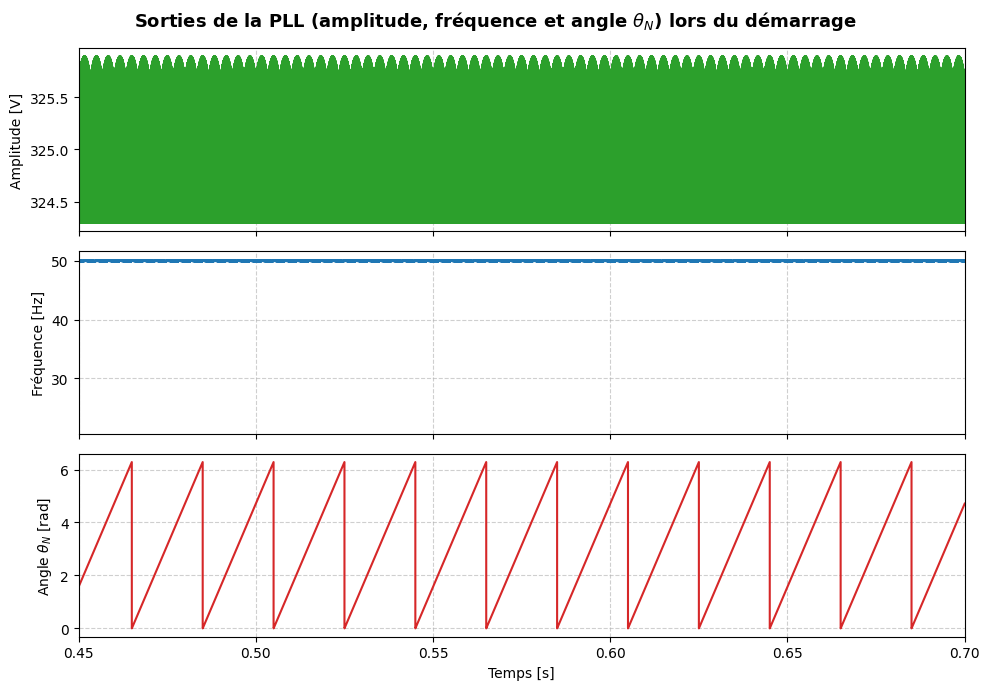

In [23]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Charger le fichier CSV (remplace 'donnees_pll.csv' par le nom exact de ton fichier)
fichier_csv = "PartA1_démarrageCV.csv"
df = pd.read_csv(fichier_csv)

# 2. Création de la figure avec 3 sous-graphes alignés sur l'axe du temps
fig, axs = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

# Titre général du graphe
fig.suptitle(
    "Sorties de la PLL (amplitude, fréquence et angle $\\theta_N$) lors du"
    " démarrage",
    fontsize=13,
    fontweight="bold",
)

# Piste 1 : Amplitude
axs[0].plot(df["Time / s"], df["Three-Phase PLL:amplitude"], color="tab:green")
axs[0].set_ylabel("Amplitude [V]")
axs[0].grid(True, linestyle="--", alpha=0.6)

# Piste 2 : Fréquence (f en Hz)
axs[1].plot(df["Time / s"], df["Three-Phase PLL:w"], color="tab:blue")
axs[1].set_ylabel("Fréquence [Hz]")
axs[1].grid(True, linestyle="--", alpha=0.6)

# Piste 3 : Angle theta_N (en rad)
axs[2].plot(df["Time / s"], df["Three-Phase PLL:theta"], color="tab:red")
axs[2].set_ylabel("Angle $\\theta_N$ [rad]")
axs[2].set_xlabel("Temps [s]")
axs[2].grid(True, linestyle="--", alpha=0.6)


axs[2].set_xlim(0.45, 0.70)

plt.tight_layout()
plt.show()


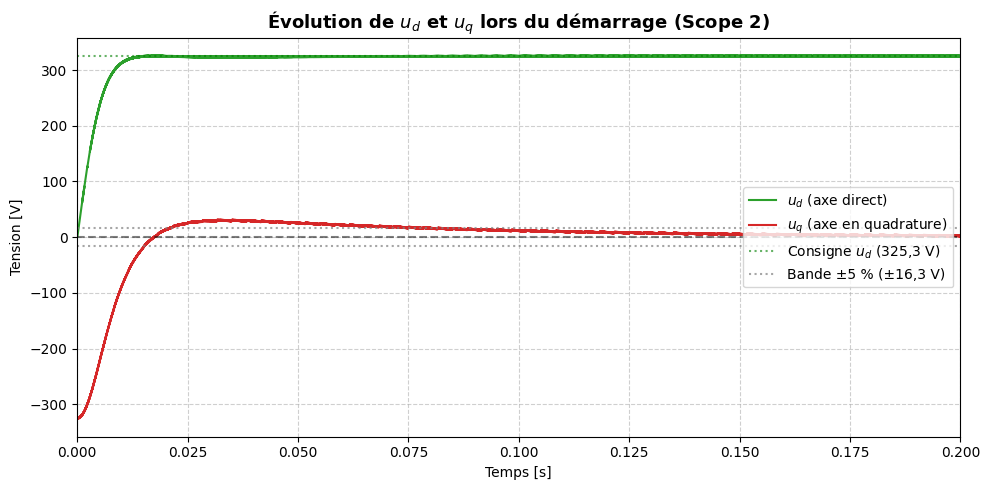

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Charger le fichier CSV de Scope2
fichier_csv = "PartA1_démarrageBlocage.csv"
df = pd.read_csv(fichier_csv)

# 2. Création du graphe
plt.figure(figsize=(10, 5))

plt.plot(
    df["Time / s"],
    df["3ph->RRF1:1"],
    label="$u_d$ (axe direct)",
    color="tab:green",
    linewidth=1.5,
)
plt.plot(
    df["Time / s"],
    df["3ph->RRF1:2"],
    label="$u_q$ (axe en quadrature)",
    color="tab:red",
    linewidth=1.5,
)

# Ajout des repères visuels (consignes 325,3 V et 0 V)
plt.axhline(
    325.27, color="green", linestyle=":", alpha=0.6, label="Consigne $u_d$ (325,3 V)"
)
plt.axhline(0, color="black", linestyle="--", alpha=0.5)

# Bande de tolérance des ± 5 % autour de 0 V (5% de 325,27 V = 16,26 V)
plt.axhline(
    16.26,
    color="gray",
    linestyle=":",
    alpha=0.7,
    label="Bande ±5 % (±16,3 V)",
)
plt.axhline(-16.26, color="gray", linestyle=":", alpha=0.7)

plt.xlim(0, 0.2)
#plt.ylim(-100, 350)

plt.title(
    "Évolution de $u_d$ et $u_q$ lors du démarrage (Scope 2)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Temps [s]")
plt.ylabel("Tension [V]")
plt.legend(loc="right")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


**Analyse de la convergence et du verrouillage :**
* **Convergence de l'asservissement (`Scope 2`) :** La composante directe $u_d$ rejoint rapidement l'amplitude crête du réseau ($325{,}3\text{ V}$), tandis que l'erreur en quadrature $u_q$ décroît depuis $-325\text{ V}$ pour s'annuler complètement en environ $180\text{ ms}$. Ce retour à $u_q = 0\text{ V}$ confirme le bon alignement du repère tournant sur le vecteur tension.
* **Blocage de l'angle (`Scope 1`) :** La fréquence estimée se stabilise à $50\text{ Hz}$ ($\omega_N \approx 314{,}16\text{ rad/s}$) dès $t \approx 30\text{ ms}$. Simultanément, l'angle $\theta_N$ (evoluant de $0$ à $2\pi\text{ rad}$) adopte une pente parfaitement linéaire de période $20\text{ ms}$, prouvant le verrouillage de phase sur le réseau.

### Modélisation du réseau pour l'essai de saut de phase ($90^\circ$)

Pour cette partie, nous avons dû la source triphasée standard (`Grid`) par le montage suivant.

<div align="center">

<img src="PLL_sautPhase.png" width="400">

<p style="text-align:center;"><em>Figure - Génération de la tension réseau avec un saut de phase de $90^\circ$.</em></p>

</div>


#### 1. Pourquoi remplacer la source triphasée standard (`Grid`) ?
Le bloc standard `Voltage Source AC (3 phase)` de PLECS n'accepte que des paramètres constants (amplitude, fréquence et déphasage initiaux) fixés avant le lancement de la simulation. Il est donc impossible d'y appliquer une perturbation dynamique en cours de route.

Pour générer un saut de phase brutal de $90^\circ$ ($\frac{\pi}{2}\text{ rad}$) en régime établi, la source initiale est remplacée par **trois sources de tension commandées monophasées** (`Controlled Voltage Source`), dont les tensions sinusoïdales sont calculées mathématiquement en temps réel.



#### 2. Réglage et rôle de chaque bloc du montage

* **Sources de tension commandées (`V`, `V1`, `V2`) :**
  * **Rôle :** Reproduisent la tension électrique de chaque phase ($A, B, C$) à partir du signal de commande reçu sur leur entrée. Leurs bornes négatives sont reliées ensemble à la masse (point neutre).
  * **Réglage :** Paramètres par défaut conservés (*First-order hold* pour une interpolation précise des sinusoïdes).

* **Horloge (`Clock`) :**
  * **Rôle :** Fournit le temps courant $t$ de la simulation (correspondant à l'entrée `u[1]` du multiplexeur).
  * **Réglage :** Aucun paramètre requis.

* **Échelon (`Step1`) :**
  * **Rôle :** Déclenche le saut de phase de $90^\circ$ à un instant précis (correspondant à l'entrée `u[2]` du multiplexeur).
  * **Réglage :** *Step time* = `0.5` s, *Initial value* = `0` rad, *Final value* = `pi/2` rad.

* **Multiplexeur (`Mux`) :**
  * **Rôle :** Regroupe les signaux `Clock` (`u[1]`) et `Step1` (`u[2]`) en un vecteur unique pour alimenter simultanément les trois blocs de calcul.

* **Blocs fonctionnels (`Fcn`, `Fcn1`, `Fcn2`) :**
  * **Rôle :** Calculent l'équation instantanée de chaque phase en ajoutant le déphasage `u[2]` à l'angle électrique $\omega t$. Chaque bloc ne pouvant sortir qu'un scalaire, trois blocs distincts sont utilisés :
    * **Phase A (`Fcn`) :** `V_grid * sin(2*pi*f_grid*u[1] + u[2])`
    * **Phase B (`Fcn1`) :** `V_grid * sin(2*pi*f_grid*u[1] - 2*pi/3 + u[2])`
    * **Phase C (`Fcn2`) :** `V_grid * sin(2*pi*f_grid*u[1] + 2*pi/3 + u[2])`


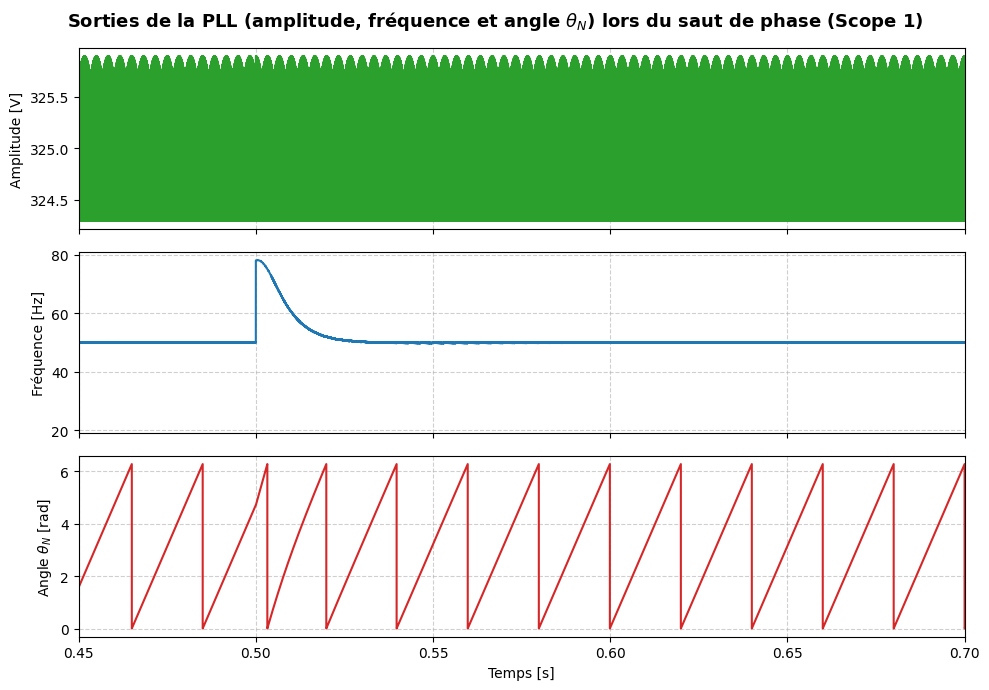

In [12]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Charger le fichier CSV (remplace 'donnees_pll.csv' par le nom exact de ton fichier)
fichier_csv = "PartA1_sautScope1.csv"
df = pd.read_csv(fichier_csv)

# 2. Création de la figure avec 3 sous-graphes alignés sur l'axe du temps
fig, axs = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

# Titre général du graphe
fig.suptitle(
    "Sorties de la PLL (amplitude, fréquence et angle $\\theta_N$) lors du"
    " saut de phase (Scope 1)",
    fontsize=13,
    fontweight="bold",
)

# Piste 1 : Amplitude
axs[0].plot(df["Time / s"], df["Three-Phase PLL:amplitude"], color="tab:green")
axs[0].set_ylabel("Amplitude [V]")
axs[0].grid(True, linestyle="--", alpha=0.6)

# Piste 2 : Fréquence (f en Hz)
axs[1].plot(df["Time / s"], df["Three-Phase PLL:w"], color="tab:blue")
axs[1].set_ylabel("Fréquence [Hz]")
axs[1].grid(True, linestyle="--", alpha=0.6)

# Piste 3 : Angle theta_N (en rad)
axs[2].plot(df["Time / s"], df["Three-Phase PLL:theta"], color="tab:red")
axs[2].set_ylabel("Angle $\\theta_N$ [rad]")
axs[2].set_xlabel("Temps [s]")
axs[2].grid(True, linestyle="--", alpha=0.6)


axs[2].set_xlim(0.45, 0.70)

plt.tight_layout()
plt.show()


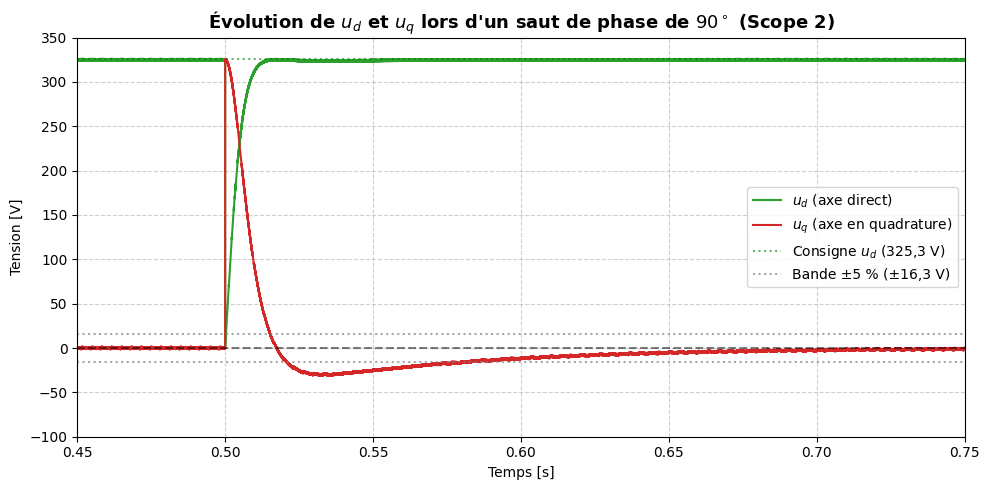

In [11]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Charger le fichier CSV de Scope2
fichier_csv = "PartA1_sautScope2.csv"
df = pd.read_csv(fichier_csv)

# 2. Création du graphe
plt.figure(figsize=(10, 5))

plt.plot(
    df["Time / s"],
    df["3ph->RRF1:1"],
    label="$u_d$ (axe direct)",
    color="tab:green",
    linewidth=1.5,
)
plt.plot(
    df["Time / s"],
    df["3ph->RRF1:2"],
    label="$u_q$ (axe en quadrature)",
    color="tab:red",
    linewidth=1.5,
)

# Ajout des repères visuels (consignes 325,3 V et 0 V)
plt.axhline(
    325.27, color="green", linestyle=":", alpha=0.6, label="Consigne $u_d$ (325,3 V)"
)
plt.axhline(0, color="black", linestyle="--", alpha=0.5)

# Bande de tolérance des ± 5 % autour de 0 V (5% de 325,27 V = 16,26 V)
plt.axhline(
    16.26,
    color="gray",
    linestyle=":",
    alpha=0.7,
    label="Bande ±5 % (±16,3 V)",
)
plt.axhline(-16.26, color="gray", linestyle=":", alpha=0.7)

plt.xlim(0.45, 0.75)
plt.ylim(-100, 350)

plt.title(
    "Évolution de $u_d$ et $u_q$ lors d'un saut de phase de $90^\\circ$ (Scope 2)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Temps [s]")
plt.ylabel("Tension [V]")
plt.legend(loc="right")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


À $t = 0{,}5\text{ s}$, un déphasage brusque de $+90^\circ$ ($\frac{\pi}{2}\text{ rad}$) est appliqué aux trois phases du réseau :

* **Bascule dans le repère de Park (`Scope 2`) :** Le vecteur tension pivote instantanément sur l'axe en quadrature. La composante directe $u_d$ chute brutalement de $325{,}3\text{ V}$ à $0\text{ V}$, tandis que l'erreur $u_q$ saute de $0\text{ V}$ à $+325{,}3\text{ V}$.
* **Temps de ré-accrochage (`Scope 2`) :** Le régulateur PI corrige cette erreur avec un léger dépassement négatif ($\approx -30\text{ V}$) et ramène $u_q$ à $0\text{ V}$ ($u_d \to 325{,}3\text{ V}$) vers $t \approx 0{,}68\text{ s}$. Le temps de réponse mesuré est donc d'environ **$180\text{ ms}$**, identique à celui observé au démarrage.
* **Dynamique de fréquence et d'angle (`Scope 1`) :** Pour rattraper le saut de phase, la fréquence estimée présente un pic transitoire jusqu'à $\approx 78\text{ Hz}$ ($\omega_N \approx 490\text{ rad/s}$) avant de se re-stabiliser à $50\text{ Hz}$. La dent de scie $\theta_N$ subit un décalage puis retrouve immédiatement sa pente linéaire.


### Dip de tension sur une seule phase 

Pour simuler une chute de tension de $50\,\%$ sur une seule phase sans modifier le câblage de l'essai précédent (le saut de phase), seuls les paramètres de l'échelon et les équations des blocs fonctionnels sont adaptés :

* **Échelon (`Step1`) :**
  * **Rôle :** Applique un facteur multiplicatif d'amplitude à l'instant du défaut.
  * **Réglage :** *Step time* = `0.5` s, *Initial output* = `1` (100 % de la tension nominale), *Final output* = `0.5` (chute de 50 % après le défaut).

* **Blocs fonctionnels (`Fcn`, `Fcn1`, `Fcn2`) :**
  * **Rôle :** Le terme de déphasage est retiré et le signal de l'échelon (`u[2]`) est appliqué uniquement comme facteur d'amplitude sur la phase A, tandis que les phases B et C conservent leur amplitude nominale (`u[1]` désignant le temps $t$) :
    * **Phase A (`Fcn`) :** `u[2] * V_grid * sin(2*pi*f_grid*u[1])`
    * **Phase B (`Fcn1`) :** `V_grid * sin(2*pi*f_grid*u[1] - 2*pi/3)`
    * **Phase C (`Fcn2`) :** `V_grid * sin(2*pi*f_grid*u[1] + 2*pi/3)`


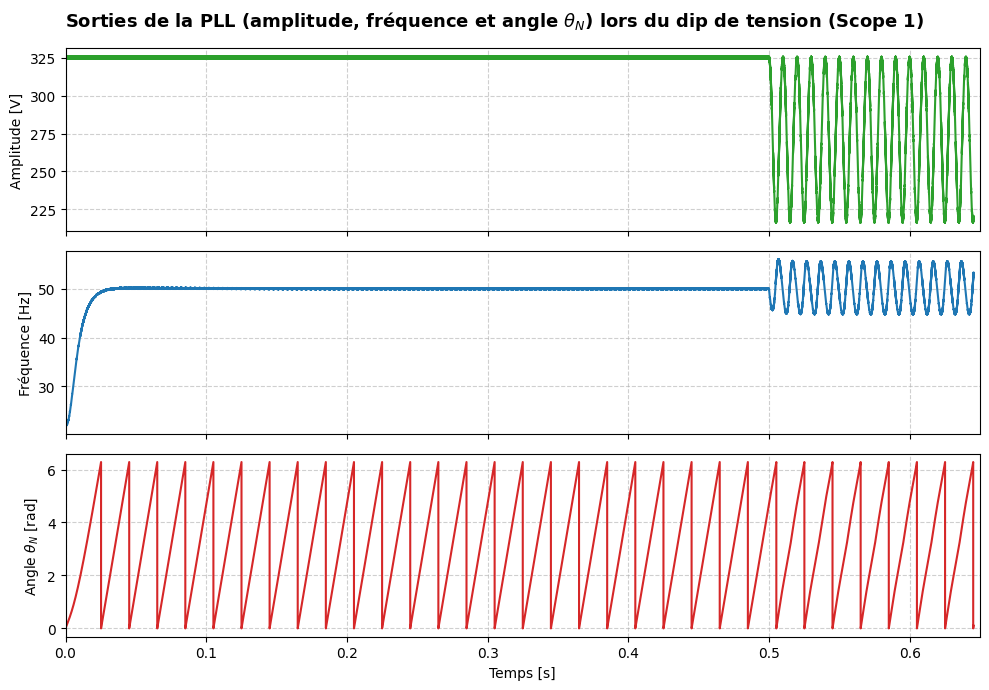

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Charger le fichier CSV (remplace 'donnees_pll.csv' par le nom exact de ton fichier)
fichier_csv = "PartA1_dipScope1.csv"
df = pd.read_csv(fichier_csv)

# 2. Création de la figure avec 3 sous-graphes alignés sur l'axe du temps
fig, axs = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

# Titre général du graphe
fig.suptitle(
    "Sorties de la PLL (amplitude, fréquence et angle $\\theta_N$) lors du"
    " dip de tension (Scope 1)",
    fontsize=13,
    fontweight="bold",
)

# Piste 1 : Amplitude
axs[0].plot(df["Time / s"], df["Three-Phase PLL:amplitude"], color="tab:green")
axs[0].set_ylabel("Amplitude [V]")
axs[0].grid(True, linestyle="--", alpha=0.6)

# Piste 2 : Fréquence (f en Hz)
axs[1].plot(df["Time / s"], df["Three-Phase PLL:w"], color="tab:blue")
axs[1].set_ylabel("Fréquence [Hz]")
axs[1].grid(True, linestyle="--", alpha=0.6)

# Piste 3 : Angle theta_N (en rad)
axs[2].plot(df["Time / s"], df["Three-Phase PLL:theta"], color="tab:red")
axs[2].set_ylabel("Angle $\\theta_N$ [rad]")
axs[2].set_xlabel("Temps [s]")
axs[2].grid(True, linestyle="--", alpha=0.6)


axs[2].set_xlim(0.0, 0.65)

plt.tight_layout()
plt.show()


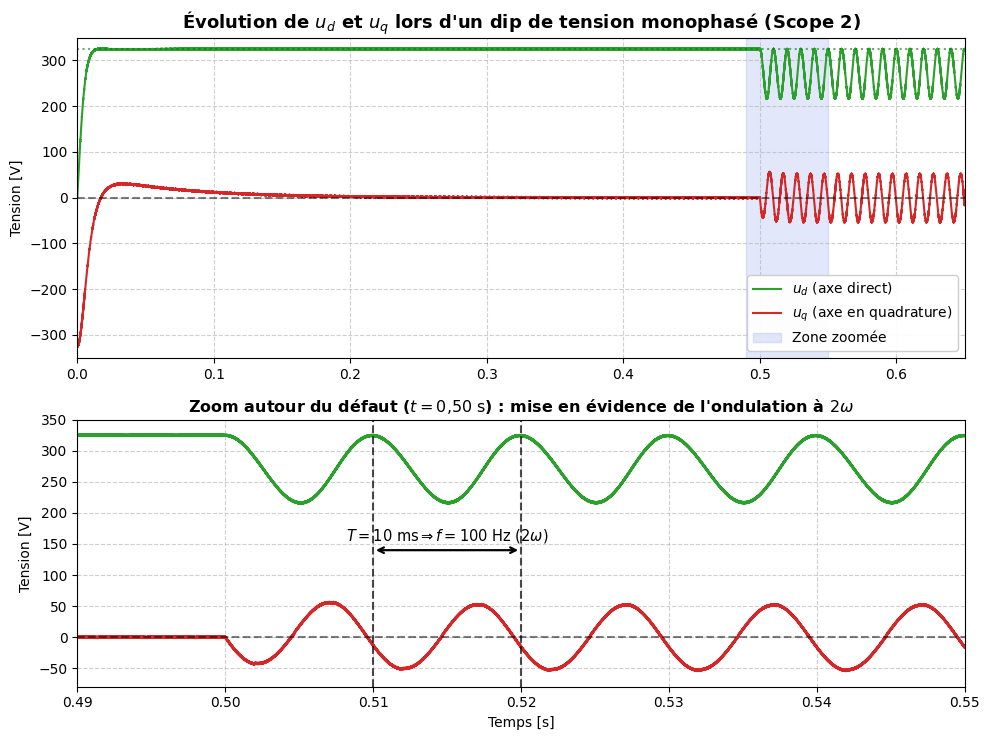

In [22]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Charger le fichier CSV de Scope2
fichier_csv = "PartA1_dipScope2.csv"
df = pd.read_csv(fichier_csv)

# 2. Création de la figure à 2 étages (Vue globale en haut, Zoom en bas)
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 7.5), gridspec_kw={"height_ratios": [1.2, 1]}
)

# --- ÉTAGE DU HAUT : Graphe complet (0 à 0.65 s) ---
ax1.plot(
    df["Time / s"],
    df["3ph->RRF1:1"],
    label="$u_d$ (axe direct)",
    color="tab:green",
    linewidth=1.5,
)
ax1.plot(
    df["Time / s"],
    df["3ph->RRF1:2"],
    label="$u_q$ (axe en quadrature)",
    color="tab:red",
    linewidth=1.5,
)
ax1.axhline(325.27, color="green", linestyle=":", alpha=0.6)
ax1.axhline(0, color="black", linestyle="--", alpha=0.5)

# Encadré bleu montrant la zone qui est zoomée en bas
ax1.axvspan(0.49, 0.55, color="royalblue", alpha=0.15, label="Zone zoomée")
ax1.set_xlim(0.0, 0.65)
ax1.set_ylim(-350, 350)
ax1.set_title(
    "Évolution de $u_d$ et $u_q$ lors d'un dip de tension monophasé (Scope 2)",
    fontsize=13,
    fontweight="bold",
)
ax1.set_ylabel("Tension [V]")
ax1.legend(loc="lower right", framealpha=0.95)
ax1.grid(True, linestyle="--", alpha=0.6)

# --- ÉTAGE DU BAS : Zoom sur la zone bleue (0.49 à 0.55 s) ---
ax2.plot(
    df["Time / s"],
    df["3ph->RRF1:1"],
    label="$u_d$",
    color="tab:green",
    linewidth=1.8,
)
ax2.plot(
    df["Time / s"],
    df["3ph->RRF1:2"],
    label="$u_q$",
    color="tab:red",
    linewidth=1.8,
)
ax2.axhline(0, color="black", linestyle="--", alpha=0.5)

# Repères et flèche pour mesurer une période T = 10 ms (de 0.51 à 0.52 s)
ax2.axvline(0.51, color="black", linestyle="--", alpha=0.7)
ax2.axvline(0.52, color="black", linestyle="--", alpha=0.7)
ax2.annotate(
    "",
    xy=(0.51, 140),
    xytext=(0.52, 140),
    arrowprops=dict(arrowstyle="<->", color="black", lw=1.6),
)
ax2.text(
    0.515,
    155,
    "$T = 10\\text{ ms} \\Rightarrow f = 100\\text{ Hz } (2\\omega)$",
    ha="center",
    fontsize=10.5,
    fontweight="bold",
)

ax2.set_xlim(0.49, 0.55)
ax2.set_ylim(-80, 350)
ax2.set_title(
    "Zoom autour du défaut ($t = 0{,}50\\text{ s}$) : mise en évidence de"
    " l'ondulation à $2\\omega$",
    fontsize=11.5,
    fontweight="bold",
)
ax2.set_xlabel("Temps [s]")
ax2.set_ylabel("Tension [V]")
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


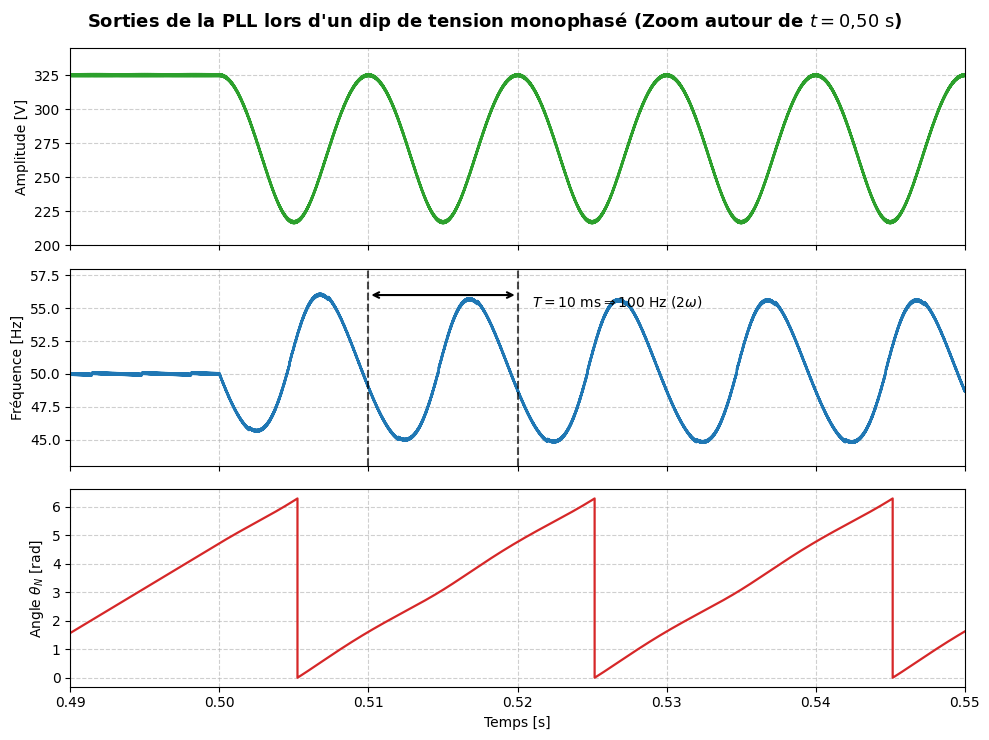

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Charger le fichier CSV de Scope1
fichier_csv = "PartA1_dipScope1.csv"
df = pd.read_csv(fichier_csv)

# 2. Création des 3 sous-graphes alignés
fig, axs = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)

fig.suptitle(
    "Sorties de la PLL lors d'un dip de tension monophasé (Zoom autour de"
    " $t = 0{,}50\\text{ s}$)",
    fontsize=13,
    fontweight="bold",
)

# Piste 1 : Amplitude estimée (avec marge en haut et en bas)
axs.plot(df["Time / s"], df["Three-Phase PLL:amplitude"], color="tab:green", linewidth=1.8)
axs.set_ylabel("Amplitude [V]")
axs.set_ylim(195, 355)
axs.grid(True, linestyle="--", alpha=0.6)

# Piste 2 : Fréquence estimée (avec espace dédié en haut pour l'annotation)
axs.plot(df["Time / s"], df["Three-Phase PLL:w"], color="tab:blue", linewidth=1.8)
axs.set_ylabel("Fréquence [Hz]")
axs.set_ylim(43.5, 60.5)
axs.grid(True, linestyle="--", alpha=0.6)

# Repères et flèche placés au-dessus des crêtes (y = 57.5)
axs.axvline(0.51, color="black", linestyle="--", alpha=0.6)
axs.axvline(0.52, color="black", linestyle="--", alpha=0.6)
axs.annotate(
    "",
    xy=(0.51, 57.8),
    xytext=(0.52, 57.8),
    arrowprops=dict(arrowstyle="<->", color="black", lw=1.5),
)
axs.text(
    0.5215,
    57.8,
    "$T = 10\\text{ ms} \\Rightarrow 100\\text{ Hz } (2\\omega)$",
    va="center",
    fontsize=10,
    fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor="lightgray", alpha=0.95),
)

# Piste 3 : Angle theta_N (en rad)
axs.plot(df["Time / s"], df["Three-Phase PLL:theta"], color="tab:red", linewidth=1.8)
axs.set_ylabel("Angle $\\theta_N$ [rad]")
axs.set_xlabel("Temps [s]")
axs.set_ylim(-0.3, 6.7)
axs.grid(True, linestyle="--", alpha=0.6)

# 3. Zoom autour du défaut (0.49 s à 0.55 s)
axs.set_xlim(0.49, 0.55)

plt.tight_layout()
plt.show()


À $t = 0{,}5\text{ s}$, une chute de tension de $50\,\%$ est appliquée uniquement sur la phase A :

* **Ondulation à $2\omega$ sur $u_d$ et $u_q$ (`Scope 2` et zoom) :** Dès le début du défaut, une oscillation entretenue de période **$T = 10\text{ ms}$** (soit **$f = 100\text{ Hz} = 2\omega$**) apparaît sur les deux composantes : $u_d$ oscille entre $217\text{ V}$ et $325\text{ V}$, tandis que $u_q$ oscille autour de $0\text{ V}$ ($\pm 54\text{ V}$).
* **Propagation à la fréquence et à l'angle $\theta_N$ (`Scope 1`) :** Cette perturbation à $2\omega$ traverse le régulateur PI de la PLL. La fréquence estimée oscille alors à $100\text{ Hz}$ entre $45\text{ Hz}$ et $55\text{ Hz}$, ce qui répercute une légère ondulation à $2\omega$ sur l'intégration de l'angle $\theta_N$ (déformation périodique de la pente de la dent de scie) ainsi que sur l'amplitude estimée.
* **Signature du déséquilibre :** Un réseau déséquilibré fait apparaître une composante inverse tournant à $-\omega$. Vue depuis le repère de Park lié à la composante directe ($+\omega$), cette séquence inverse tourne à une vitesse relative de **$-2\omega$ ($100\text{ Hz}$)**, générant cette ondulation caractéristique qu'une SRF-PLL classique ne filtre pas.


### Bilan de la confrontation avec la théorie (temps de réponse)

| Scénario de test | Temps de réponse théorique ($t_{r,5\%}$) | Temps de réponse mesuré | Observation |
| :--- | :--- | :--- | :--- |
| **1. Démarrage** | $34{,}1\text{ ms}$ | $\approx 180\text{ ms}$ | Convergence stable sans oscillation entretenue |
| **2. Saut de phase ($90^\circ$)** | $34{,}1\text{ ms}$ | $\approx 180\text{ ms}$ | Ré-accrochage complet avec léger dépassement |
| **3. Dip de tension ($50\,\%$)** | *Non applicable* | *Régime oscillatoire* | Ondulation permanente à $2\omega$ ($100\text{ Hz}$) |

* **Analyse des temps de réponse (Essais 1 et 2) :** Le temps mesuré ($\approx 180\text{ ms}$) est supérieur à la valeur théorique ($34{,}1\text{ ms}$) principalement parce que le bloc PLECS intègre la fréquence en $\text{Hz}$ (ajoutant un gain de $2\pi$ qui augmente l'amortissement effectif à $\zeta_{\text{réel}} \approx 4{,}4$), combiné à la non-linéarité du sinus lors d'un grand saut de phase de $90^\circ$.
* **Cas du dip de tension (Essai 3) :** Le déséquilibre introduisant une perturbation sinusoïdale permanente à $100\text{ Hz}$ ($\pm 54\text{ V}$ sur $u_q$), aucun régime permanent statique n'est atteint et la notion de temps de réponse ne s'applique pas.


# 2.2 Boucle de courant et contrôle de puissance

Lors de la régulation du courant, on utilise une source de tension idéale de 800 V. Dans le sous-système "Control", il faut bien faire attention à mettre le switch vers le Power control.

<div align="center">

<img src="PartA2_Circuit.png" width="750">

<p style="text-align:center;"><em>Figure - AFE adapté pour la régulation de courant.</em></p>

</div>

<div align="center">

<img src="PartA3_Control.png" width="750">

<p style="text-align:center;"><em>Figure - Bloc de contrôle adapté à la commande du courant.</em></p>

</div>

### 2.2.2 Structure de la commande vectorielle du courant

Le sous-système `Control` implémente une régulation vectorielle dans le repère tournant $(d,q)$ synchronisé avec le réseau via la PLL (`Subsystem`) :

* **Transformations (`abc -> dq`) :** Les courants réseau $I_{\mathrm{grid}}$ et tensions $U_{\mathrm{grid}}$ sont projetés dans le repère $(d,q)$ via les transformées de Clarke et Park à l'aide de l'angle $\theta$ issu de la PLL.
* **Régulateurs PI :** Deux correcteurs PI discrets annulent l'erreur entre les consignes ($i_d^{\mathrm{ref}}, i_q^{\mathrm{ref}}$) et les courants mesurés ($i_d, i_q$).
* **Découplage ($\pm \omega L i$) :** Les termes croisés $-\omega L i_q$ (axe $d$) et $+\omega L i_d$ (axe $q$) compensent le couplage inductif entre les deux axes.
* **Feedforward et PWM :** Les tensions réseau $u_{rd}$ et $u_{rq}$ sont ajoutées en anticipation (*feedforward*) pour former $u_{sd}^{\mathrm{ref}}$ et $u_{sq}^{\mathrm{ref}}$, puis retransformées en triphasé (`dq -> abc`) et normalisées par $V_{\mathrm{DC}}$ pour générer les rapports cycliques `PWM`.


### 2.2.3 Dimensionnement

In [ ]:

# Dimensionnement du régulateur de courant PI
# Méthode : critère symétrique du cours

# Paramètres du modèle PLECS
VDC = 800.0          # Tension du bus DC [V]
L_filter = 6.68e-3   # Inductance totale du filtre [H]
f_sw = 20e3          # Fréquence de commutation [Hz]

# 1. Constante de temps équivalente du convertisseur
T_cm = 3 / (2 * f_sw)

# 2. Temps intégral selon le critère symétrique
T_i = 4 * T_cm

# 3. Gain du convertisseur
K_cm = 1 #traitement valeurs sans gains

# 4. Calcul des gains du PI
Kp_i = L_filter / (2 * K_cm * T_cm)
Ki_i = Kp_i / T_i

# Affichage des résultats
print("=== Régulateur de courant PI ===")
print(f"T_cm = {T_cm * 1e6:.2f} µs")
print(f"T_i  = {T_i * 1e6:.2f} µs")
print(f"K_cm = {K_cm:.2f}")
print(f"Kp_i = {Kp_i:.4f}")
print(f"Ki_i = {Ki_i:.2f}")

# Valeurs à reporter dans le script MATLAB
print("\nParamètres MATLAB :")
print(f"Kp_i = {Kp_i:.4f};")
print(f"Ki_i = {Ki_i:.2f};")


### 2.2.4 Validation par sauts de consigne

--- Axe d (id) : saut à t = 400.00 ms (0.0 A -> 10.2 A) ---
  Temps de réponse (95 %) : 3.42 ms
  Dépassement             : 7.51 %
  Erreur statique         : -0.012 A

--- Axe q (iq) : saut à t = 700.00 ms (0.0 A -> 10.3 A) ---
  Temps de réponse (95 %) : 1.78 ms
  Dépassement             : 5.21 %
  Erreur statique         : 0.032 A



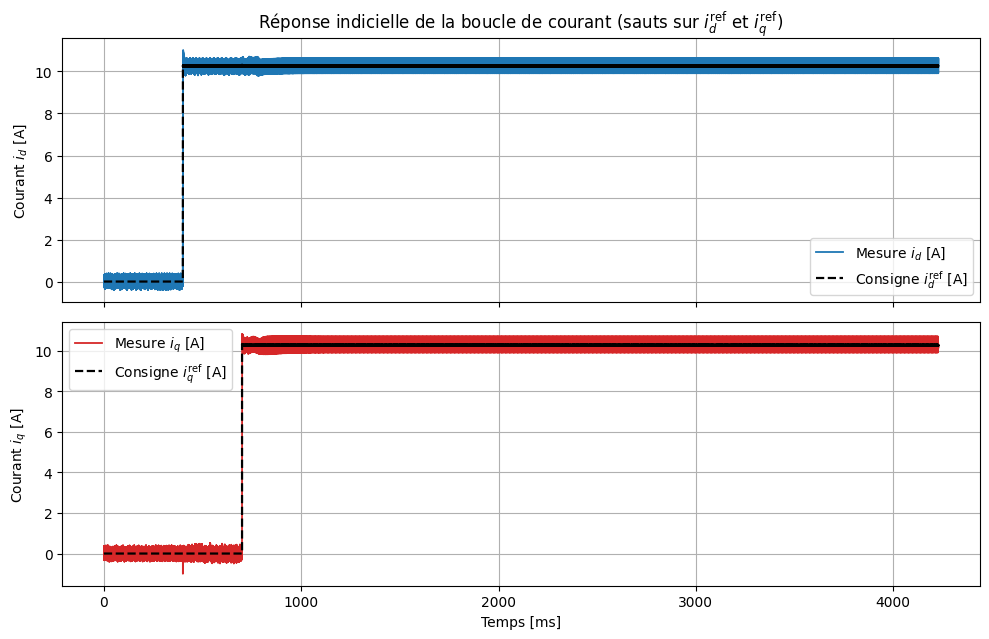

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA2_ConsigneCourant.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t      = df.iloc[:, 0].values  # Time / s
id_mes = df.iloc[:, 1].values  # 3ph->RRF:1 (i_d mesuré)
id_ref = df.iloc[:, 2].values  # Manual Switch:1 (i_d ref)
iq_mes = df.iloc[:, 3].values  # 3ph->RRF:2 (i_q mesuré)
iq_ref = df.iloc[:, 4].values  # Manual Switch:2 (i_q ref)

# Fonction d'analyse automatique d'un saut de consigne
def analyser_saut(nom, temps, mesure, consigne):
    diff_ref = np.abs(np.diff(consigne))
    if np.max(diff_ref) < 0.1:
        print(f"[{nom}] Aucun saut de consigne détecté.")
        return

    idx_step = np.argmax(diff_ref) + 1
    t_step   = temps[idx_step]
    v_init   = consigne[idx_step - 1]
    v_fin    = consigne[idx_step]
    delta    = v_fin - v_init

    # Zone d'analyse jusqu'au prochain saut éventuel (ou fin du fichier)
    autres_sauts = np.where(diff_ref[idx_step:] > 0.1)[0]
    idx_fin = idx_step + autres_sauts[0] if len(autres_sauts) > 0 else len(temps)

    t_zone   = temps[idx_step:idx_fin]
    mes_zone = mesure[idx_step:idx_fin]

    # Temps de réponse à 95 % (bande des +-5 %)
    err_rel = np.abs(mes_zone - v_fin) / np.abs(delta)
    hors_bande = np.where(err_rel > 0.05)[0]
    tr_95 = (t_zone[hors_bande[-1] + 1] - t_step) * 1000 if len(hors_bande) > 0 and hors_bande[-1] + 1 < len(t_zone) else 0.0

    # Dépassement maximal (%)
    if delta > 0:
        depassement = max(0.0, (np.max(mes_zone) - v_fin) / delta * 100)
    else:
        depassement = max(0.0, (v_fin - np.min(mes_zone)) / abs(delta) * 100)

    # Erreur statique en fin de palier
    n_palier = int(0.8 * len(mes_zone))
    err_stat = np.mean(v_fin - mes_zone[n_palier:]) if n_palier < len(mes_zone) else 0.0

    print(f"--- {nom} : saut à t = {t_step*1000:.2f} ms ({v_init:.1f} A -> {v_fin:.1f} A) ---")
    print(f"  Temps de réponse (95 %) : {tr_95:.2f} ms")
    print(f"  Dépassement             : {depassement:.2f} %")
    print(f"  Erreur statique         : {err_stat:.3f} A\n")

# 2. Calcul des performances dans la console
analyser_saut("Axe d (id)", t, id_mes, id_ref)
analyser_saut("Axe q (iq)", t, iq_mes, iq_ref)

# 3. Tracé des courbes pour le rapport
fig, axs = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)

# Graphe 1 : Axe d (id)
axs[0].plot(t * 1000, id_mes, label=r"Mesure $i_d$ [A]", color="tab:blue", linewidth=1.3)
axs[0].plot(t * 1000, id_ref, label=r"Consigne $i_d^{\mathrm{ref}}$ [A]", color="black", linestyle="--", linewidth=1.6)
axs[0].set_ylabel("Courant $i_d$ [A]")
axs[0].set_title("Réponse indicielle de la boucle de courant (sauts sur $i_d^{\\mathrm{ref}}$ et $i_q^{\\mathrm{ref}}$)")
axs[0].grid(True)
axs[0].legend(loc="best")

# Graphe 2 : Axe q (iq)
axs[1].plot(t * 1000, iq_mes, label=r"Mesure $i_q$ [A]", color="tab:red", linewidth=1.3)
axs[1].plot(t * 1000, iq_ref, label=r"Consigne $i_q^{\mathrm{ref}}$ [A]", color="black", linestyle="--", linewidth=1.6)
axs[1].set_ylabel("Courant $i_q$ [A]")
axs[1].set_xlabel("Temps [ms]")
axs[1].grid(True)
axs[1].legend(loc="best")

plt.tight_layout()
plt.show()


**Comparaison avec les prédictions théoriques :**

Les réponses indicielles obtenues pour les sauts sur $i_d^{\mathrm{ref}}$ ($t = 400\text{ ms}$) et $i_q^{\mathrm{ref}}$ ($t = 700\text{ ms}$) concordent avec le dimensionnement théorique des régulateurs PI :
* **Temps de réponse ($t_{r,95\%}$) :** Les courants atteignent leur consigne en **$3.42\text{ ms}$** (axe $d$) et **$1.78\text{ ms}$** (axe $q$), ce qui valide la dynamique rapide attendue pour la boucle interne.
* **Dépassement et erreur statique :** L'erreur statique est quasi nulle ($-0.012\text{ A}$ et $+0.032\text{ A}$) grâce à l'action intégrale. Les légers dépassements (**$7.51\%$** sur $i_d$ et **$5.21\%$** sur $i_q$) s'expliquent par l'amortissement du correcteur et le retard numérique cumulé (échantillonnage et mise à jour PWM).
* **Découplage $(d,q)$ :** Le saut sur $i_d$ à $t = 400\text{ ms}$ n'induit qu'une brève perturbation transitoire sur $i_q$ (due au retard discret des termes de découplage $\pm \omega L i$), immédiatement rejetée par le régulateur.
* **Ondulation résiduelle :** La largeur du tracé en régime établi ($\pm 0.3\text{ A}$) correspond à l'ondulation de découpage PWM à $20\text{ kHz}$, absente du modèle moyen théorique.


### 2.2.5 Commande directe en puissance active et réactive ($P, Q$) 

<div style="display:flex; justify-content:center; gap:20px;">
<div style="text-align:center;"><img src="PartA2_Control_Power.png" width="900"><br><em>(a) Schéma complet <code>Control</code> intégrant la boucle de puissance.</em></div>
<div style="text-align:center;"><img src="PartA2_Power_Sub.png" width="300"><br><em>(b) Détail du bloc <code>Power control</code> (calcul de i<sub>d,ref</sub> et i<sub>q,ref</sub>).</em></div>
</div>
<p style="text-align:center;"><em>Figure — Architecture de la commande en puissance (P, Q).</em></p>





#### 1. Implémentation et réglages
Pour piloter directement les échanges de puissance au PCC, le sous-système `Power control` calcule les consignes de courant $(i_d^{\mathrm{ref}}, i_q^{\mathrm{ref}})$ à partir des consignes $(P^{\mathrm{ref}}, Q^{\mathrm{ref}})$ et de l'amplitude réseau $\hat{u}_r$ issue de la PLL :
$$i_d^{\mathrm{ref}} = \frac{2}{3}\frac{P^{\mathrm{ref}}}{\hat{u}_r}, \qquad i_q^{\mathrm{ref}} = \frac{2}{3}\frac{Q^{\mathrm{ref}}}{\hat{u}_r}$$

* **Protection initiale (`Saturation`) :** Un bloc `Saturation` (limite basse à $10\text{ V}$) a été ajouté sur l'entrée `U_peak` avant la division afin d'éviter une division par zéro au démarrage ($t = 0\text{ s}$) avant l'accrochage de la PLL.
* **Scénario de validation bidirectionnel :** Deux paires de blocs `Step` additionnés génèrent des créneaux positifs et négatifs pour tester à la fois l'absorption et la restitution :
  * **Puissance active $P^{\mathrm{ref}}$ :** $0\text{ W} \xrightarrow{0.40\text{ s}} +2500\text{ W} \xrightarrow{0.55\text{ s}} -2500\text{ W}$ (échelons de $+2500$ puis $-5000$).
  * **Puissance réactive $Q^{\mathrm{ref}}$ :** $0\text{ var} \xrightarrow{0.70\text{ s}} +2500\text{ var} \xrightarrow{0.85\text{ s}} -2500\text{ var}$ (échelons de $+2500$ puis $-5000$).
* **Mesure au PCC :** Un bloc `Power Calculation` relié à `U_grid` et `I_grid` permet de comparer directement les puissances réelles $(P, Q)$ aux consignes.

#### 2. Problèmes rencontrés et résolution
* **Erreur de division par zéro à $t = 0\text{ s}$ :** Résolue en insérant la saturation minimale sur `U_peak`.
* **Inversion des consignes $(i_d^{\mathrm{ref}}, i_q^{\mathrm{ref}})$ et perturbation de la PLL :** Lors des premiers essais, l'ordre des ports de sortie de `Power control` et une perturbation issue du bloc de déséquilibre réseau avaient provoqué un décrochage temporaire de la PLL (oscillations à $50\text{ Hz}$). Une fois l'ordre des voies rétabli (`id_cons` en haut, `iq_cons` en bas) et la source triphasée équilibrée restaurée, le système s'est stabilisé.

#### 3. Validation des résultats
Les relevés confirment le fonctionnement bidirectionnel de la commande : $P$ et $Q$ suivent fidèlement les échelons positifs et négatifs en quelques millisecondes avec une erreur statique nulle et un découplage complet (les sauts sur $P$ n'affectent pas $Q$, et inversement).


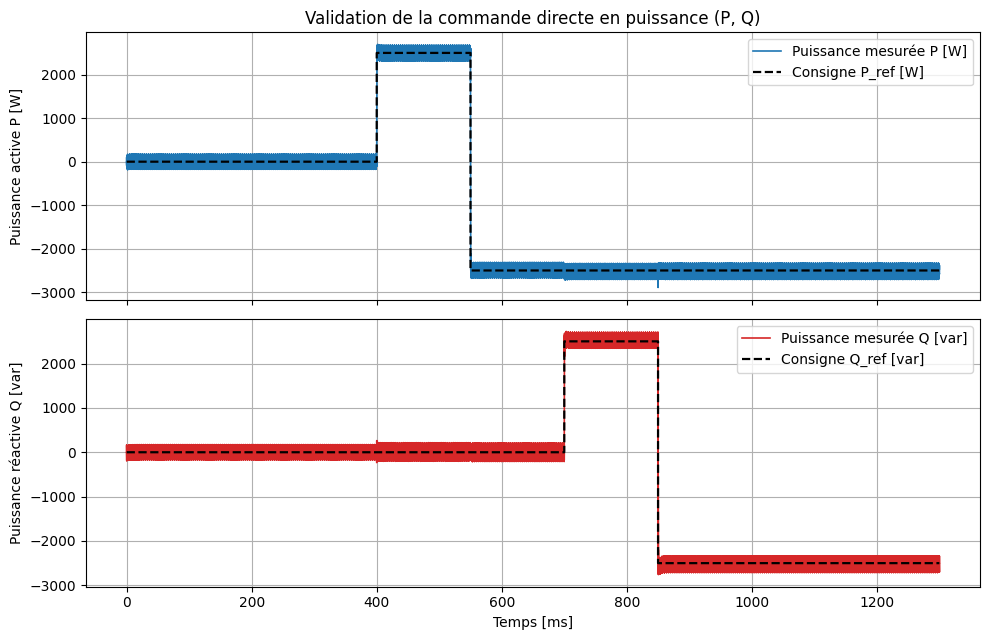

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA2_Power.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne (fiable à 100 %)
t     = df.iloc[:, 0].values  # Time / s
q_ref = df.iloc[:, 1].values  # Sum4 (Consigne Q_ref [var])
q_mes = df.iloc[:, 2].values  # Power:2 (Puissance réactive mesurée Q [var])
p_ref = df.iloc[:, 3].values  # Sum5 (Consigne P_ref [W])
p_mes = df.iloc[:, 4].values  # Power:1 (Puissance active mesurée P [W])

# 2. Tracé des courbes pour votre rapport
fig, axs = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)

# Graphe 1 : Puissance active P
axs[0].plot(t * 1000, p_mes, label="Puissance mesurée P [W]", color="tab:blue", linewidth=1.2)
axs[0].plot(t * 1000, p_ref, label="Consigne P_ref [W]", color="black", linestyle="--", linewidth=1.6)
axs[0].set_ylabel("Puissance active P [W]")
axs[0].set_title("Validation de la commande directe en puissance (P, Q)")
axs[0].grid(True)
axs[0].legend(loc="upper right")

# Graphe 2 : Puissance réactive Q
axs[1].plot(t * 1000, q_mes, label="Puissance mesurée Q [var]", color="tab:red", linewidth=1.2)
axs[1].plot(t * 1000, q_ref, label="Consigne Q_ref [var]", color="black", linestyle="--", linewidth=1.6)
axs[1].set_ylabel("Puissance réactive Q [var]")
axs[1].set_xlabel("Temps [ms]")
axs[1].grid(True)
axs[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


## 2.3 Boucle de tension du bus DC

Lors de la régulation de la tension du Bus DC, on remplace la source de tension par une source de courant ainsi qu'un condensateur en parallèle de la source. Dans le sous-système "Control", il faut bien faire attention à mettre le switch vers le DC-link control.

<div align="center">

<img src="PartA3_circuit.png" width="750">

<p style="text-align:center;"><em>Figure - AFE adapté pour la régulation de tension.</em></p>

</div>

<div style="display:flex; justify-content:center; gap:20px;">
<div style="text-align:center;"><img src="PartA3_Control.png" width="900"><br><em>(a) Bloc de contrôle</em></div>
<div style="text-align:center;"><img src="PartA3_RegulTension.png" width="300"><br><em>(b) Boucle de régulation de tension (VDC).</em></div>
</div>
<p style="text-align:center;"><em>Figure — Structure de la boucle de régulation de tension (VDC).</em></p>

In [10]:

import math

# Parametres du modele
VDC = 800.0
C_DC = 1e-3
f_sw = 20e3

V_grid = 230 * math.sqrt(2)
Sn = 10e3
Un = V_grid / math.sqrt(2)
In = Sn / (3 * Un)
In_max = In * math.sqrt(2)

# Regulateur de courant existant
KP_I = 44.5333
Ki_i = 148444.44

# Constantes de temps selon la methode utilisee
T_CM = 1 / (2 * f_sw)
T_I_CURRENT = 4 * T_CM
T_PE = T_I_CURRENT + T_CM

# Dimensionnement du regulateur de tension
T_n = 16 * T_PE

T_i_v = (
    96 * In_max * V_grid
    / (C_DC * VDC**2)
    * T_PE**2
)

Kp_v_ref = T_n / T_i_v
Ki_v_ref = 1 / T_i_v

# Gains finaux
Kp_v = (In_max / VDC) * Kp_v_ref
Ki_v = (In_max / VDC) * Ki_v_ref

print(f"Kp_v = {Kp_v:.4f}")
print(f"Ki_v = {Ki_v:.2f}")

print("\nA reporter dans MATLAB :")
print(f"Kp_v = {Kp_v:.4f};")
print(f"Ki_v = {Ki_v:.2f};")


Kp_v = 3.2793
Ki_v = 1639.67

A reporter dans MATLAB :
Kp_v = 3.2793;
Ki_v = 1639.67;


### Problèmes rencontrés lors du réglage du régulateur de tension du bus continu

#### 1. Contexte et objectif

Lors du dimensionnement du régulateur de tension du bus continu (*DC-link voltage controller*), nous avons cherché à déterminer les gains proportionnel et intégral $K_{p,v}$ et $K_{i,v}$ à partir des paramètres physiques du système et de la méthode présentée dans le cours.

Les paramètres utilisés sont notamment :

- Tension du bus continu : $V_{DC}=800\,\mathrm{V}$
- Capacité du bus continu : $C_{DC}=1\,\mathrm{mF}$
- Fréquence de commutation : $f_{sw}=20\,\mathrm{kHz}$
- Puissance nominale : $S_n=10\,\mathrm{kVA}$
- Tension efficace du réseau par phase : $U_n=230\,\mathrm{V}$

Les gains du régulateur de courant ont été conservés :
$$
K_{p,i}=44.5333
$$
$$
K_{i,i}=148444.44
$$

L'objectif était d'obtenir des gains de régulation de tension adaptés au modèle de simulation, tout en conservant le fonctionnement de la boucle de courant déjà réglée.

#### 2. Problème n° 1 : les gains calculés semblaient tous nuls

##### Symptôme observé

Lors de l'exécution du script Python, les gains calculés étaient affichés sous la forme :

```text
Kp_v_ref = 0.0000
Ki_v_ref = 0.00

Kp_v = 0.00000
Ki_v = 0.000
```

Cette observation pouvait laisser penser que les formules conduisaient à des gains nuls.

##### Analyse du problème

Le formatage utilisé dans les instructions `print()` limitait le nombre de décimales affichées. Par exemple :

```python
print(f"Kp_v = {Kp_v:.5f}")
```

Le format `.5f` affiche cinq chiffres après la virgule. Une valeur très petite peut donc apparaître égale à zéro alors qu'elle est non nulle.

##### Solution

Nous avons utilisé la notation scientifique afin d'afficher les valeurs avec une meilleure résolution :

```python
print(f"Kp_v = {Kp_v:.8e}")
print(f"Ki_v = {Ki_v:.8e}")
```

Cette modification permet de distinguer un gain réellement nul d'un gain simplement trop petit pour être visible avec le format d'affichage choisi.

**Résultat :** le problème d'affichage a été identifié. Toutefois, cette correction ne modifie pas les gains calculés et ne garantit pas que le dimensionnement soit correct.

#### 3. Problème n° 2 : incohérences dans les constantes de temps

##### Symptôme observé

Les premières simulations et les calculs intermédiaires ont mis en évidence des valeurs de constantes de temps très différentes selon les formules utilisées.

La formule initialement implémentée pour la constante de temps associée au régulateur de courant était :

```python
T_CM = 3 / (2 * f_sw)
T_I_CURRENT = KP_I / (4 * T_CM)
T_PE = T_I_CURRENT + T_CM
```

Avec $f_{sw}=20\,\mathrm{kHz}$, on obtient :

$$
T_{CM}=75\,\mu\mathrm{s}
$$

Puis :

$$
T_{I,\mathrm{current}}
=\frac{44.5333}{4\cdot75\cdot10^{-6}}
\approx148444.3\,\mathrm{s}
$$

Cette valeur est très élevée par rapport aux constantes de temps attendues pour le système.

##### Analyse du problème

La formule de calcul de $T_{I,\mathrm{current}}$ doit être distinguée de la définition de $T_i$ donnée dans le cours.

La relation communiquée pendant le laboratoire était :

$$
T_i=4T_{CM}
$$

$$
T_{I,\mathrm{current}}=\frac{K_{p,i}}{T_i}
$$

Il faut donc conserver ces deux relations distinctes dans l'implémentation et vérifier également la définition de $T_{CM}$ utilisée dans le cours.

Une confusion entre $T_i$, $T_{I,\mathrm{current}}$ et $T_{CM}$ peut entraîner des constantes de temps incorrectes et, par conséquent, des gains de régulation inadaptés.

##### Solution et précaution

Nous avons comparé différentes implémentations des constantes de temps afin d'identifier l'origine des écarts numériques.

Avant de considérer le dimensionnement comme validé, les expressions doivent être confrontées aux équations exactes du cours. La relation $T_{I,\mathrm{current}}=4T_{CM}$ ne doit notamment pas être substituée à $T_{I,\mathrm{current}}=K_{p,i}/T_i$ sans justification.

#### 4. Problème n° 3 : différences entre les formules des gains de référence

##### Formules initialement utilisées

Le premier script calculait les gains de référence selon les expressions suivantes :

$$
K_{p,v,\mathrm{ref}}=\frac{C_{DC}}{2T_{PE}}
$$

$$
K_{i,v,\mathrm{ref}}=\frac{K_{p,v,\mathrm{ref}}}{T_{i,v}}
$$

avec :

$$
T_{i,v}=
\frac{96I_{n,\max}V_{\mathrm{grid}}}
{C_{DC}V_{DC}^{2}}
T_{PE}^{2}
$$

Les gains étaient ensuite multipliés par $I_{n,\max}/V_{DC}$, puis divisés par un facteur de réduction égal à 100.

##### Analyse du problème

Au cours du débogage, nous avons constaté que les résultats dépendaient fortement des expressions retenues pour les gains de référence et des facteurs d'échelle appliqués.

Une autre version du calcul a utilisé :

$$
T_n=16T_{PE}
$$

$$
K_{p,v,\mathrm{ref}}=\frac{T_n}{T_{i,v}}
$$

$$
K_{i,v,\mathrm{ref}}=\frac{1}{T_{i,v}}
$$

avec les gains finaux calculés par :

$$
K_{p,v}=\frac{I_{n,\max}}{V_{DC}}K_{p,v,\mathrm{ref}}
$$

$$
K_{i,v}=\frac{I_{n,\max}}{V_{DC}}K_{i,v,\mathrm{ref}}
$$

Cette variante a conduit aux résultats numériques suivants :

$$
K_{p,v}\approx3.2793
$$

$$
K_{i,v}\approx1639.67
$$

Ces valeurs correspondent à cette variante des formules et des constantes de temps. Elles ne constituent pas, à elles seules, une validation théorique du dimensionnement.

##### Solution retenue pour la poursuite des essais

Nous avons conservé cette variante comme point de comparaison numérique pour les essais, car elle permet de vérifier les ordres de grandeur obtenus et leur influence sur la simulation.

Les expressions des gains de référence, la définition de $T_{CM}$ et les facteurs d'échelle doivent néanmoins être vérifiés à partir du support de cours avant de présenter ces valeurs comme les gains définitifs du régulateur.

#### 5. Vérification du comportement en simulation

Après le réglage de la boucle de tension, nous avons observé la réponse du bus continu dans le Scope de MATLAB/Simulink.

La consigne passe de $750\,\mathrm{V}$ à $800\,\mathrm{V}$, et la tension mesurée suit cette variation. La tension reste ensuite proche de sa consigne, malgré de petites perturbations périodiques visibles sur le graphe.

Cette observation est encourageante : elle montre que le système simulé parvient à suivre la consigne dans les conditions de l'essai.

Cependant, la seule forme de la réponse ne permet pas de confirmer que les gains sont optimaux ou que toutes les exigences de stabilité et de robustesse sont satisfaites. Les pointes périodiques doivent également être analysées pour déterminer si elles proviennent de la commutation, de la mesure ou d'un autre phénomène du modèle.

#### 6. Conclusion et recommandations pour une reprise du projet

Les principales difficultés rencontrées ont été :

1. Un affichage numérique masquant les petits gains à cause d'un nombre insuffisant de décimales.
2. Des ambiguïtés dans l'implémentation des constantes de temps.
3. Des différences entre les formules utilisées pour les gains de référence et les facteurs d'échelle appliqués.
4. La nécessité de distinguer un résultat numérique plausible d'un dimensionnement théoriquement validé.

Pour reprendre le projet, il est recommandé de :

- Conserver les gains de la boucle de courant déjà validée.
- Vérifier les définitions de $T_{CM}$, $T_i$, $T_{I,\mathrm{current}}$ et $T_{PE}$ dans le cours.
- Contrôler les unités de chaque grandeur et les facteurs de normalisation des signaux.
- Afficher les résultats intermédiaires en notation scientifique.
- Comparer les gains calculés avec la réponse temporelle du bus continu.
- Documenter les modifications une par une afin de pouvoir identifier leur effet sur la simulation.

### 2.3.3 Validation

--- Saut de consigne à t = 650.0 ms (750 V -> 800 V) ---
Temps de réponse (95 %) : 18.23 ms
Dépassement maximal     : 19.33 V (38.7 %)
Erreur statique         : -0.005 V


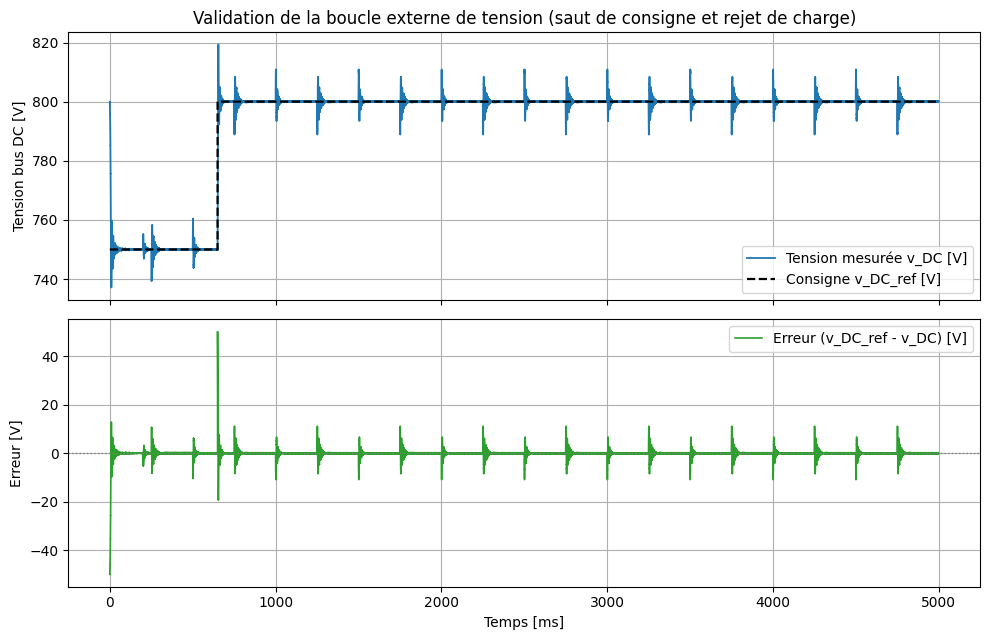

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA3_consigneTension.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne (fiable à 100 %)
t       = df.iloc[:, 0].values  # Time / s
vdc_mes = df.iloc[:, 1].values  # Vm2:Measured voltage (v_DC mesurée [V])
vdc_ref = df.iloc[:, 2].values  # Step (Consigne v_DC_ref [V])
erreur  = df.iloc[:, 3].values  # Sum4 (Erreur v_DC_ref - v_DC [V])

# 2. Analyse automatique du saut de consigne (Step)
diff_v = np.abs(np.diff(vdc_ref))
if np.max(diff_v) > 1.0:
    idx_step = np.argmax(diff_v) + 1
    t_step   = t[idx_step]
    val_init = vdc_ref[idx_step - 1]
    val_fin  = vdc_ref[idx_step]
    delta_v  = val_fin - val_init

    # On analyse jusqu'au prochain échelon de charge (par ex. 90 ms après le saut)
    # pour ne pas fausser le dépassement avec les perturbations de charge ultérieures
    idx_fin_analyse = np.argmin(np.abs(t - (t_step + 0.090)))
    t_zone   = t[idx_step:idx_fin_analyse]
    v_zone   = vdc_mes[idx_step:idx_fin_analyse]

    # Temps de réponse à 95 % (bande des +-5 % autour du saut delta_v)
    err_rel = np.abs(v_zone - val_fin) / np.abs(delta_v)
    hors_bande = np.where(err_rel > 0.05)[0]
    tr_95 = (t_zone[hors_bande[-1] + 1] - t_step) * 1000 if len(hors_bande) > 0 and hors_bande[-1] + 1 < len(t_zone) else 0.0

    # Dépassement maximal (% et V)
    if delta_v > 0:
        pic = np.max(v_zone)
        depassement_v = max(0.0, pic - val_fin)
    else:
        pic = np.min(v_zone)
        depassement_v = max(0.0, val_fin - pic)
    depassement_pct = (depassement_v / np.abs(delta_v)) * 100

    # Erreur statique juste avant la perturbation suivante
    n_palier = int(0.8 * len(v_zone))
    err_stat = np.mean(val_fin - v_zone[n_palier:])

    print(f"--- Saut de consigne à t = {t_step*1000:.1f} ms ({val_init:.0f} V -> {val_fin:.0f} V) ---")
    print(f"Temps de réponse (95 %) : {tr_95:.2f} ms")
    print(f"Dépassement maximal     : {depassement_v:.2f} V ({depassement_pct:.1f} %)")
    print(f"Erreur statique         : {err_stat:.3f} V")

# 3. Tracé des courbes pour le rapport
fig, axs = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)

# Graphe 1 : Tension bus DC vs Consigne
axs[0].plot(t * 1000, vdc_mes, label="Tension mesurée v_DC [V]", color="tab:blue", linewidth=1.3)
axs[0].plot(t * 1000, vdc_ref, label="Consigne v_DC_ref [V]", color="black", linestyle="--", linewidth=1.6)
axs[0].set_ylabel("Tension bus DC [V]")
axs[0].set_title("Validation de la boucle externe de tension (saut de consigne et rejet de charge)")
axs[0].grid(True)
axs[0].legend(loc="best")

# Graphe 2 : Erreur de régulation (Sum4)
axs[1].plot(t * 1000, erreur, label="Erreur (v_DC_ref - v_DC) [V]", color="tab:green", linewidth=1.2)
axs[1].axhline(0, color="gray", linestyle=":", linewidth=1)
axs[1].set_ylabel("Erreur [V]")
axs[1].set_xlabel("Temps [ms]")
axs[1].grid(True)
axs[1].legend(loc="best")

plt.tight_layout()
plt.show()


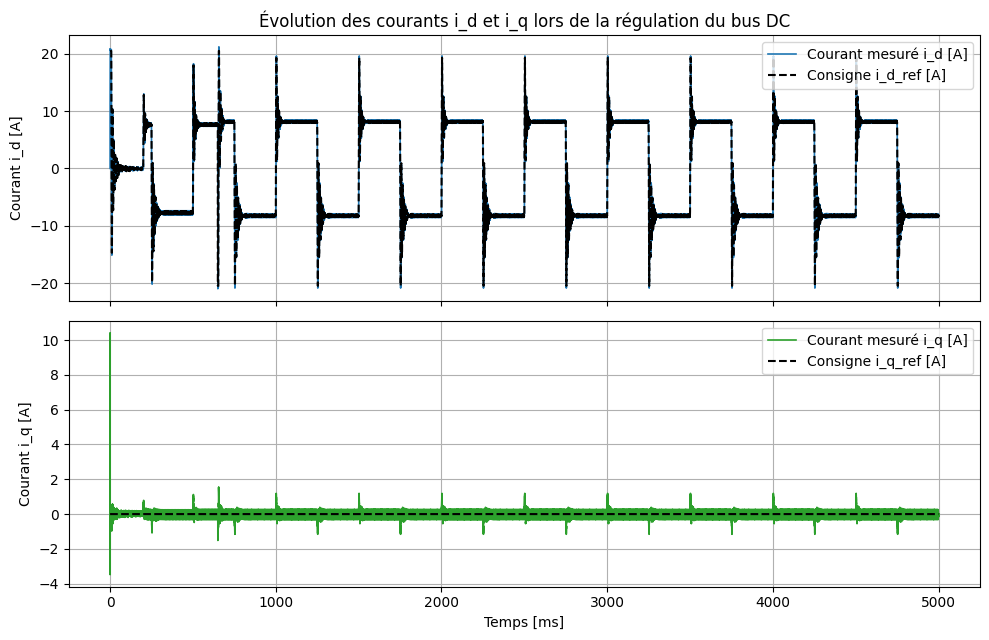

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA3_Id.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne (fiable à 100 %)
t      = df.iloc[:, 0].values  # Time / s
id_mes = df.iloc[:, 1].values  # 3ph->RRF:1 (i_d mesuré [A])
id_ref = df.iloc[:, 2].values  # Manual Switch:1 (Consigne i_d_ref [A])
iq_mes = df.iloc[:, 3].values  # 3ph->RRF:2 (i_q mesuré [A])
iq_ref = df.iloc[:, 4].values  # Manual Switch:2 (Consigne i_q_ref [A])

# 2. Tracé des courbes pour le rapport
fig, axs = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)

# Graphe 1 : Courant d'axe direct i_d
axs[0].plot(t * 1000, id_mes, label="Courant mesuré i_d [A]", color="tab:blue", linewidth=1.2)
axs[0].plot(t * 1000, id_ref, label="Consigne i_d_ref [A]", color="black", linestyle="--", linewidth=1.5)
axs[0].set_ylabel("Courant i_d [A]")
axs[0].set_title("Évolution des courants i_d et i_q lors de la régulation du bus DC")
axs[0].grid(True)
axs[0].legend(loc="upper right")

# Graphe 2 : Courant d'axe en quadrature i_q
axs[1].plot(t * 1000, iq_mes, label="Courant mesuré i_q [A]", color="tab:green", linewidth=1.2)
axs[1].plot(t * 1000, iq_ref, label="Consigne i_q_ref [A]", color="black", linestyle="--", linewidth=1.5)
axs[1].set_ylabel("Courant i_q [A]")
axs[1].set_xlabel("Temps [ms]")
axs[1].grid(True)
axs[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


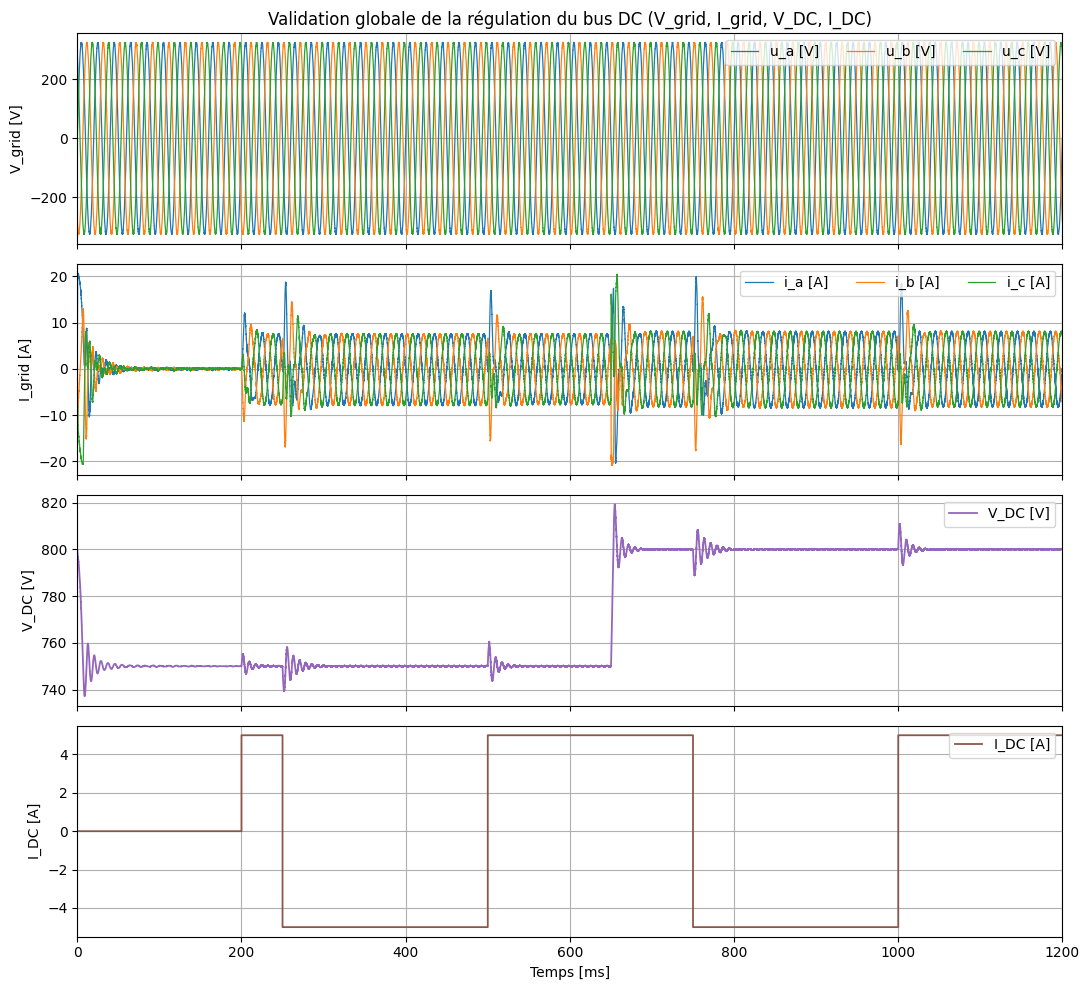

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA3_Idc.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t   = df.iloc[:, 0].values
ua  = df.iloc[:, 1].values
ub  = df.iloc[:, 2].values
uc  = df.iloc[:, 3].values
ia  = df.iloc[:, 4].values
ib  = df.iloc[:, 5].values
ic  = df.iloc[:, 6].values
vdc = df.iloc[:, 7].values
idc = df.iloc[:, 8].values

# 2. Tracé des 4 grandeurs (V_grid, I_grid, V_DC, I_DC)
fig, axs = plt.subplots(4, 1, figsize=(11, 10), sharex=True)

# Graphe 1 : Tension réseau V_grid
axs[0].plot(t * 1000, ua, label="u_a [V]", linewidth=0.9)
axs[0].plot(t * 1000, ub, label="u_b [V]", linewidth=0.9)
axs[0].plot(t * 1000, uc, label="u_c [V]", linewidth=0.9)
axs[0].set_ylabel("V_grid [V]")
axs[0].set_title("Validation globale de la régulation du bus DC (V_grid, I_grid, V_DC, I_DC)")
axs[0].grid(True)
axs[0].legend(loc="upper right", ncol=3)

# Graphe 2 : Courant réseau I_grid
axs[1].plot(t * 1000, ia, label="i_a [A]", linewidth=0.9)
axs[1].plot(t * 1000, ib, label="i_b [A]", linewidth=0.9)
axs[1].plot(t * 1000, ic, label="i_c [A]", linewidth=0.9)
axs[1].set_ylabel("I_grid [A]")
axs[1].grid(True)
axs[1].legend(loc="upper right", ncol=3)

# Graphe 3 : Tension bus DC V_DC
axs[2].plot(t * 1000, vdc, label="V_DC [V]", color="tab:purple", linewidth=1.3)
axs[2].set_ylabel("V_DC [V]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

# Graphe 4 : Courant bus DC I_DC
axs[3].plot(t * 1000, idc, label="I_DC [A]", color="tab:brown", linewidth=1.3)
axs[3].set_ylabel("I_DC [A]")
axs[3].set_xlabel("Temps [ms]")
axs[3].grid(True)
axs[3].legend(loc="upper right")

# Optionnel : décommentez la ligne ci-dessous pour zoomer sur les premières 1200 ms
plt.xlim(0, 1200)

plt.tight_layout()
plt.show()


Les essais réalisés avec le condensateur C<sub>DC</sub> et la source de courant de charge i<sub>load</sub> (i<sub>DC</sub>) valident le comportement de la régulation en cascade :

* **Suivi de consigne (750 V → 800 V à t = 0.65 s) :** La tension v<sub>DC</sub> atteint sa nouvelle consigne avec un dépassement transitoire d'environ 18 V (cohérent avec le dimensionnement selon le critère symétrique) et une erreur statique nulle grâce à l'action intégrale du PI.
* **Échelons de charge (charge ↔ repos ↔ restitution) :** Après une phase à vide (0 A jusqu'à t = 0.2 s), le courant i<sub>DC</sub> alterne entre +5 A (absorption) et -5 A (restitution au réseau). Chaque transition (Δi<sub>DC</sub> = ±10 A) provoque un creux ou une surtension limité à environ ±10 V (≈ 1.25 % de V<sub>DC</sub>), rapidement rejeté.
* **Séparation des dynamiques :** La boucle interne de courant (i<sub>d</sub>, qui bascule entre +8.2 A et -8.2 A avec i<sub>q</sub> = 0 A) réagit en quelques millisecondes aux échelons de charge, soit nettement plus vite que l'enveloppe lente de la tension v<sub>DC</sub> (quelques dizaines de millisecondes), garantissant la stabilité du système.


## 2.4 Etudes paramétriques

### 2.4.1 Réseau fort / réseau faible

#### Réseau fort ($L_{grid} = 20 \cdot 10^6$)

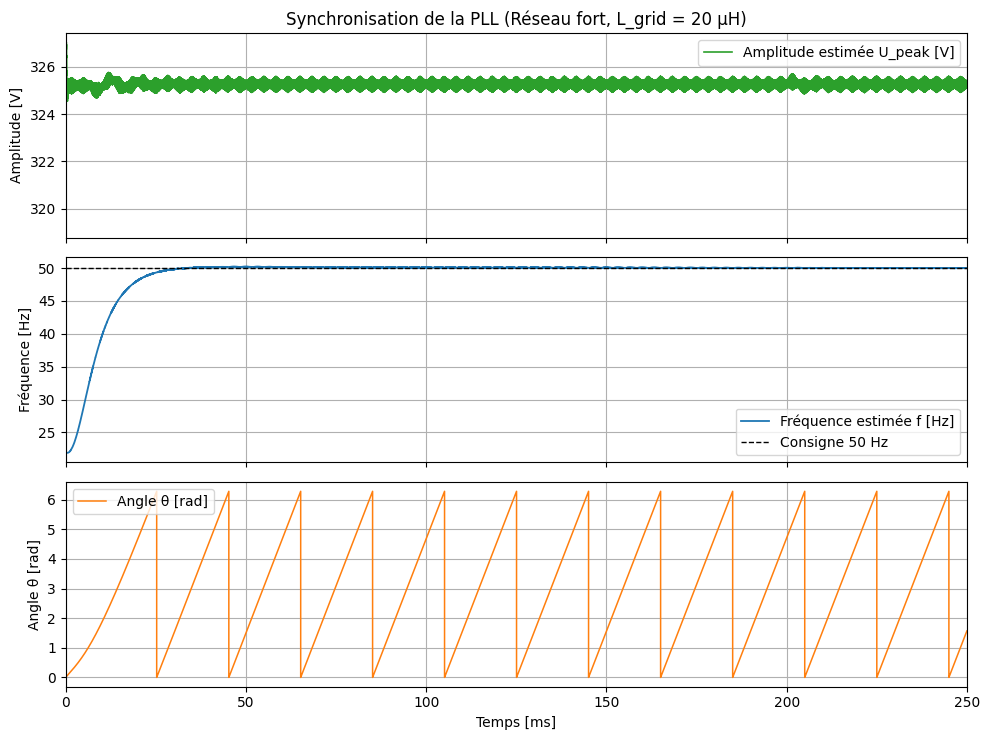

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA4_Rfort.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t     = df.iloc[:, 0].values  # Time / s
amp   = df.iloc[:, 1].values  # Three-Phase PLL:amplitude [V]
freq  = df.iloc[:, 2].values  # Three-Phase PLL:w (déjà en Hz sur vos scopes : 22 -> 50 Hz)
theta = df.iloc[:, 3].values  # Three-Phase PLL:theta [rad]

# 2. Tracé des 3 grandeurs de la PLL
fig, axs = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)

# Graphe 1 : Amplitude crête U_peak
axs[0].plot(t * 1000, amp, label="Amplitude estimée U_peak [V]", color="tab:green", linewidth=1.2)
axs[0].set_ylabel("Amplitude [V]")
axs[0].set_title("Synchronisation de la PLL (Réseau fort, L_grid = 20 µH)")
axs[0].grid(True)
axs[0].legend(loc="best")

# Graphe 2 : Fréquence f
axs[1].plot(t * 1000, freq, label="Fréquence estimée f [Hz]", color="tab:blue", linewidth=1.3)
axs[1].axhline(50, color="black", linestyle="--", linewidth=1, label="Consigne 50 Hz")
axs[1].set_ylabel("Fréquence [Hz]")
axs[1].grid(True)
axs[1].legend(loc="best")

# Graphe 3 : Angle theta
axs[2].plot(t * 1000, theta, label="Angle θ [rad]", color="tab:orange", linewidth=1.1)
axs[2].set_ylabel("Angle θ [rad]")
axs[2].set_xlabel("Temps [ms]")
axs[2].grid(True)
axs[2].legend(loc="best")

# Optionnel : décommentez pour zoomer sur les premières 500 ms (comme sur votre capture)
plt.xlim(0, 250)

plt.tight_layout()
plt.show()


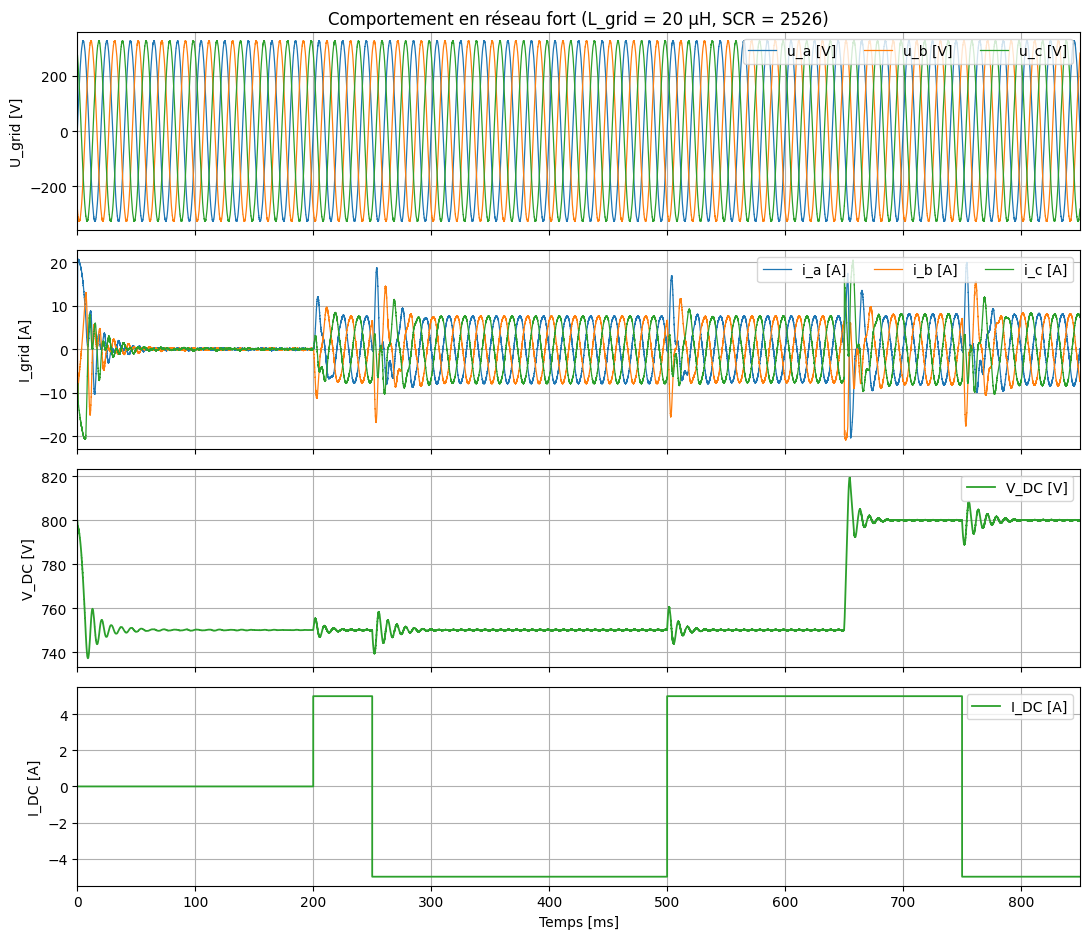

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA4_Rfort_Ugrid.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t   = df.iloc[:, 0].values
ua  = df.iloc[:, 1].values
ub  = df.iloc[:, 2].values
uc  = df.iloc[:, 3].values
ia  = df.iloc[:, 4].values
ib  = df.iloc[:, 5].values
ic  = df.iloc[:, 6].values
vdc = df.iloc[:, 7].values
idc = df.iloc[:, 8].values

# 2. Tracé des 4 grandeurs (U_grid, I_grid, V_DC, I_DC)
fig, axs = plt.subplots(4, 1, figsize=(11, 9.5), sharex=True)

# Graphe 1 : Tension réseau U_grid
axs[0].plot(t * 1000, ua, label="u_a [V]", linewidth=0.9)
axs[0].plot(t * 1000, ub, label="u_b [V]", linewidth=0.9)
axs[0].plot(t * 1000, uc, label="u_c [V]", linewidth=0.9)
axs[0].set_ylabel("U_grid [V]")
axs[0].set_title("Comportement en réseau fort (L_grid = 20 µH, SCR = 2526)")
axs[0].grid(True)
axs[0].legend(loc="upper right", ncol=3)

# Graphe 2 : Courant réseau I_grid
axs[1].plot(t * 1000, ia, label="i_a [A]", linewidth=0.9)
axs[1].plot(t * 1000, ib, label="i_b [A]", linewidth=0.9)
axs[1].plot(t * 1000, ic, label="i_c [A]", linewidth=0.9)
axs[1].set_ylabel("I_grid [A]")
axs[1].grid(True)
axs[1].legend(loc="upper right", ncol=3)

# Graphe 3 : Tension bus DC V_DC
axs[2].plot(t * 1000, vdc, label="V_DC [V]", color="tab:green", linewidth=1.3)
axs[2].set_ylabel("V_DC [V]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

# Graphe 4 : Courant bus DC I_DC
axs[3].plot(t * 1000, idc, label="I_DC [A]", color="tab:green", linewidth=1.3)
axs[3].set_ylabel("I_DC [A]")
axs[3].set_xlabel("Temps [ms]")
axs[3].grid(True)
axs[3].legend(loc="upper right")

# Zoom sur 0 à 850 ms pour bien distinguer les sinusoïdes (à commenter si besoin)
plt.xlim(0, 850)

plt.tight_layout()
plt.show()


#### Réseau faible ($L_{grid} = 1 \cdot 10^{-3} H$)

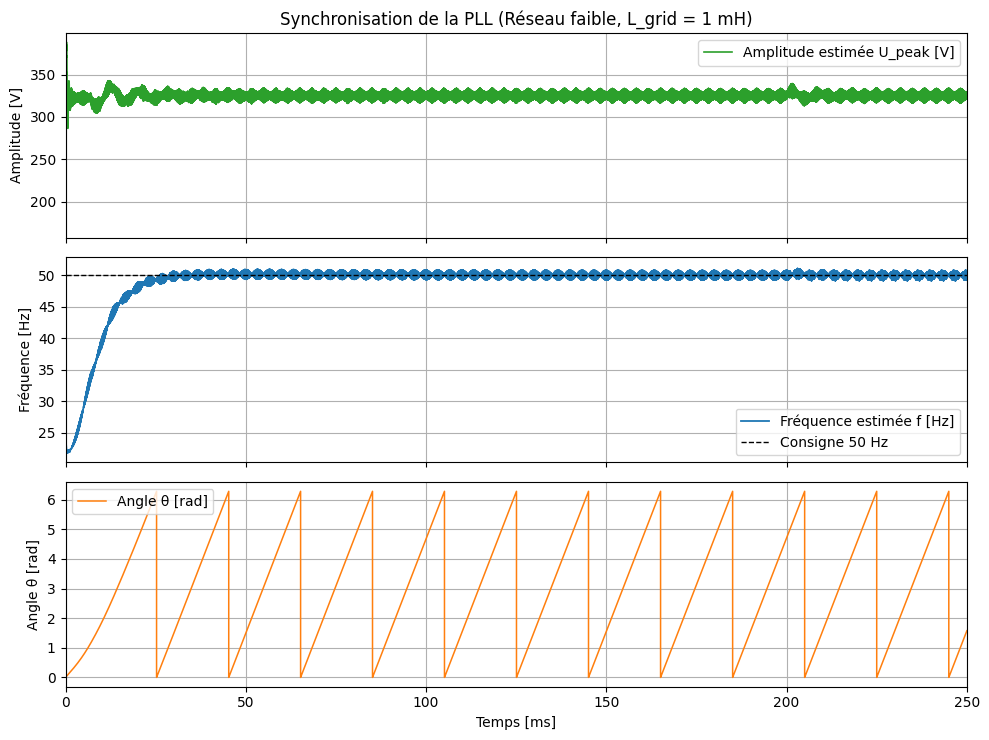

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA4_Rfaible_Ugrid.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t     = df.iloc[:, 0].values  # Time / s
amp   = df.iloc[:, 1].values  # Three-Phase PLL:amplitude [V]
freq  = df.iloc[:, 2].values  # Three-Phase PLL:w (déjà en Hz sur vos scopes : 22 -> 50 Hz)
theta = df.iloc[:, 3].values  # Three-Phase PLL:theta [rad]

# 2. Tracé des 3 grandeurs de la PLL
fig, axs = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)

# Graphe 1 : Amplitude crête U_peak
axs[0].plot(t * 1000, amp, label="Amplitude estimée U_peak [V]", color="tab:green", linewidth=1.2)
axs[0].set_ylabel("Amplitude [V]")
axs[0].set_title("Synchronisation de la PLL (Réseau faible, L_grid = 1 mH)")
axs[0].grid(True)
axs[0].legend(loc="best")

# Graphe 2 : Fréquence f
axs[1].plot(t * 1000, freq, label="Fréquence estimée f [Hz]", color="tab:blue", linewidth=1.3)
axs[1].axhline(50, color="black", linestyle="--", linewidth=1, label="Consigne 50 Hz")
axs[1].set_ylabel("Fréquence [Hz]")
axs[1].grid(True)
axs[1].legend(loc="best")

# Graphe 3 : Angle theta
axs[2].plot(t * 1000, theta, label="Angle θ [rad]", color="tab:orange", linewidth=1.1)
axs[2].set_ylabel("Angle θ [rad]")
axs[2].set_xlabel("Temps [ms]")
axs[2].grid(True)
axs[2].legend(loc="best")

# Optionnel : décommentez pour zoomer sur les premières 500 ms (comme sur votre capture)
plt.xlim(0, 250)

plt.tight_layout()
plt.show()


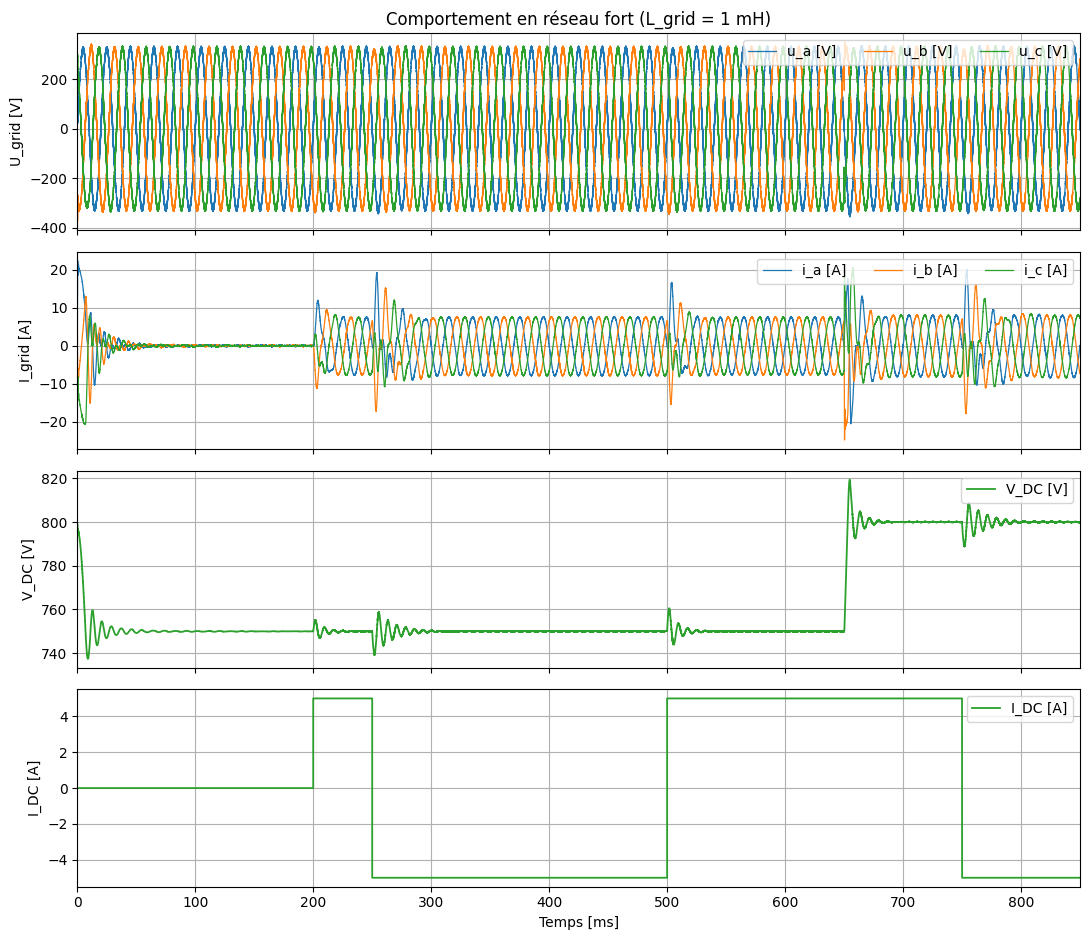

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA4_Rfaible_VraiUgrid.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t   = df.iloc[:, 0].values
ua  = df.iloc[:, 1].values
ub  = df.iloc[:, 2].values
uc  = df.iloc[:, 3].values
ia  = df.iloc[:, 4].values
ib  = df.iloc[:, 5].values
ic  = df.iloc[:, 6].values
vdc = df.iloc[:, 7].values
idc = df.iloc[:, 8].values

# 2. Tracé des 4 grandeurs (U_grid, I_grid, V_DC, I_DC)
fig, axs = plt.subplots(4, 1, figsize=(11, 9.5), sharex=True)

# Graphe 1 : Tension réseau U_grid
axs[0].plot(t * 1000, ua, label="u_a [V]", linewidth=0.9)
axs[0].plot(t * 1000, ub, label="u_b [V]", linewidth=0.9)
axs[0].plot(t * 1000, uc, label="u_c [V]", linewidth=0.9)
axs[0].set_ylabel("U_grid [V]")
axs[0].set_title("Comportement en réseau fort (L_grid = 1 mH)")
axs[0].grid(True)
axs[0].legend(loc="upper right", ncol=3)

# Graphe 2 : Courant réseau I_grid
axs[1].plot(t * 1000, ia, label="i_a [A]", linewidth=0.9)
axs[1].plot(t * 1000, ib, label="i_b [A]", linewidth=0.9)
axs[1].plot(t * 1000, ic, label="i_c [A]", linewidth=0.9)
axs[1].set_ylabel("I_grid [A]")
axs[1].grid(True)
axs[1].legend(loc="upper right", ncol=3)

# Graphe 3 : Tension bus DC V_DC
axs[2].plot(t * 1000, vdc, label="V_DC [V]", color="tab:green", linewidth=1.3)
axs[2].set_ylabel("V_DC [V]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

# Graphe 4 : Courant bus DC I_DC
axs[3].plot(t * 1000, idc, label="I_DC [A]", color="tab:green", linewidth=1.3)
axs[3].set_ylabel("I_DC [A]")
axs[3].set_xlabel("Temps [ms]")
axs[3].grid(True)
axs[3].legend(loc="upper right")

# Zoom sur 0 à 850 ms pour bien distinguer les sinusoïdes (à commenter si besoin)
plt.xlim(0, 850)

plt.tight_layout()
plt.show()


#### Réseau faible ($L_{grid} = 7 \cdot 10^{-3} H$)

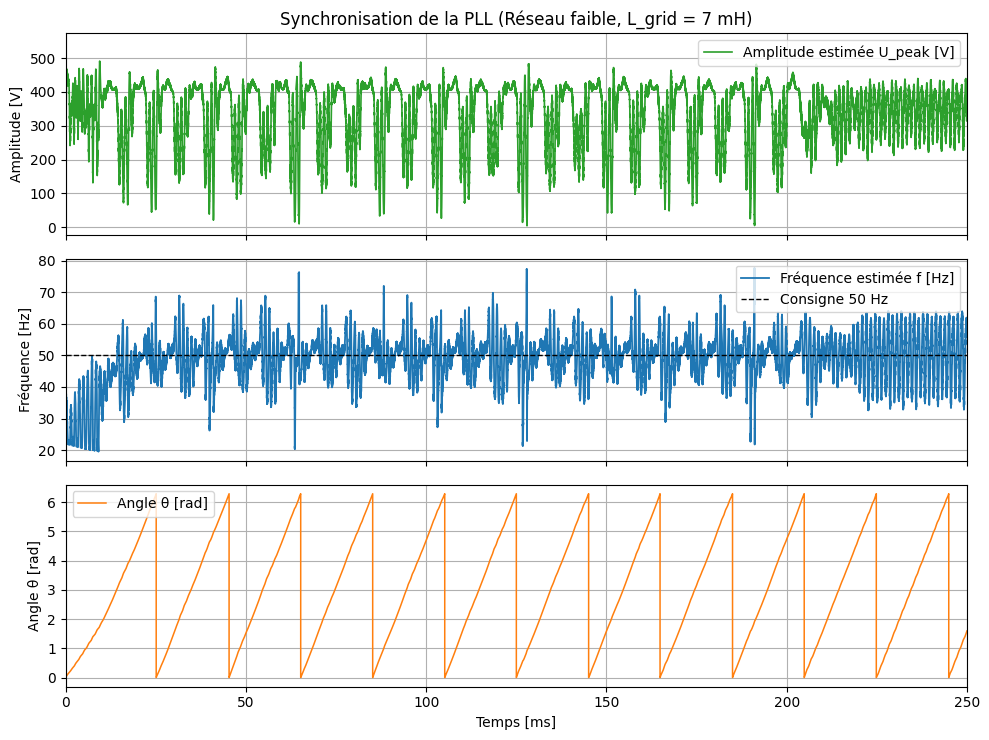

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA4_RfaibleSeuil_PLL.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t     = df.iloc[:, 0].values  # Time / s
amp   = df.iloc[:, 1].values  # Three-Phase PLL:amplitude [V]
freq  = df.iloc[:, 2].values  # Three-Phase PLL:w (déjà en Hz sur vos scopes : 22 -> 50 Hz)
theta = df.iloc[:, 3].values  # Three-Phase PLL:theta [rad]

# 2. Tracé des 3 grandeurs de la PLL
fig, axs = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)

# Graphe 1 : Amplitude crête U_peak
axs[0].plot(t * 1000, amp, label="Amplitude estimée U_peak [V]", color="tab:green", linewidth=1.2)
axs[0].set_ylabel("Amplitude [V]")
axs[0].set_title("Synchronisation de la PLL (Réseau faible, L_grid = 7 mH)")
axs[0].grid(True)
axs[0].legend(loc="best")

# Graphe 2 : Fréquence f
axs[1].plot(t * 1000, freq, label="Fréquence estimée f [Hz]", color="tab:blue", linewidth=1.3)
axs[1].axhline(50, color="black", linestyle="--", linewidth=1, label="Consigne 50 Hz")
axs[1].set_ylabel("Fréquence [Hz]")
axs[1].grid(True)
axs[1].legend(loc="best")

# Graphe 3 : Angle theta
axs[2].plot(t * 1000, theta, label="Angle θ [rad]", color="tab:orange", linewidth=1.1)
axs[2].set_ylabel("Angle θ [rad]")
axs[2].set_xlabel("Temps [ms]")
axs[2].grid(True)
axs[2].legend(loc="best")

# Optionnel : décommentez pour zoomer sur les premières 500 ms (comme sur votre capture)
plt.xlim(0, 250)

plt.tight_layout()
plt.show()


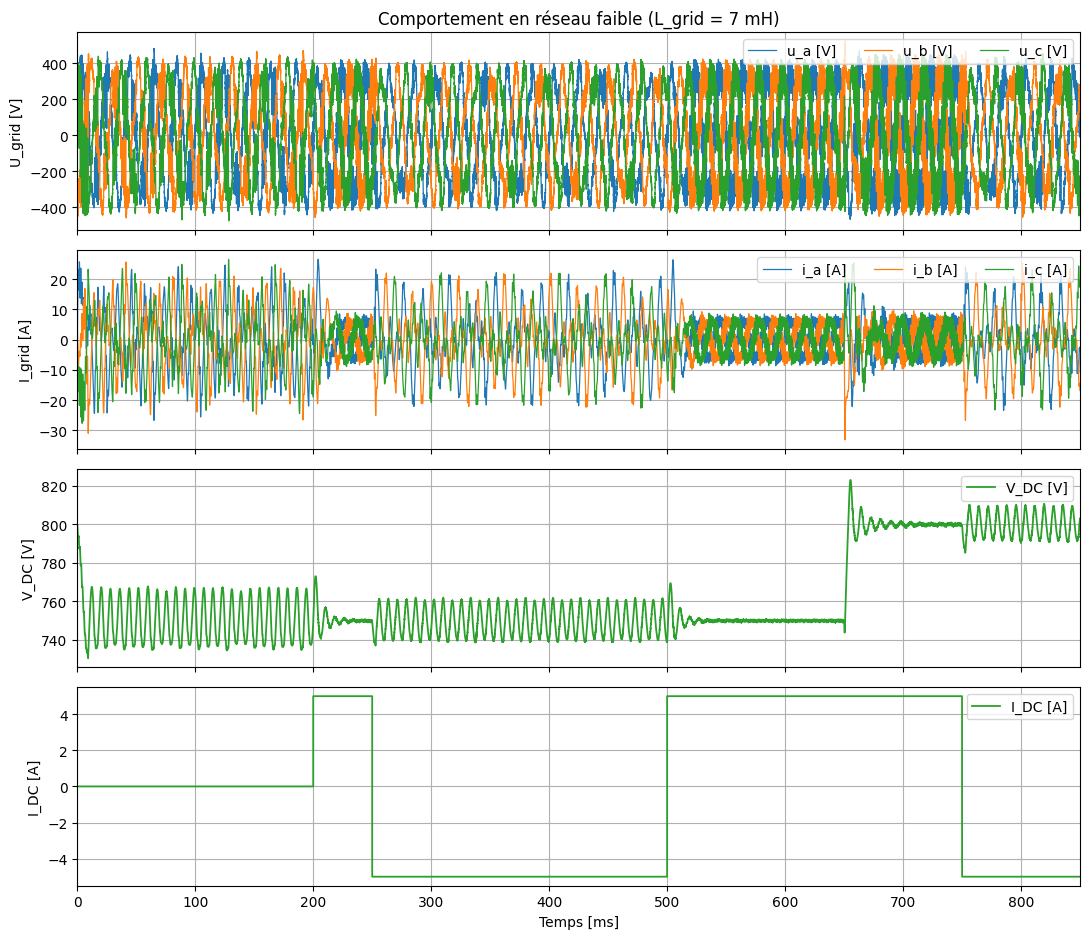

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA4_RfaibleSeuil_Ugrid.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t   = df.iloc[:, 0].values
ua  = df.iloc[:, 1].values
ub  = df.iloc[:, 2].values
uc  = df.iloc[:, 3].values
ia  = df.iloc[:, 4].values
ib  = df.iloc[:, 5].values
ic  = df.iloc[:, 6].values
vdc = df.iloc[:, 7].values
idc = df.iloc[:, 8].values

# 2. Tracé des 4 grandeurs (U_grid, I_grid, V_DC, I_DC)
fig, axs = plt.subplots(4, 1, figsize=(11, 9.5), sharex=True)

# Graphe 1 : Tension réseau U_grid
axs[0].plot(t * 1000, ua, label="u_a [V]", linewidth=0.9)
axs[0].plot(t * 1000, ub, label="u_b [V]", linewidth=0.9)
axs[0].plot(t * 1000, uc, label="u_c [V]", linewidth=0.9)
axs[0].set_ylabel("U_grid [V]")
axs[0].set_title("Comportement en réseau faible (L_grid = 7 mH)")
axs[0].grid(True)
axs[0].legend(loc="upper right", ncol=3)

# Graphe 2 : Courant réseau I_grid
axs[1].plot(t * 1000, ia, label="i_a [A]", linewidth=0.9)
axs[1].plot(t * 1000, ib, label="i_b [A]", linewidth=0.9)
axs[1].plot(t * 1000, ic, label="i_c [A]", linewidth=0.9)
axs[1].set_ylabel("I_grid [A]")
axs[1].grid(True)
axs[1].legend(loc="upper right", ncol=3)

# Graphe 3 : Tension bus DC V_DC
axs[2].plot(t * 1000, vdc, label="V_DC [V]", color="tab:green", linewidth=1.3)
axs[2].set_ylabel("V_DC [V]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

# Graphe 4 : Courant bus DC I_DC
axs[3].plot(t * 1000, idc, label="I_DC [A]", color="tab:green", linewidth=1.3)
axs[3].set_ylabel("I_DC [A]")
axs[3].set_xlabel("Temps [ms]")
axs[3].grid(True)
axs[3].legend(loc="upper right")

# Zoom sur 0 à 850 ms pour bien distinguer les sinusoïdes (à commenter si besoin)
plt.xlim(0, 850)

plt.tight_layout()
plt.show()


Afin d'évaluer la robustesse du système sans modifier les gains des régulateurs, l'inductance du réseau L<sub>grid</sub> a été augmentée pour faire décroître le ratio de court-circuit SCR (calculé avec S<sub>n</sub> = 10 kVA et U<sub>n</sub> = 230 V) :

* **Réseau fort (L<sub>grid</sub> = 20 µH, SCR = 2526 > 20) :** La tension au PCC (U<sub>grid</sub>) est lisse et exempte de bruit de commutation. La PLL maintient une fréquence collée à 50.0 Hz (U<sub>peak</sub> = 325.3 V) et les boucles de courant et de tension présentent des marges nominales.
* **Réseau intermédiaire (L<sub>grid</sub> = 1 mH, SCR = 50.5) :** Une légère ondulation à la fréquence de découpage (20 kHz) apparaît sur U<sub>grid</sub>, accompagnée de faibles fluctuations de la fréquence estimée par la PLL (±0.5 Hz) lors des transitoires. L'ensemble demeure toutefois pleinement stable.
* **Réseau faible (L<sub>grid</sub> = 7 mH, SCR = 7.2 < 8) :**
  * **Ondulation au PCC :** Le diviseur inductif formé par L<sub>grid</sub> laisse passer une forte ondulation à 20 kHz sur U<sub>grid</sub> (crêtes atteignant ±450 V).
  * **Dégradation de la synchronisation :** La distorsion et la chute de tension inductive déstabilisent la PLL (fréquence oscillant entre 35 Hz et 67 Hz, U<sub>peak</sub> variant de 100 V à 480 V).
  * **Perte de stabilité :** L'augmentation de l'inductance totale vue par le convertisseur réduit la marge de phase de la boucle de courant, déclenchant des oscillations soutenues (±25 A sur I<sub>grid</sub> et ±15 V sur V<sub>DC</sub>) dès que le système transite de la puissance.


### 2.4.2 Capacité du bus DC

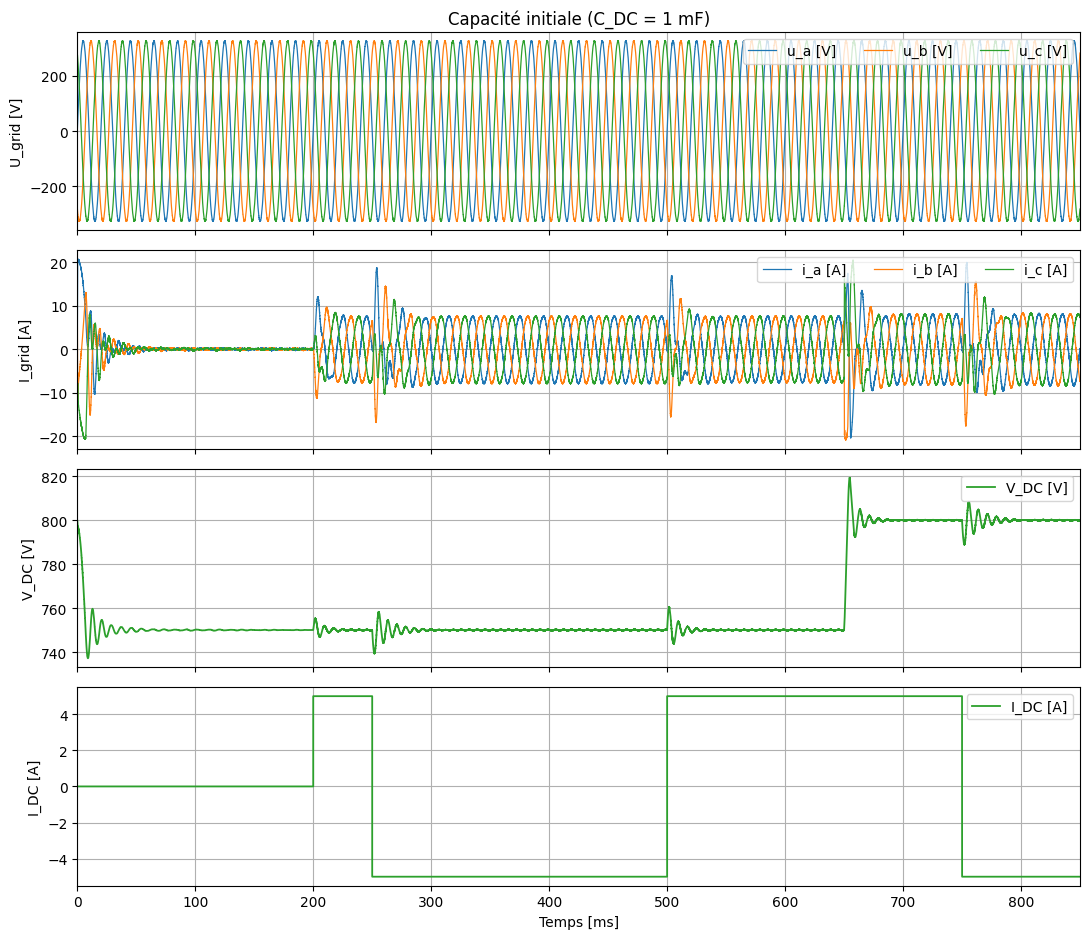

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA4_Cinitial.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t   = df.iloc[:, 0].values
ua  = df.iloc[:, 1].values
ub  = df.iloc[:, 2].values
uc  = df.iloc[:, 3].values
ia  = df.iloc[:, 4].values
ib  = df.iloc[:, 5].values
ic  = df.iloc[:, 6].values
vdc = df.iloc[:, 7].values
idc = df.iloc[:, 8].values

# 2. Tracé des 4 grandeurs (U_grid, I_grid, V_DC, I_DC)
fig, axs = plt.subplots(4, 1, figsize=(11, 9.5), sharex=True)

# Graphe 1 : Tension réseau U_grid
axs[0].plot(t * 1000, ua, label="u_a [V]", linewidth=0.9)
axs[0].plot(t * 1000, ub, label="u_b [V]", linewidth=0.9)
axs[0].plot(t * 1000, uc, label="u_c [V]", linewidth=0.9)
axs[0].set_ylabel("U_grid [V]")
axs[0].set_title("Capacité initiale (C_DC = 1 mF)")
axs[0].grid(True)
axs[0].legend(loc="upper right", ncol=3)

# Graphe 2 : Courant réseau I_grid
axs[1].plot(t * 1000, ia, label="i_a [A]", linewidth=0.9)
axs[1].plot(t * 1000, ib, label="i_b [A]", linewidth=0.9)
axs[1].plot(t * 1000, ic, label="i_c [A]", linewidth=0.9)
axs[1].set_ylabel("I_grid [A]")
axs[1].grid(True)
axs[1].legend(loc="upper right", ncol=3)

# Graphe 3 : Tension bus DC V_DC
axs[2].plot(t * 1000, vdc, label="V_DC [V]", color="tab:green", linewidth=1.3)
axs[2].set_ylabel("V_DC [V]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

# Graphe 4 : Courant bus DC I_DC
axs[3].plot(t * 1000, idc, label="I_DC [A]", color="tab:green", linewidth=1.3)
axs[3].set_ylabel("I_DC [A]")
axs[3].set_xlabel("Temps [ms]")
axs[3].grid(True)
axs[3].legend(loc="upper right")

# Zoom sur 0 à 850 ms pour bien distinguer les sinusoïdes (à commenter si besoin)
plt.xlim(0, 850)

plt.tight_layout()
plt.show()


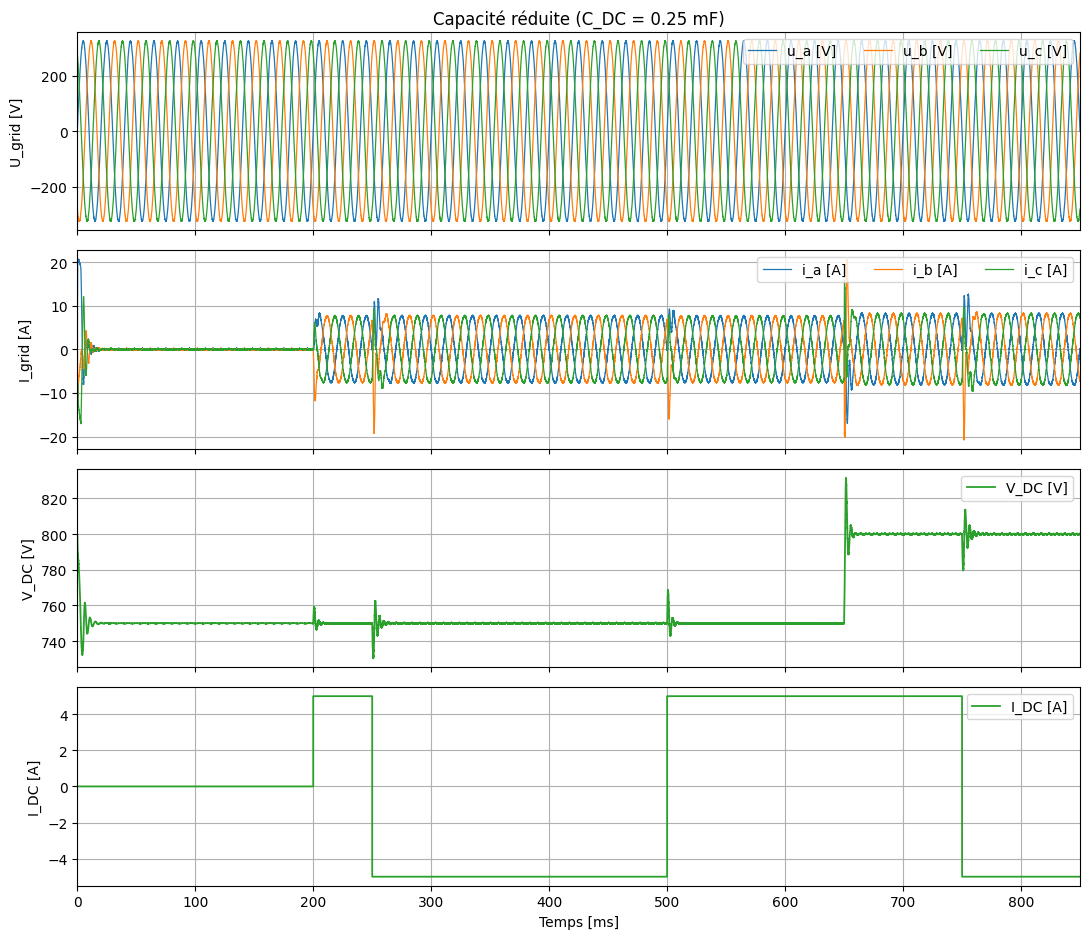

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA4_Créduit.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t   = df.iloc[:, 0].values
ua  = df.iloc[:, 1].values
ub  = df.iloc[:, 2].values
uc  = df.iloc[:, 3].values
ia  = df.iloc[:, 4].values
ib  = df.iloc[:, 5].values
ic  = df.iloc[:, 6].values
vdc = df.iloc[:, 7].values
idc = df.iloc[:, 8].values

# 2. Tracé des 4 grandeurs (U_grid, I_grid, V_DC, I_DC)
fig, axs = plt.subplots(4, 1, figsize=(11, 9.5), sharex=True)

# Graphe 1 : Tension réseau U_grid
axs[0].plot(t * 1000, ua, label="u_a [V]", linewidth=0.9)
axs[0].plot(t * 1000, ub, label="u_b [V]", linewidth=0.9)
axs[0].plot(t * 1000, uc, label="u_c [V]", linewidth=0.9)
axs[0].set_ylabel("U_grid [V]")
axs[0].set_title("Capacité réduite (C_DC = 0.25 mF)")
axs[0].grid(True)
axs[0].legend(loc="upper right", ncol=3)

# Graphe 2 : Courant réseau I_grid
axs[1].plot(t * 1000, ia, label="i_a [A]", linewidth=0.9)
axs[1].plot(t * 1000, ib, label="i_b [A]", linewidth=0.9)
axs[1].plot(t * 1000, ic, label="i_c [A]", linewidth=0.9)
axs[1].set_ylabel("I_grid [A]")
axs[1].grid(True)
axs[1].legend(loc="upper right", ncol=3)

# Graphe 3 : Tension bus DC V_DC
axs[2].plot(t * 1000, vdc, label="V_DC [V]", color="tab:green", linewidth=1.3)
axs[2].set_ylabel("V_DC [V]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

# Graphe 4 : Courant bus DC I_DC
axs[3].plot(t * 1000, idc, label="I_DC [A]", color="tab:green", linewidth=1.3)
axs[3].set_ylabel("I_DC [A]")
axs[3].set_xlabel("Temps [ms]")
axs[3].grid(True)
axs[3].legend(loc="upper right")

# Zoom sur 0 à 850 ms pour bien distinguer les sinusoïdes (à commenter si besoin)
plt.xlim(0, 850)

plt.tight_layout()
plt.show()


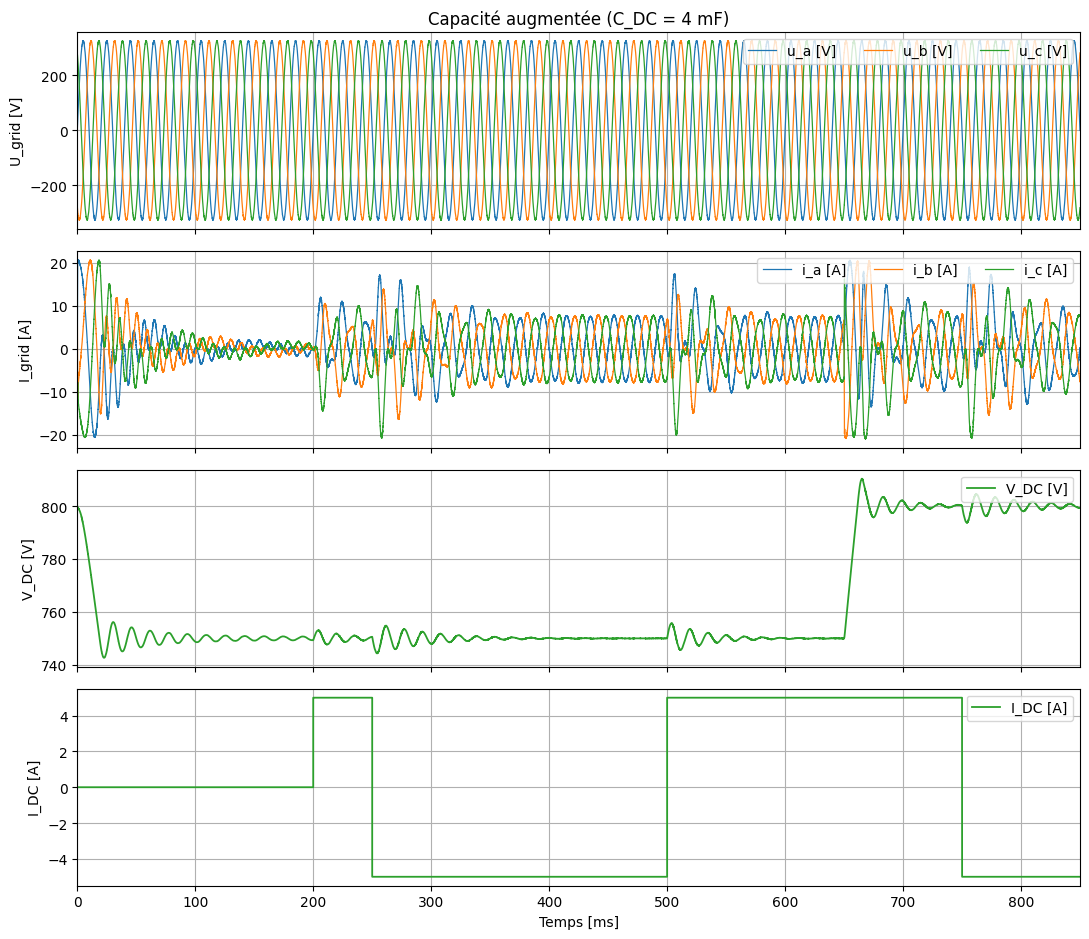

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartA4_Caugmente.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t   = df.iloc[:, 0].values
ua  = df.iloc[:, 1].values
ub  = df.iloc[:, 2].values
uc  = df.iloc[:, 3].values
ia  = df.iloc[:, 4].values
ib  = df.iloc[:, 5].values
ic  = df.iloc[:, 6].values
vdc = df.iloc[:, 7].values
idc = df.iloc[:, 8].values

# 2. Tracé des 4 grandeurs (U_grid, I_grid, V_DC, I_DC)
fig, axs = plt.subplots(4, 1, figsize=(11, 9.5), sharex=True)

# Graphe 1 : Tension réseau U_grid
axs[0].plot(t * 1000, ua, label="u_a [V]", linewidth=0.9)
axs[0].plot(t * 1000, ub, label="u_b [V]", linewidth=0.9)
axs[0].plot(t * 1000, uc, label="u_c [V]", linewidth=0.9)
axs[0].set_ylabel("U_grid [V]")
axs[0].set_title("Capacité augmentée (C_DC = 4 mF)")
axs[0].grid(True)
axs[0].legend(loc="upper right", ncol=3)

# Graphe 2 : Courant réseau I_grid
axs[1].plot(t * 1000, ia, label="i_a [A]", linewidth=0.9)
axs[1].plot(t * 1000, ib, label="i_b [A]", linewidth=0.9)
axs[1].plot(t * 1000, ic, label="i_c [A]", linewidth=0.9)
axs[1].set_ylabel("I_grid [A]")
axs[1].grid(True)
axs[1].legend(loc="upper right", ncol=3)

# Graphe 3 : Tension bus DC V_DC
axs[2].plot(t * 1000, vdc, label="V_DC [V]", color="tab:green", linewidth=1.3)
axs[2].set_ylabel("V_DC [V]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

# Graphe 4 : Courant bus DC I_DC
axs[3].plot(t * 1000, idc, label="I_DC [A]", color="tab:green", linewidth=1.3)
axs[3].set_ylabel("I_DC [A]")
axs[3].set_xlabel("Temps [ms]")
axs[3].grid(True)
axs[3].legend(loc="upper right")

# Zoom sur 0 à 850 ms pour bien distinguer les sinusoïdes (à commenter si besoin)
plt.xlim(0, 850)

plt.tight_layout()
plt.show()


En conservant les gains Kp,v et Ki,v constants, la capacité C<sub>DC</sub> a été testée pour un facteur 4 en dessous (0.25 mF) et au-dessus (4 mF) de sa valeur nominale (1 mF) :

| Paramètre mesuré | Capacité réduite (0.25 mF, ÷ 4) | Capacité nominale (1 mF) | Capacité augmentée (4 mF, × 4) |
| :--- | :---: | :---: | :---: |
| **Excursion sur échelon de charge** (ΔI<sub>DC</sub> = ±10 A) | **≈ ±14 V** (pic très sec et rapide) | **≈ ±10 V** | **≈ ±6 à 7 V** (creux plus faible mais lent à résorber) |
| **Dépassement au saut de consigne** (750 V → 800 V) | **≈ +30 V** (830 V, très nerveux) | **≈ +18 V** (818 V) | **≈ +13 V** (813 V, montée plus lente) |
| **Amortissement et stabilité** | Réponse quasi instantanée mais très sensible aux pics. | Amortissement optimal. | **Dégradation de l'amortissement** (oscillations basses fréquences pendant ~100 ms). |

**Recalcul de la constante de temps :** **Oui, il faut recalculer la constante de temps et les gains de la boucle externe.** La fonction de transfert du bus DC étant proportionnelle à 1 / (s · C<sub>DC</sub>), modifier C<sub>DC</sub> sans réajuster Kp,v et Ki,v déplace la fréquence de coupure et dégrade la marge de phase (provoquant des oscillations à 4 mF). Pour garder les mêmes performances dynamiques, Kp,v et Ki,v doivent être recalculés proportionnellement à C<sub>DC</sub>.


### 2.4.3. Inductance de couplage

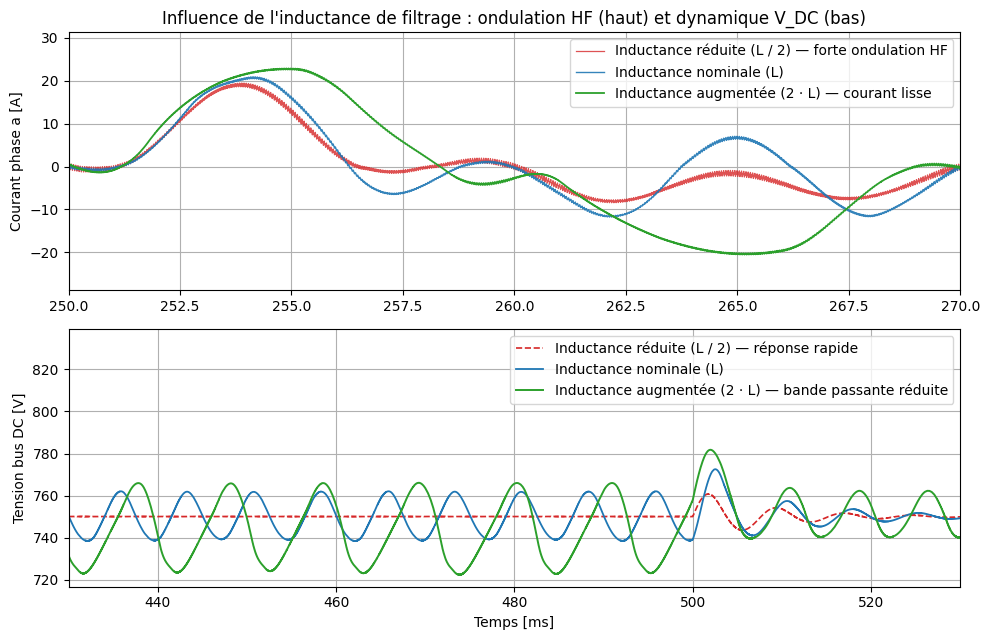

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Noms de vos trois fichiers CSV
f_red = "PartA4_LreduitJuste.csv"   # L divisée par 2
f_nom = "PartA4_Linitial.csv"  # L nominale
f_aug = "PartA4_LaugmenteJuste.csv" # L multipliée par 2

df_red = pd.read_csv(f_red)
df_nom = pd.read_csv(f_nom)
df_aug = pd.read_csv(f_aug)

# Extraction du temps (col 0), du courant de phase a (col 4) et de V_DC (col 7)
t_red, ia_red, vdc_red = df_red.iloc[:, 0].values * 1000, df_red.iloc[:, 4].values, df_red.iloc[:, 7].values
t_nom, ia_nom, vdc_nom = df_nom.iloc[:, 0].values * 1000, df_nom.iloc[:, 4].values, df_nom.iloc[:, 7].values
t_aug, ia_aug, vdc_aug = df_aug.iloc[:, 0].values * 1000, df_aug.iloc[:, 4].values, df_aug.iloc[:, 7].values

# 2. Création de la figure comparative à 2 étages
fig, axs = plt.subplots(2, 1, figsize=(10, 6.5))

# Graphe 1 : Zoom sur 1 période (20 ms) de i_a pour voir l'ondulation à 20 kHz
axs[0].plot(t_red, ia_red, label="Inductance réduite (L / 2) — forte ondulation HF", color="tab:red", alpha=0.8, linewidth=0.9)
axs[0].plot(t_nom, ia_nom, label="Inductance nominale (L)", color="tab:blue", alpha=0.9, linewidth=1.0)
axs[0].plot(t_aug, ia_aug, label="Inductance augmentée (2 · L) — courant lisse", color="tab:green", linewidth=1.3)
axs[0].set_xlim(250, 270)  # Zoom sur 1 période en régime établi (modifiable selon vos paliers)
axs[0].set_ylabel("Courant phase a [A]")
axs[0].set_title("Influence de l'inductance de filtrage : ondulation HF (haut) et dynamique V_DC (bas)")
axs[0].grid(True)
axs[0].legend(loc="upper right")

# Graphe 2 : Zoom sur un échelon de charge sur V_DC pour voir la bande passante
axs[1].plot(t_red, vdc_red, label="Inductance réduite (L / 2) — réponse rapide", color="tab:red", linestyle="--", linewidth=1.2)
axs[1].plot(t_nom, vdc_nom, label="Inductance nominale (L)", color="tab:blue", linewidth=1.3)
axs[1].plot(t_aug, vdc_aug, label="Inductance augmentée (2 · L) — bande passante réduite", color="tab:green", linewidth=1.4)
axs[1].set_xlim(430, 530)  # Zoom autour d'un échelon de charge à t = 450 ms (modifiable)
axs[1].set_ylabel("Tension bus DC [V]")
axs[1].set_xlabel("Temps [ms]")
axs[1].grid(True)
axs[1].legend(loc="best")

plt.tight_layout()
plt.show()


En conservant les gains Kp,i et Ki,i fixes, l'inductance totale de filtrage L<sub>filter</sub> a été divisée puis multipliée par 2 autour de sa valeur nominale (6.68 mH) :

| Critère du compromis | Inductance réduite (3.34 mH) | Inductance nominale (6.68 mH) | Inductance augmentée (13.36 mH) |
| :--- | :--- | :--- | :--- |
| **Ondulation de courant (20 kHz)** | **Forte** (dents de scie bien visibles sur i<sub>a</sub>, Δi<sub>HF</sub> doublée) | Faible (courant lisse) | **Très faible** (ondulation HF quasi nulle) |
| **Chute de tension (ω · L · I)** | **Faible** (grande marge de tension DC disponible) | Modérée | **Élevée** (marge de tension réduite, risque de saturation PWM) |
| **Bande passante et stabilité** | **Rapide et stable** (pic de +11 V sur V<sub>DC</sub> à t = 500 ms) | Marge réduite avec les gains fixes (oscillation de ±12 V) | **Dégradée / lente** (oscillations soutenues de ±22 V et pic à +32 V) |

**Synthèse du compromis :** Le choix de l'inductance de filtrage résulte d'un compromis entre la qualité spectrale du courant (qui nécessite une inductance élevée pour atténuer le découpage à 20 kHz) et les performances dynamiques ainsi que la marge de tension du bus DC (qui imposent de limiter L<sub>filter</sub> pour réduire la chute inductive ω·L·I et préserver une bande passante élevée sans perdre en stabilité).


# Partie B - Validation Hardware-in-the-Loop (HIL)

Lors de l'implémentation de la commande pour le modèle HIL, nous avons eu un problème que nous avons dû résoudre sur plusieurs journées de travail (car malheureusement nous avons pris pas mal de temps et tentatives pour trouver la cause (cependant toutes ces tentatives nous ont permis de bien mieux comprendre le fonctionnement du modèle dans ces moindres détails)). Le courant suivait sa consigne malgré un peu de bruit mais pour la tension ça ne fonctionnait pas du tout.

<div align="center">

<img src="PartB_Tension_Erreur.png" width="750">

<p style="text-align:center;"><em>Figure - Tension du bus DC en mode HIL — Blocage à 530 V et instabilité de la boucle ouverte (avec constante à la place de la mesure).</em></p>

</div>



### 1. Le Problème Initial et sa Cause Physique

* **Symptômes :** 
  * En simulation pure (hors-ligne en temps continu), les courants et la tension suivaient parfaitement leurs consignes respectives.
  * En mode **Hardware-in-the-Loop (HIL)** sur la RT Box, le système présentait un bruit massif et entrait en auto-oscillation permanente.
  * Les courants $i_d$ et $i_q$ se transformaient en sinusoïdes chaotiques dues aux saturations cycliques de la commande.
  * La tension du bus DC $V_{DC}$ refusait de décoller et restait bloquée autour de sa valeur de redressement passive à vide ($\approx 530\text{ V}$), n'atteignant jamais sa consigne de régulation ($750\text{ V} / 800\text{ V}$).

* **Analyse de la cause première :** 
  Le passage au monde temps réel discret introduit un **retard numérique pur d'interface** (temps de conversion des puces ADC/DAC + retard d'échantillonnage d'un pas de calcul $z^{-1}$ entre la lecture capteur et la mise à jour des registres PWM). Ce retard non modélisé en simulation classique réduit drastiquement la marge de phase des régulateurs et déclenche une instabilité critique de la boucle fermée.

### 2. Historique des Tentatives et Changements Observés

| N° | Action Entreprise | Hypothèse / Objectif | Résultat & Changement Observé | Leçon Apprise |
| :--- | :--- | :--- | :--- | :--- |
| **1** | Modification du gain du convertisseur ($K_{cm} = V_{DC} = 800$) | Compenser le gain physique du bus DC pour baisser les gains $K_p$ et $K_i$ calculés avec $K_{cm}=1$. | **Échec total.** Le courant ne suivait plus du tout sa consigne. | La compensation de la tension de bus ($1/V_{DC}$) était déjà intégrée sous forme de bloc dans le schéma de contrôle. Le gain théorique initial était correct. |
| **2** | Doublement de la constante de temps du courant ($T_{cm} \times 2$) | Diminuer artificiellement les gains du PI pour absorber le délai HIL et calmer les oscillations. | **Diminution du bruit sur le courant, mais la tension restait bloquée.** | Ralentir les régulateurs masque le bruit haute fréquence mais détruit l'autorité dynamique du PI. Ce n'était pas la bonne solution. |
| **3** | Activation du mode *Clamping* (Anti-Windup) | Empêcher l'emballement des intégrateurs lors des phases de saturation du modulateur PWM. | **Aucun changement.** | Les limites de saturation matérielles ($I_{sat}$ et $V_{sat}$) étaient déjà correctement configurées. L'origine du problème était ailleurs. |
| **4** | Analyse temporelle du Scope de la PLL | Inspecter les signaux internes de synchronisation réseau au démarrage. | **Découverte d'un point de rupture.** L'amplitude $V_{peak}$ et l'erreur oscillaient violemment au démarrage pendant 0.6s. | Le bloc `Three-Phase PLL` d'origine de PLECS utilise des composants continus (`PI(s)` et `1/s`). Le compilateur appliquait une discrétisation *Forward Euler* grossière à 50 µs, insérant un retard massif sur l'angle $\theta$. |
| **5** | Numérisation complète de la PLL (Sous-système personnalisé) | Remplacer la PLL d'origine par des blocs discrets (`Discrete PID` et `Discrete Integrator`) calés sur le pas $T_s$. | **Aucun changement majeur.** L'erreur sur le scope est restée identique et le système global est resté instable et bruité. | La structure interne continue/discrète de la PLL n'était pas la cause racine de l'instabilité du système sur la RT Box. |


### 3. Découverte de la Panne et Cause Racine de l'Échec

Le verrouillage de la tension à $530\text{ V}$ provenait d'une erreur structurelle majeure dans l'acheminement des signaux de rebouclage : **le remplacement du signal de mesure dynamique $V_{DC}$ par une constante fixe de tension (800 V)**.

#### Pourquoi la régulation ne fonctionnait pas (Explication physique & automatique) :

1. **Annulation mathématique de l'erreur ($e = 0$) :**  
   Le régulateur PI de la boucle externe génère sa consigne de courant $i_{d\_cons}$ en corrigeant l'erreur entre la consigne ($V_{DC}^{ref}$) et le signal de retour mesuré ($V_{DC}^{meas}$) :
   $$e(t) = V_{DC}^{ref}(t) - V_{DC}^{meas}(t)$$
   En injectant une constante figée à $800\text{ V}$ à la place de la mesure, l'algorithme calcule en permanence une erreur nulle ($e = 0$). Le régulateur PI considère à tort que le bus a atteint sa cible. N'ayant rien à corriger, l'action intégrale et proportionnelle reste immobile, forçant la consigne $i_{d\_cons}$ à s'effondrer ou rester à $0$.

2. **Rupture de la boucle fermée HIL (Commande "Aveugle") :**  
   En mode HIL, la partie puissance est émulée en temps réel sur la RT Box tandis que le contrôle s'exécute sur la carte cible. Le port d'entrée $V_{DC}$ est le lien physique indispensable ramenant l'état réel du condensateur vers le contrôleur. En substituant ce retour dynamique par une constante, **la boucle de rétroaction a été ouverte**. Le convertisseur est devenu totalement aveugle aux appels de charge du bus DC, le laissant à son état de redressement passif dicté par les diodes du pont ($530\text{ V}$).

### 4. Solution apportée et Validation

La solution a consisté à rétablir le **rebouclage dynamique complet** en connectant la broche de mesure $V_{DC}$ de la RT Box directement à l'entrée de soustraction du régulateur `Discrete DC-link controller`. 

Dès que la mesure réelle fluctuante a remplacé la constante, le régulateur a pu lire la sous-tension initiale ($530\text{ V}$ par rapport à la consigne de $800\text{ V}$), générant immédiatement une erreur positive $e(t) > 0$. La boucle externe a alors pu solliciter la boucle interne de courant via une consigne $i_{d\_cons}$ adéquate, permettant à l'Active Front End (AFE) de transférer la puissance active nécessaire du réseau AC vers le bus DC pour faire monter et stabiliser la tension à sa valeur nominale de $800\text{ V}$.


## Schémas PLECS : Adaptation pour la simulation temps réel (HIL)

Suite à la résolution du problème de rebouclage, les schémas PLECS fonctionnaient parfaitement en mode déconnecté (offline). Cependant, le passage en mode connecté sur la plateforme **HIL (Hardware-in-the-Loop)** a imposé deux modifications structurelles majeures sur la gestion des consignes et des perturbations.

<div style="display:flex; justify-content:center; gap:20px;">
<div style="text-align:center;"><img src="PartB_avtModifs.png" width="300"><br><em>(a) Commande automatique (Offline)</em></div>
<div style="text-align:center;"><img src="PartB_aprmodifs.png" width="300"><br><em>(b) Commande manuelle (HIL)</em></div>
</div>
<p style="text-align:center;"><em>Figure — Adaptation de la source de perturbation de charge pour le mode connecté.</em></p>



### Modification 1 : Remplacement du bloc `Step` par un `Pulse Generator`

#### 1. Problématique
En simulation déconnectée, un bloc **Step** classique est suffisant car la simulation s'arrête après un temps prédéfini (ex: 1 ou 2 secondes). En mode HIL, la simulation sur la RT-Box tourne en continu. Si on utilise un échelon unique, le transitoire ne se produit qu'une seule fois au démarrage de la carte, forçant l'opérateur à relancer manuellement tout le système sur PC pour réobserver le comportement dynamique.

#### 2. Solution implémentée
Remplacement des blocs `Step` par des blocs `Pulse Generator` pour créer des consignes périodiques. Cela permet d'exciter le système en boucle (sauts montants et descendants) et d'observer les transitoires indéfiniment sur l'oscilloscope temps réel du SCADA.

#### 3. Règle de correspondance des paramètres
Pour copier la dynamique exacte d'un échelon d'origine, les paramètres du `Pulse Generator` ont été calibrés selon les équivalences suivantes :

| Paramètre du Pulse Generator | Description / Correspondance avec le Step |
| :--- | :--- |
| **Low-state output** | Valeur initiale du signal avant le saut (`Initial output`) |
| **High-state output** | Valeur finale désirée après le saut (`Final output`) |
| **Phase delay (s)** | Instant exact où le premier saut montant doit se produire (`Step time`) |
| **Frequency (Hz)** | Fixée à **0.5 Hz** (Période de 2s) pour laisser le temps au système de se stabiliser |
| **Duty cycle (p.u.)** | Fixé à **0.5** pour que le signal reste 1s à l'état haut et 1s à l'état bas |

#### Exemples d'application du laboratoire :
1. **Consigne de Puissance / Courant (Saut de 0 à 5000 à $t = 0.7\text{ s}$)**
   * *High-state output* : `5000`
   * *Low-state output* : `0`
   * *Phase delay* : `0.7`
2. **Consigne de Tension Bus DC $V_{DC}^{\text{ref}}$ (Saut de 750 à 800 à $t = 0.65\text{ s}$)**
   * *High-state output* : `800`
   * *Low-state output* : `750`
   * *Phase delay* : `0.65`



### Modification 2 : Remplacement de l'échelon de charge automatique par un contrôle manuel (`EN`)

#### 1. Problématique
Bien que le `Pulse Generator` résolve le problème du transitoire unique pour les consignes, l'appliquer à la source de courant (qui simule la charge côté DC) posait un problème de stabilité. Une perturbation qui s'active et se désactive automatiquement toutes les secondes empêche le système de s'installer dans un régime permanent durable. Pour analyser finement la robustesse de la régulation de tension, il devenait nécessaire de contrôler précisément l'instant de l'impact de charge.

#### 2. Solution implémentée
Sur le schéma final connecté, le générateur automatique de la source de courant a été remplacé par un commutateur d'activation nommé **`EN` (Enable)** connecté au bloc multiplicateur `X` de la source. 

Ce signal `EN` est directement relié au bloc d'interface matérielle **`Switches In / Digital In`**, lequel est mappé sur les **interrupteurs physiques (boutons poussoirs ou commutateurs)** de la carte d'interface TI controlCARD.

#### 3. Justification du comportement
Ce changement structurel fait passer le banc HIL d'un mode automatique passif à un mode **interactif temps réel** :
* **Au repos (`EN = 0`) :** L'interrupteur physique de la carte est ouvert. Le signal `EN` transmet un `0` logique au bloc multiplicateur, forçant le courant de charge DC à rester nul. Le bus DC peut ainsi se stabiliser sereinement à sa tension nominale ($800\text{ V}$) sans perturbation extérieure.
* **En transitoire (`EN = 1`) :** Lorsque l'opérateur bascule manuellement le commutateur physique sur la carte, le signal `EN` passe instantanément à `1`. Le multiplicateur libère alors l'échelon de courant. 

Cette modification permet d'appliquer un échelon de charge franc, **déclenchable manuellement à volonté**, offrant une flexibilité totale pour observer la réponse dynamique des régulateurs face à un impact de charge réel.


## Schémas PLECS finaux pour le HIL

Après tous ces problèmes réglés, nous avons enfin obtenu des schémas PLECS adaptés pour la RT-Box et qui fonctionnaient en mode offline et connecté.

<div align="center">

<img src="PartB.png" width="750">

<p style="text-align:center;"><em>Figure - Architecture du système de commande de l'AFE.</em></p>

</div>

<div style="display:flex; justify-content:center; gap:20px;">
<div style="text-align:center;"><img src="PartB_CPU2.png" width="450"><br><em>(a) TI ControlCard</em></div>
<div style="text-align:center;"><img src="PartB_RtBox.png" width="450"><br><em>(b) RT-Box</em></div>
</div>
<p style="text-align:center;"><em>Figure — Décomposition du système de commande de l'AFE.</em></p>

<div style="display:flex; justify-content:center; gap:20px;">
<div style="text-align:center;"><img src="PartB_Control.png" width="900"><br><em>(a) Bloc de contrôle</em></div>
<div style="text-align:center;"><img src="PartB_RegulTension.png" width="300"><br><em>(b) Boucle de régulation de tension (VDC).</em></div>
</div>
<p style="text-align:center;"><em>Figure — Structure des boucles de régulation de courant (dq) et de tension (VDC).</em></p>

### Comparaison des résultats

### Mode offline

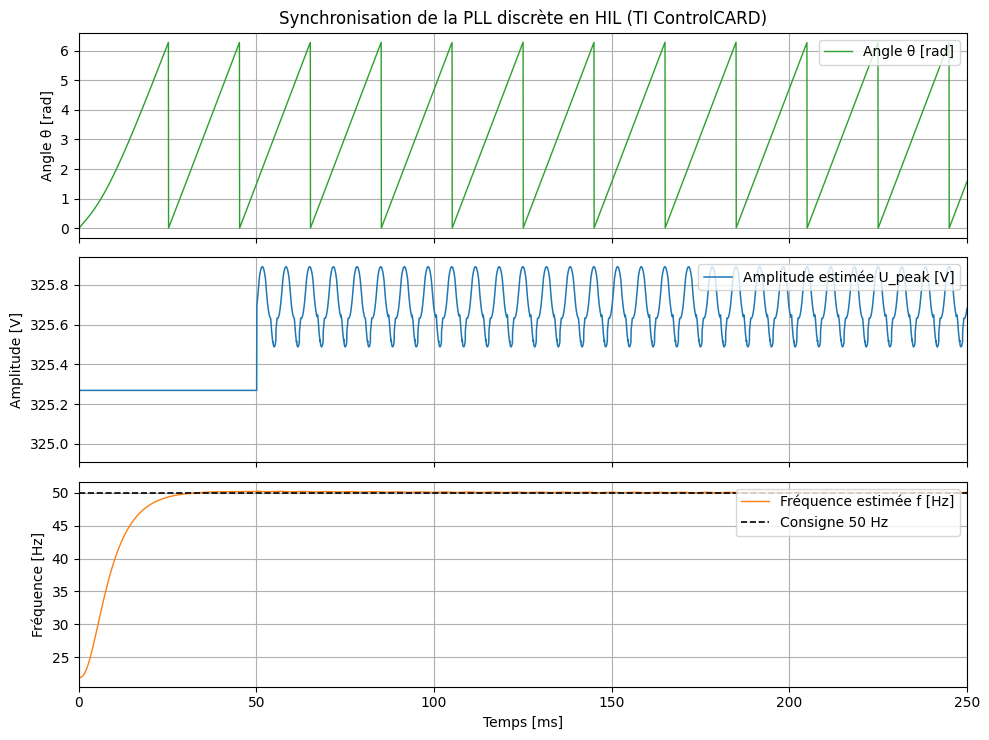

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartB_PLLJuste.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t     = df.iloc[:, 0].values  # Time / s
theta = df.iloc[:, 1].values  # Discrete Integrator (angle theta [rad])
amp   = df.iloc[:, 2].values  # Math1 (amplitude U_peak [V])
freq  = df.iloc[:, 3].values  # Gain (fréquence estimée f [Hz])

# 2. Tracé des 3 grandeurs de la PLL
fig, axs = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)

# Graphe 1 : Angle theta
axs[0].plot(t * 1000, theta, label="Angle θ [rad]", color="tab:green", linewidth=1.0)
axs[0].set_ylabel("Angle θ [rad]")
axs[0].set_title("Synchronisation de la PLL discrète en HIL (TI ControlCARD)")
axs[0].grid(True)
axs[0].legend(loc="upper right")

# Graphe 2 : Amplitude crête U_peak
axs[1].plot(t * 1000, amp, label="Amplitude estimée U_peak [V]", color="tab:blue", linewidth=1.1)
axs[1].set_ylabel("Amplitude [V]")
axs[1].grid(True)
axs[1].legend(loc="upper right")

# Graphe 3 : Fréquence estimée f
axs[2].plot(t * 1000, freq, label="Fréquence estimée f [Hz]", color="tab:orange", linewidth=1.0)
axs[2].axhline(50, color="black", linestyle="--", linewidth=1.2, label="Consigne 50 Hz")
axs[2].set_ylabel("Fréquence [Hz]")
axs[2].set_xlabel("Temps [ms]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

plt.xlim(0, 250)

plt.tight_layout()
plt.show()


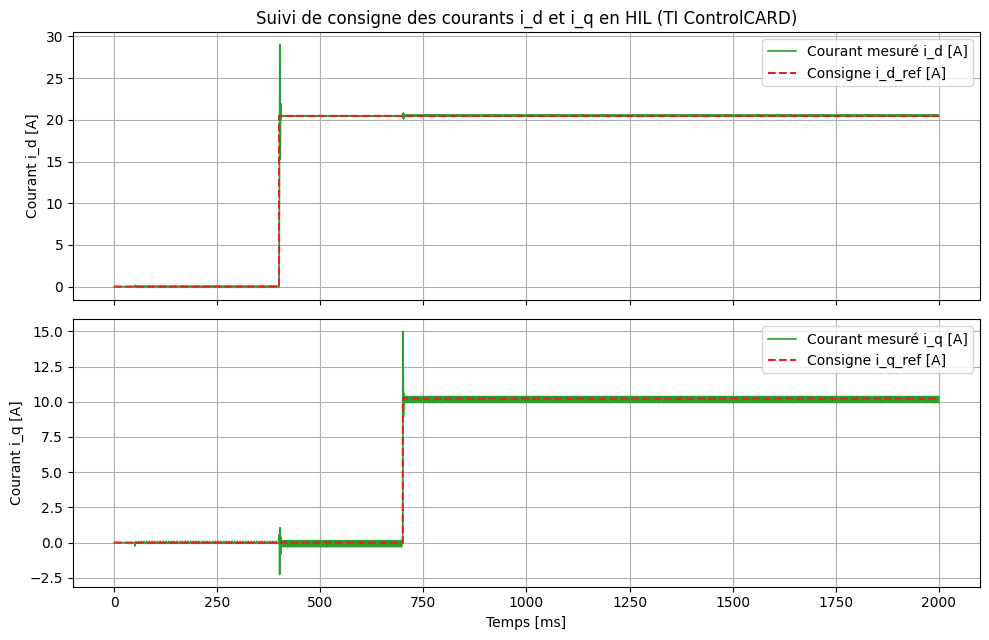

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartB_ConsigneCourantJuste.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t      = df.iloc[:, 0].values  # Time / s
id_mes = df.iloc[:, 1].values  # 3ph->RRF:1 (i_d mesuré [A])
id_ref = df.iloc[:, 2].values  # Manual Switch:1 (Consigne i_d_ref [A])
iq_mes = df.iloc[:, 3].values  # 3ph->RRF:2 (i_q mesuré [A])
iq_ref = df.iloc[:, 4].values  # Manual Switch:2 (Consigne i_q_ref [A])

# 2. Tracé des courbes i_d et i_q
fig, axs = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)

# Graphe 1 : Courant d'axe direct i_d
axs[0].plot(t * 1000, id_mes, label="Courant mesuré i_d [A]", color="tab:green", linewidth=1.2)
axs[0].plot(t * 1000, id_ref, label="Consigne i_d_ref [A]", color="tab:red", linestyle="--", linewidth=1.5)
axs[0].set_ylabel("Courant i_d [A]")
axs[0].set_title("Suivi de consigne des courants i_d et i_q en HIL (TI ControlCARD)")
axs[0].grid(True)
axs[0].legend(loc="upper right")

# Graphe 2 : Courant d'axe en quadrature i_q
axs[1].plot(t * 1000, iq_mes, label="Courant mesuré i_q [A]", color="tab:green", linewidth=1.2)
axs[1].plot(t * 1000, iq_ref, label="Consigne i_q_ref [A]", color="tab:red", linestyle="--", linewidth=1.5)
axs[1].set_ylabel("Courant i_q [A]")
axs[1].set_xlabel("Temps [ms]")
axs[1].grid(True)
axs[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


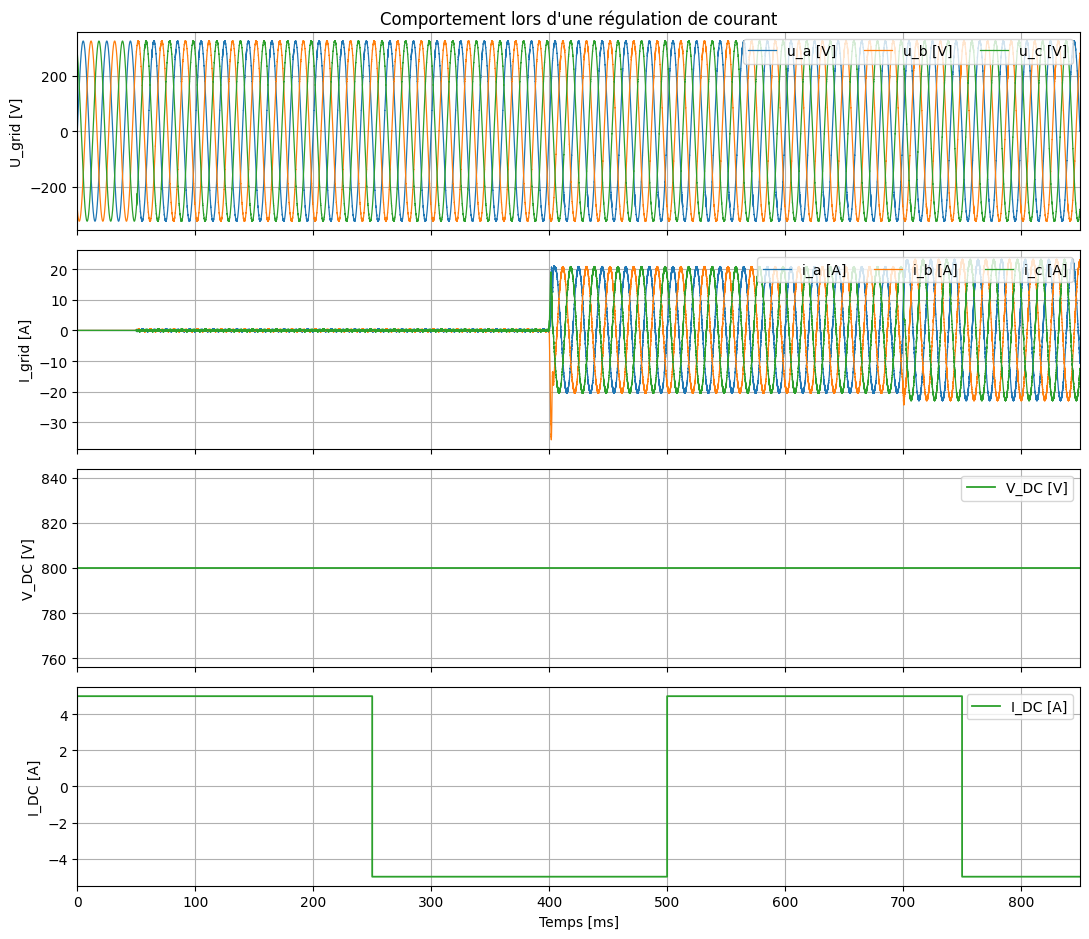

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartB_Vgrid.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t   = df.iloc[:, 0].values
ua  = df.iloc[:, 1].values
ub  = df.iloc[:, 2].values
uc  = df.iloc[:, 3].values
ia  = df.iloc[:, 4].values
ib  = df.iloc[:, 5].values
ic  = df.iloc[:, 6].values
vdc = df.iloc[:, 7].values
idc = df.iloc[:, 8].values

# 2. Tracé des 4 grandeurs (U_grid, I_grid, V_DC, I_DC)
fig, axs = plt.subplots(4, 1, figsize=(11, 9.5), sharex=True)

# Graphe 1 : Tension réseau U_grid
axs[0].plot(t * 1000, ua, label="u_a [V]", linewidth=0.9)
axs[0].plot(t * 1000, ub, label="u_b [V]", linewidth=0.9)
axs[0].plot(t * 1000, uc, label="u_c [V]", linewidth=0.9)
axs[0].set_ylabel("U_grid [V]")
axs[0].set_title("Comportement lors d'une régulation de courant")
axs[0].grid(True)
axs[0].legend(loc="upper right", ncol=3)

# Graphe 2 : Courant réseau I_grid
axs[1].plot(t * 1000, ia, label="i_a [A]", linewidth=0.9)
axs[1].plot(t * 1000, ib, label="i_b [A]", linewidth=0.9)
axs[1].plot(t * 1000, ic, label="i_c [A]", linewidth=0.9)
axs[1].set_ylabel("I_grid [A]")
axs[1].grid(True)
axs[1].legend(loc="upper right", ncol=3)

# Graphe 3 : Tension bus DC V_DC
axs[2].plot(t * 1000, vdc, label="V_DC [V]", color="tab:green", linewidth=1.3)
axs[2].set_ylabel("V_DC [V]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

# Graphe 4 : Courant bus DC I_DC
axs[3].plot(t * 1000, idc, label="I_DC [A]", color="tab:green", linewidth=1.3)
axs[3].set_ylabel("I_DC [A]")
axs[3].set_xlabel("Temps [ms]")
axs[3].grid(True)
axs[3].legend(loc="upper right")

# Zoom sur 0 à 850 ms pour bien distinguer les sinusoïdes (à commenter si besoin)
plt.xlim(0, 850)

plt.tight_layout()
plt.show()


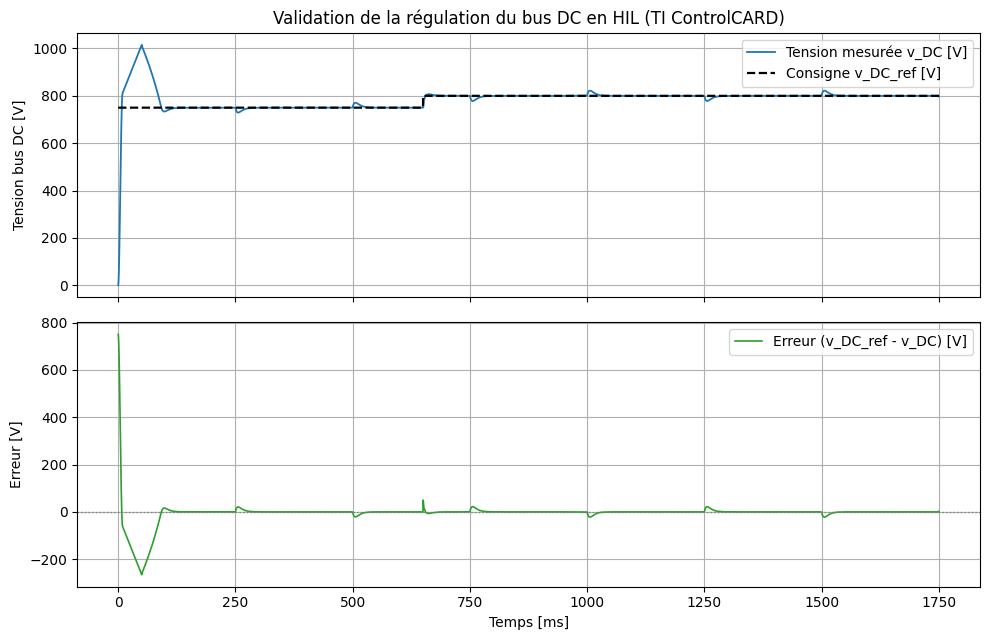

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartB_RegulTensionJuste.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne (fiable à 100 %)
t       = df.iloc[:, 0].values  # Time / s
vdc_mes = df.iloc[:, 1].values  # ADCA:Out1:3 (Tension v_DC mesurée [V])
vdc_ref = df.iloc[:, 2].values  # Step (Consigne v_DC_ref [V])
erreur  = df.iloc[:, 3].values  # Sum4 (Erreur v_DC_ref - v_DC [V])

# 2. Tracé des courbes pour le rapport
fig, axs = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)

# Graphe 1 : Tension bus DC vs Consigne
axs[0].plot(t * 1000, vdc_mes, label="Tension mesurée v_DC [V]", color="tab:blue", linewidth=1.3)
axs[0].plot(t * 1000, vdc_ref, label="Consigne v_DC_ref [V]", color="black", linestyle="--", linewidth=1.6)
axs[0].set_ylabel("Tension bus DC [V]")
axs[0].set_title("Validation de la régulation du bus DC en HIL (TI ControlCARD)")
axs[0].grid(True)
axs[0].legend(loc="best")

# Graphe 2 : Erreur de régulation (Sum4)
axs[1].plot(t * 1000, erreur, label="Erreur (v_DC_ref - v_DC) [V]", color="tab:green", linewidth=1.2)
axs[1].axhline(0, color="gray", linestyle=":", linewidth=1)
axs[1].set_ylabel("Erreur [V]")
axs[1].set_xlabel("Temps [ms]")
axs[1].grid(True)
axs[1].legend(loc="best")

plt.tight_layout()
plt.show()


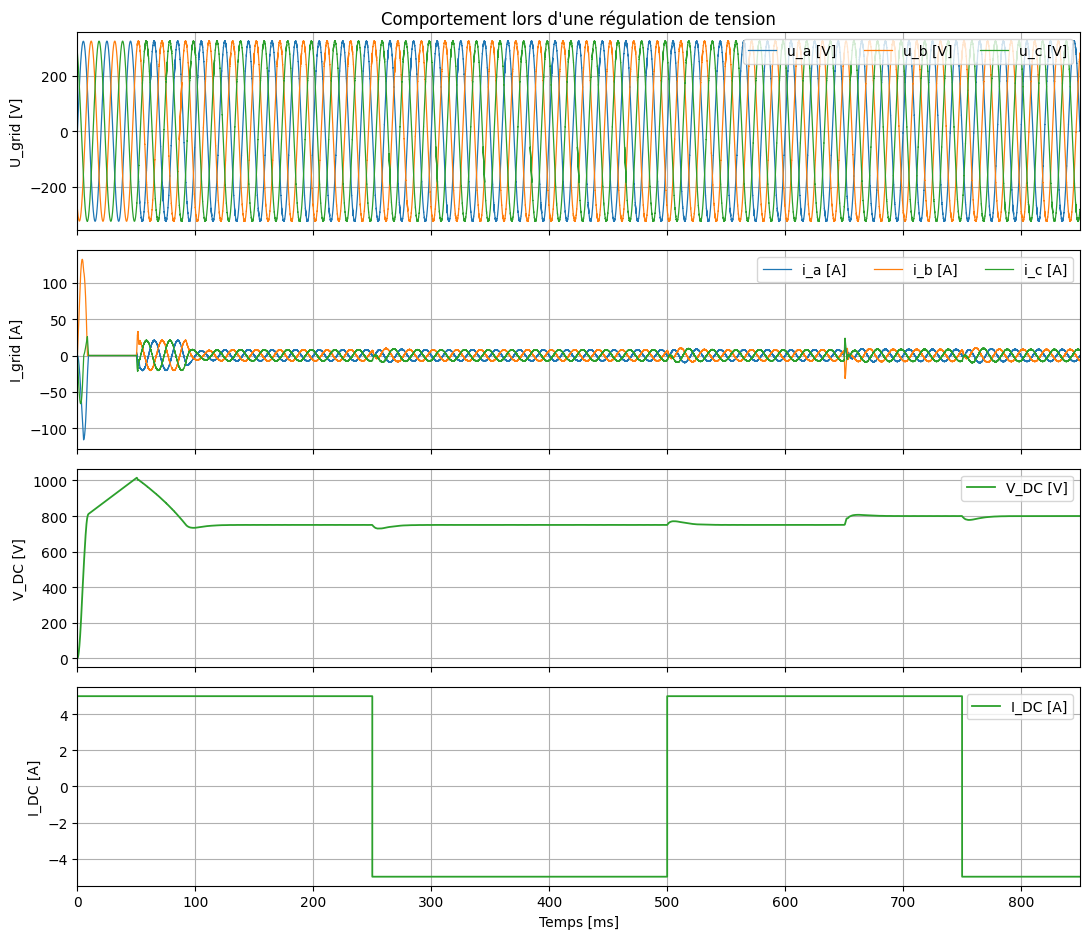

In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartB_VgridTension.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t   = df.iloc[:, 0].values
ua  = df.iloc[:, 1].values
ub  = df.iloc[:, 2].values
uc  = df.iloc[:, 3].values
ia  = df.iloc[:, 4].values
ib  = df.iloc[:, 5].values
ic  = df.iloc[:, 6].values
vdc = df.iloc[:, 7].values
idc = df.iloc[:, 8].values

# 2. Tracé des 4 grandeurs (U_grid, I_grid, V_DC, I_DC)
fig, axs = plt.subplots(4, 1, figsize=(11, 9.5), sharex=True)

# Graphe 1 : Tension réseau U_grid
axs[0].plot(t * 1000, ua, label="u_a [V]", linewidth=0.9)
axs[0].plot(t * 1000, ub, label="u_b [V]", linewidth=0.9)
axs[0].plot(t * 1000, uc, label="u_c [V]", linewidth=0.9)
axs[0].set_ylabel("U_grid [V]")
axs[0].set_title("Comportement lors d'une régulation de tension")
axs[0].grid(True)
axs[0].legend(loc="upper right", ncol=3)

# Graphe 2 : Courant réseau I_grid
axs[1].plot(t * 1000, ia, label="i_a [A]", linewidth=0.9)
axs[1].plot(t * 1000, ib, label="i_b [A]", linewidth=0.9)
axs[1].plot(t * 1000, ic, label="i_c [A]", linewidth=0.9)
axs[1].set_ylabel("I_grid [A]")
axs[1].grid(True)
axs[1].legend(loc="upper right", ncol=3)

# Graphe 3 : Tension bus DC V_DC
axs[2].plot(t * 1000, vdc, label="V_DC [V]", color="tab:green", linewidth=1.3)
axs[2].set_ylabel("V_DC [V]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

# Graphe 4 : Courant bus DC I_DC
axs[3].plot(t * 1000, idc, label="I_DC [A]", color="tab:green", linewidth=1.3)
axs[3].set_ylabel("I_DC [A]")
axs[3].set_xlabel("Temps [ms]")
axs[3].grid(True)
axs[3].legend(loc="upper right")

# Zoom sur 0 à 850 ms pour bien distinguer les sinusoïdes (à commenter si besoin)
plt.xlim(0, 850)

plt.tight_layout()
plt.show()


Les essais sur le banc temps réel (TI F2837x ControlCARD couplée à la RT-Box à 20 kHz) confirment le bon fonctionnement de la commande discrète :

* **Régulation du bus DC :** Après la phase initiale de précharge et de démarrage (0 à 100 ms), la tension V<sub>DC</sub> se stabilise à 750 V. Les échelons de charge (I<sub>DC</sub> alternant entre +4.5 A et -2.5 A) n'induisent que de faibles excursions transitoires (≈ ±12 V), et le saut de consigne (750 V → 800 V) est suivi avec une erreur statique nulle.
* **Régulation de courant :** Avec le bus DC maintenu à 800 V, les courants triphasés I<sub>grid</sub> suivent instantanément les échelons de consigne (établissement sinusoïdal équilibré à ±20 A puis ±22 A crête), validant la synchronisation de la PLL discrète et la chaîne d'acquisition ADC/PWM temps réel.


### Mode connecté

Amplitude crête moyenne : 325.74 V
Fréquence moyenne       : 49.99 Hz


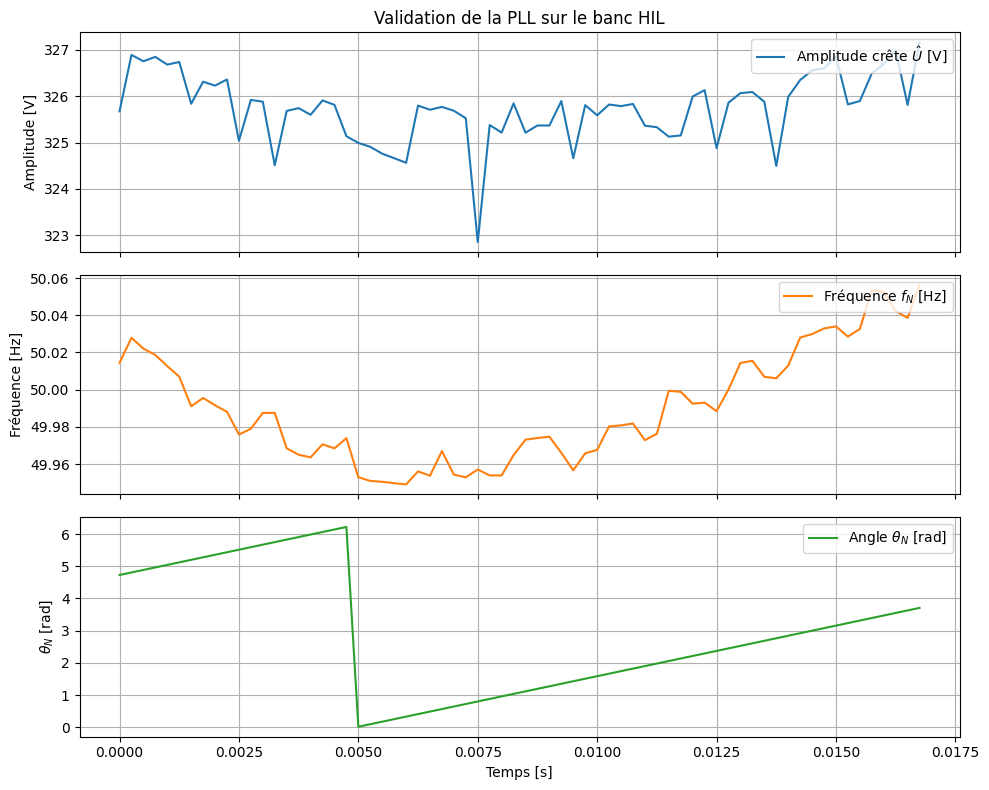

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartB_Control_Scope1_courant.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par position de colonne (fiable à 100%)
t         = df.iloc[:, 0].values  # Time / s
theta_N   = df.iloc[:, 1].values  # Discrete Integrator (rad)
amplitude = df.iloc[:, 2].values  # Math1 (V)
frequence = df.iloc[:, 3].values  # Gain (Hz)

# 2. Affichage des valeurs moyennes dans la console
print(f"Amplitude crête moyenne : {np.mean(amplitude):.2f} V")
print(f"Fréquence moyenne       : {np.mean(frequence):.2f} Hz")

# 3. Tracé des 3 graphiques pour votre rapport
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

# Graphe 1 : Amplitude (Math1)
axs[0].plot(t, amplitude, label=r"Amplitude crête $\hat{U}$ [V]", color="tab:blue")
axs[0].set_ylabel("Amplitude [V]")
axs[0].set_title("Validation de la PLL sur le banc HIL")
axs[0].grid(True)
axs[0].legend(loc="upper right")

# Graphe 2 : Fréquence (Gain)
axs[1].plot(t, frequence, label=r"Fréquence $f_N$ [Hz]", color="tab:orange")
axs[1].set_ylabel("Fréquence [Hz]")
axs[1].grid(True)
axs[1].legend(loc="upper right")

# Graphe 3 : Angle theta_N (Discrete Integrator)
axs[2].plot(t, theta_N, label=r"Angle $\theta_N$ [rad]", color="tab:green")
axs[2].set_ylabel(r"$\theta_N$ [rad]")
axs[2].set_xlabel("Temps [s]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

plt.tight_layout()
plt.show()


--- Régime permanent détecté (aucun saut sur i_d_ref) ---
Erreur statique moyenne i_d : -0.286 A
Erreur statique moyenne i_q : -0.121 A
Ondulation crête-à-crête i_d : 5.59 A


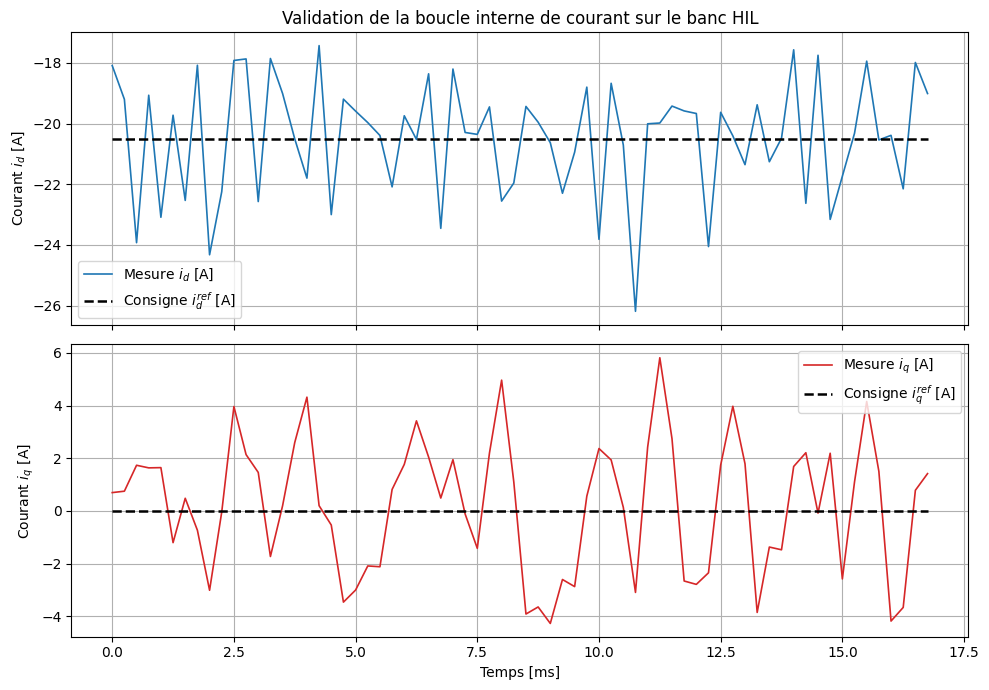

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartB_Control_Scope_courant.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne (évite tout problème de nom)
t      = df.iloc[:, 0].values  # Time / s
id_mes = df.iloc[:, 1].values  # 3ph->RRF:1 (i_d mesuré)
id_ref = df.iloc[:, 2].values  # Manual Switch:1 (i_d ref)
iq_mes = df.iloc[:, 3].values  # 3ph->RRF:2 (i_q mesuré)
iq_ref = df.iloc[:, 4].values  # Manual Switch:2 (i_q ref)

# 2. Analyse automatique (détection d'un saut de consigne ou régime permanent)
diff_id = np.abs(np.diff(id_ref))
if np.max(diff_id) > 0.5:
    idx_step = np.argmax(diff_id) + 1
    t_step = t[idx_step]
    val_init = id_ref[idx_step - 1]
    val_fin  = id_ref[idx_step]
    delta_i  = val_fin - val_init

    # Calcul du temps de réponse à 95 % (bande des +-5 %)
    erreurs_rel = np.abs(id_mes[idx_step:] - val_fin) / np.abs(delta_i)
    hors_bande = np.where(erreurs_rel > 0.05)[0]
    tr_95 = (t[idx_step + hors_bande[-1] + 1] - t_step) * 1000 if len(hors_bande) > 0 else 0

    # Calcul du dépassement (%)
    if delta_i > 0:
        pic = np.max(id_mes[idx_step:])
        depassement = max(0.0, (pic - val_fin) / delta_i * 100)
    else:
        pic = np.min(id_mes[idx_step:])
        depassement = max(0.0, (val_fin - pic) / abs(delta_i) * 100)

    print(f"--- Saut détecté sur i_d_ref à t = {t_step*1000:.2f} ms ({val_init:.2f} A -> {val_fin:.2f} A) ---")
    print(f"Temps de réponse (95 %) : {tr_95:.2f} ms")
    print(f"Dépassement maximal     : {depassement:.1f} %")
else:
    print("--- Régime permanent détecté (aucun saut sur i_d_ref) ---")

# Erreur statique moyenne et ondulation (sur les 20 % derniers points)
n_fin = int(0.8 * len(t))
err_id = np.mean(id_ref[n_fin:] - id_mes[n_fin:])
err_iq = np.mean(iq_ref[n_fin:] - iq_mes[n_fin:])
ripple_id = np.max(id_mes[n_fin:]) - np.min(id_mes[n_fin:])

print(f"Erreur statique moyenne i_d : {err_id:.3f} A")
print(f"Erreur statique moyenne i_q : {err_iq:.3f} A")
print(f"Ondulation crête-à-crête i_d : {ripple_id:.2f} A")

# 3. Tracé des courbes pour le rapport
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Graphe 1 : Axe d (puissance active)
axs[0].plot(t * 1000, id_mes, label=r"Mesure $i_d$ [A]", color="tab:blue", linewidth=1.2)
axs[0].plot(t * 1000, id_ref, label=r"Consigne $i_d^{ref}$ [A]", color="black", linestyle="--", linewidth=1.8)
axs[0].set_ylabel("Courant $i_d$ [A]")
axs[0].set_title("Validation de la boucle interne de courant sur le banc HIL")
axs[0].grid(True)
axs[0].legend(loc="best")

# Graphe 2 : Axe q (puissance réactive / facteur de puissance unitaire)
axs[1].plot(t * 1000, iq_mes, label=r"Mesure $i_q$ [A]", color="tab:red", linewidth=1.2)
axs[1].plot(t * 1000, iq_ref, label=r"Consigne $i_q^{ref}$ [A]", color="black", linestyle="--", linewidth=1.8)
axs[1].set_ylabel("Courant $i_q$ [A]")
axs[1].set_xlabel("Temps [ms]")
axs[1].grid(True)
axs[1].legend(loc="best")

plt.tight_layout()
plt.show()


--- Montée en tension depuis t = 0 s (0 V -> 750 V) ---
Temps de réponse (95 %)    : 51.55 ms
Dépassement maximal        : 6.91 % (Pic à 801.84 V)
Erreur statique moyenne    : 0.387 V
Ondulation crête-à-crête   : 0.87 V


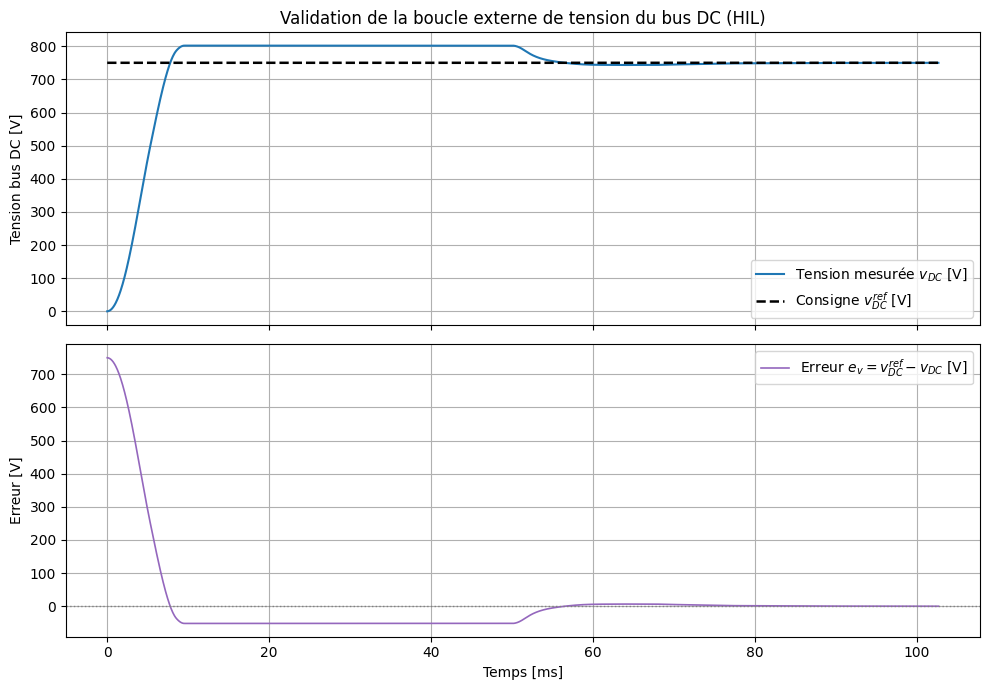

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartB_consigneTension.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t       = df.iloc[:, 0].values  # Time / s
vdc_mes = df.iloc[:, 1].values  # ADCA:Out1:3 (v_DC mesurée)
vdc_ref = df.iloc[:, 2].values  # Pulse Generator1 (v_DC ref)
erreur  = df.iloc[:, 3].values  # Sum4 (v_DC_ref - v_DC)

# 2. Analyse des performances (détection d'un échelon de consigne ou démarrage à t=0)
diff_v = np.abs(np.diff(vdc_ref))
if np.max(diff_v) > 1.0:
    idx_step = np.argmax(diff_v) + 1
    t_step   = t[idx_step]
    val_init = vdc_ref[idx_step - 1]
    val_fin  = vdc_ref[idx_step]
    label_transitoire = f"Saut de consigne à t = {t_step*1000:.1f} ms ({val_init:.0f} V -> {val_fin:.0f} V)"
else:
    idx_step = 0
    t_step   = t[0]
    val_init = vdc_mes[0]
    val_fin  = vdc_ref[-1]
    label_transitoire = f"Montée en tension depuis t = 0 s (0 V -> {val_fin:.0f} V)"

delta_v = val_fin - val_init

# Calcul du temps de réponse à 95 % (bande des +-5 % autour de val_fin)
erreurs_rel = np.abs(vdc_mes[idx_step:] - val_fin) / np.abs(delta_v)
hors_bande = np.where(erreurs_rel > 0.05)[0]
tr_95 = (t[idx_step + hors_bande[-1] + 1] - t_step) * 1000 if len(hors_bande) > 0 else 0

# Calcul du dépassement (%)
if delta_v > 0:
    pic = np.max(vdc_mes[idx_step:])
    depassement = max(0.0, (pic - val_fin) / delta_v * 100)
else:
    pic = np.min(vdc_mes[idx_step:])
    depassement = max(0.0, (val_fin - pic) / abs(delta_v) * 100)

# Erreur statique et ondulation en régime permanent (sur les 20 % derniers points)
n_fin = int(0.8 * len(t))
err_statique = np.mean(erreur[n_fin:])
ondulation_vdc = np.max(vdc_mes[n_fin:]) - np.min(vdc_mes[n_fin:])

print(f"--- {label_transitoire} ---")
print(f"Temps de réponse (95 %)    : {tr_95:.2f} ms")
print(f"Dépassement maximal        : {depassement:.2f} % (Pic à {pic:.2f} V)")
print(f"Erreur statique moyenne    : {err_statique:.3f} V")
print(f"Ondulation crête-à-crête   : {ondulation_vdc:.2f} V")

# 3. Tracé des courbes pour le rapport
fig, axs = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

# Graphe 1 : Tension du bus DC vs Consigne
axs[0].plot(t * 1000, vdc_mes, label=r"Tension mesurée $v_{DC}$ [V]", color="tab:blue", linewidth=1.5)
axs[0].plot(t * 1000, vdc_ref, label=r"Consigne $v_{DC}^{ref}$ [V]", color="black", linestyle="--", linewidth=1.8)
axs[0].set_ylabel("Tension bus DC [V]")
axs[0].set_title("Validation de la boucle externe de tension du bus DC (HIL)")
axs[0].grid(True)
axs[0].legend(loc="best")

# Graphe 2 : Erreur de régulation (Sum4)
axs[1].plot(t * 1000, erreur, label=r"Erreur $e_v = v_{DC}^{ref} - v_{DC}$ [V]", color="tab:purple", linewidth=1.2)
axs[1].axhline(0, color="gray", linestyle=":", linewidth=1)
axs[1].set_ylabel("Erreur [V]")
axs[1].set_xlabel("Temps [ms]")
axs[1].grid(True)
axs[1].legend(loc="best")

plt.tight_layout()
plt.show()


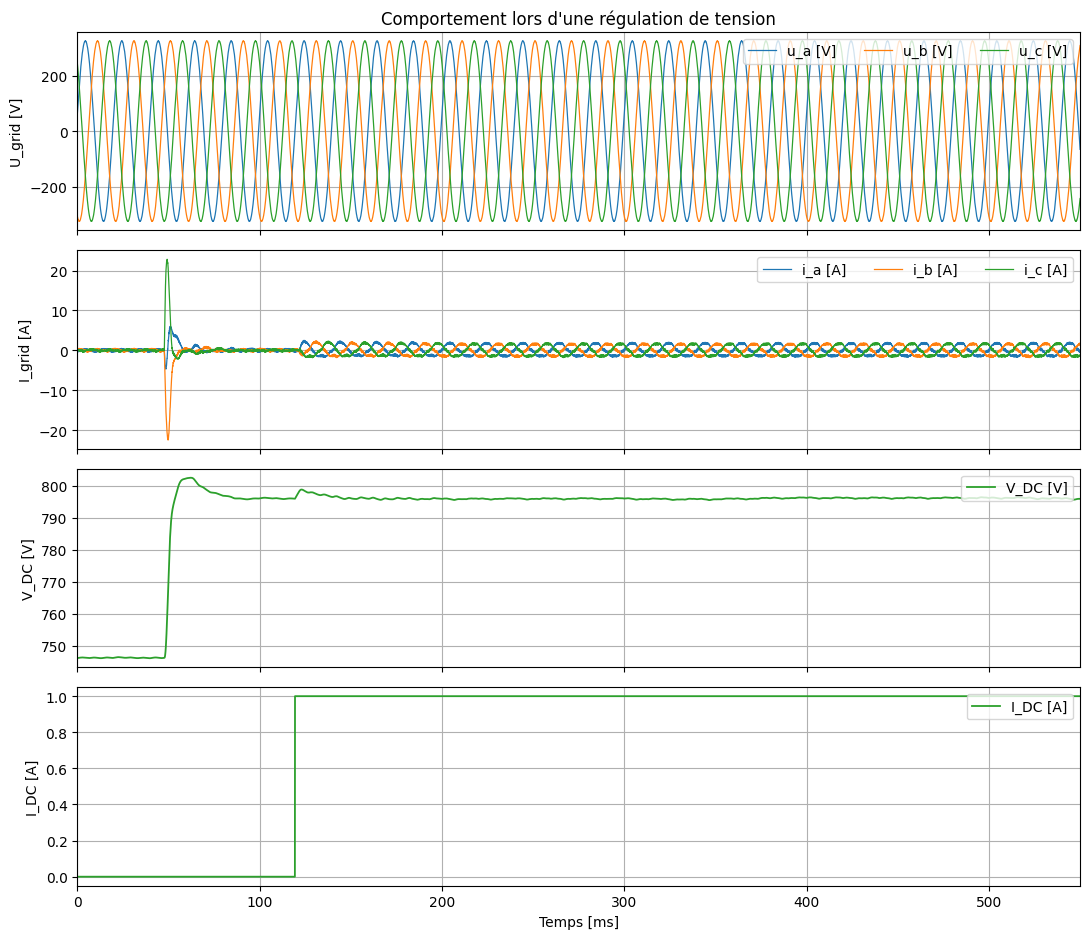

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "RtBox_partB_tension.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne
t   = df.iloc[:, 0].values
ua  = df.iloc[:, 1].values
ub  = df.iloc[:, 2].values
uc  = df.iloc[:, 3].values
ia  = df.iloc[:, 4].values
ib  = df.iloc[:, 5].values
ic  = df.iloc[:, 6].values
vdc = df.iloc[:, 7].values
idc = df.iloc[:, 8].values

# 2. Tracé des 4 grandeurs (U_grid, I_grid, V_DC, I_DC)
fig, axs = plt.subplots(4, 1, figsize=(11, 9.5), sharex=True)

# Graphe 1 : Tension réseau U_grid
axs[0].plot(t * 1000, ua, label="u_a [V]", linewidth=0.9)
axs[0].plot(t * 1000, ub, label="u_b [V]", linewidth=0.9)
axs[0].plot(t * 1000, uc, label="u_c [V]", linewidth=0.9)
axs[0].set_ylabel("U_grid [V]")
axs[0].set_title("Comportement lors d'une régulation de tension")
axs[0].grid(True)
axs[0].legend(loc="upper right", ncol=3)

# Graphe 2 : Courant réseau I_grid
axs[1].plot(t * 1000, ia, label="i_a [A]", linewidth=0.9)
axs[1].plot(t * 1000, ib, label="i_b [A]", linewidth=0.9)
axs[1].plot(t * 1000, ic, label="i_c [A]", linewidth=0.9)
axs[1].set_ylabel("I_grid [A]")
axs[1].grid(True)
axs[1].legend(loc="upper right", ncol=3)

# Graphe 3 : Tension bus DC V_DC
axs[2].plot(t * 1000, vdc, label="V_DC [V]", color="tab:green", linewidth=1.3)
axs[2].set_ylabel("V_DC [V]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

# Graphe 4 : Courant bus DC I_DC
axs[3].plot(t * 1000, idc, label="I_DC [A]", color="tab:green", linewidth=1.3)
axs[3].set_ylabel("I_DC [A]")
axs[3].set_xlabel("Temps [ms]")
axs[3].grid(True)
axs[3].legend(loc="upper right")

# Zoom sur 0 à 850 ms pour bien distinguer les sinusoïdes (à commenter si besoin)
plt.xlim(0, 550)

plt.tight_layout()
plt.show()


# Partie C - Dimensionnement et validation du filtre LCL

Afin de réaliser le filtre LCL, nous avons utilisé un modèle provenant du plecs suivant "Three-level Grid-connected NPC Solar Inverter with LCL-filter and Active Damping" (cf. Demo Models). Cependant nous avons quand même fait une modification par rapport au modèle de base : nous avons ajouté des résistances R_f1 en série avec les condensateurs. En effet, l'énoncé demande un amortissement passif et sans résistance d'amortissement, la résonance du filtre LCL rendrait la boucle de courant instable.


<div align="center">

<img src="FiltreLCL.png" width="300">

<p style="text-align:center;"><em>Figure 1 - Filtre LCL.</em></p>

</div>

<div align="center">

<img src="CircuitLCL.png" width="800">

<p style="text-align:center;"><em>Figure 1 - Schéma avec le filtre LCL.</em></p>

</div>

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

# ==========================================
# 1. Données et paramètres du système
# ==========================================
Sn = 10e3          # Puissance apparente nominale (VA)
V_grid_rms = 230   # Tension réseau phase-neutre (V)
f_grid = 50        # Fréquence fondamentale (Hz)
L_grid = 20e-6     # Inductance du réseau (H)
f_sw = 20e3        # Fréquence de commutation (Hz)

# ==========================================
# 2. Valeurs du filtre LCL dimensionné
# ==========================================
L1 = 2.0e-3        # Inductance côté convertisseur (H)
L2 = 1.0e-3        # Inductance côté réseau (H)
Cf = 10.0e-6       # Capacité du filtre (F)
Rf = 2.7           # Résistance d'amortissement (Ohm)

# Inductance totale vue du condensateur vers le réseau
L2_total = L2 + L_grid 

# ==========================================
# 3. Calculs théoriques de validation
# ==========================================
# Puissance réactive absorbée par Cf à f_grid
Q_cf = 3 * (2 * np.pi * f_grid) * Cf * (V_grid_rms**2)
pct_Q_cf = (Q_cf / Sn) * 100

# Fréquence de résonance théorique (sans amortissement)
f_res_theo = (1 / (2 * np.pi)) * np.sqrt((L1 + L2_total) / (L1 * L2_total * Cf))

print("--- RÉSULTATS DES CALCULS THÉORIQUES ---")
print(f"Puissance réactive de Cf : {Q_cf:.2f} var ({pct_Q_cf:.2f}% de Sn)")
print(f"Fréquence de résonance (f_res) : {f_res_theo:.1f} Hz")
print(f"Vérification contrainte : 500 Hz < {f_res_theo:.1f} Hz < 10000 Hz ? -> "
      f"{500 < f_res_theo < 10000}")

# ==========================================
# 4. Fonction de transfert H(s) = I2(s) / I1(s)
# ==========================================
# H(s) = (Rf*Cf*s + 1) / (L2_total*Cf*s^2 + Rf*Cf*s + 1)
num = [Rf * Cf, 1]
den = [L2_total * Cf, Rf * Cf, 1]
sys_lcl = signal.TransferFunction(num, den)

# Génération de la réponse en fréquence (Bode)
w = np.logspace(2, 6, 2000) # de 10^2 à 10^6 rad/s
w, mag, phase = signal.bode(sys_lcl, w)
f = w / (2 * np.pi)

# Extraction de l'atténuation exacte à f_sw = 20 kHz
idx_fsw = np.argmin(np.abs(f - f_sw))
attenuation_db = mag[idx_fsw]
attenuation_lineaire = 10**(attenuation_db / 20)

print(f"Atténuation à f_sw ({f_sw/1000:.0f} kHz) : {attenuation_db:.2f} dB "
      f"(les harmoniques sont divisées par {1/attenuation_lineaire:.1f})")

# ==========================================
# 5. Tracé du Diagramme de Bode
# ==========================================
plt.figure(figsize=(10, 6))

# Courbe du Gain
plt.subplot(2, 1, 1)
plt.semilogx(f, mag, label='Avec amortissement $R_f$', color='blue', lw=2)
plt.axvline(f_res_theo, color='red', linestyle='--', label=f'$f_{{res}}$ = {f_res_theo:.0f} Hz')
plt.axvline(f_sw, color='green', linestyle=':', label=f'$f_{{sw}}$ = {f_sw/1000:.0f} kHz')
plt.plot(f_sw, attenuation_db, 'go') # Point à f_sw
plt.text(f_sw * 1.2, attenuation_db, f'{attenuation_db:.1f} dB', color='green', fontweight='bold')
plt.title('Diagramme de Bode de la fonction de transfert $I_2(s) / I_1(s)$')
plt.ylabel('Gain (dB)')
plt.grid(True, which="both", ls="-")
plt.legend()

# Courbe de la Phase
plt.subplot(2, 1, 2)
plt.semilogx(f, phase, color='blue', lw=2)
plt.axvline(f_res_theo, color='red', linestyle='--')
plt.axvline(f_sw, color='green', linestyle=':')
plt.ylabel('Phase (degrés)')
plt.xlabel('Fréquence (Hz)')
plt.grid(True, which="both", ls="-")

plt.tight_layout()
plt.show()


ModuleNotFoundError: No module named 'scipy'

## 4.1 Dimensionnement théorique & 4.2 Validation en simulation

L'objectif de cette partie est de remplacer le filtre L initial ($L_{\text{filter}} = 6.68\text{ mH}$) par un filtre LCL plus compact, tout en garantissant le respect de la norme **IEC 61000-2-4** sur l'atténuation des harmoniques de commutation ($f_{\text{sw}} = 20\text{ kHz}$).

### 1. Synthèse du dimensionnement et paramètres nominaux

Le tableau ci-dessous résume les valeurs théoriques calculées pour respecter les contraintes du cahier des charges :

| Composant | Valeur théorique | Justification / Contrainte respectée |
| :--- | :--- | :--- |
| **Capacité du filtre ($C_f$)** | $10\ \mu\text{F}$ | Consommation de puissance réactive limitée à $Q_{\text{Cf}} = 149.2\text{ var}$, soit **$1.49\%$ de $S_n$** (inférieur à la limite stricte de $5\%$). |
| **Inductance convertisseur ($L_1$)** | $2\text{ mH}$ | Limitation de l'ondulation de courant maximale au niveau des MOSFETs à environ $20\%$ du courant nominal. |
| **Inductance réseau ($L_2$)** | $1\text{ mH}$ | Réduction drastique de la masse et du volume par rapport au filtre L d'origine ($6.68\text{ mH}$). Avec $L_{\text{grid}} = 20\ \mu\text{H}$, l'inductance totale côté réseau vaut $L_2' = 1.02\text{ mH}$. |
| **Résistance d'amortissement ($R_f$)** | $2.7\ \Omega$ | Valeur théorique initiale dimensionnée par $R_f \approx \frac{1}{3 C_f \omega_{\text{res}}}$ pour mitiger le pic de résonance. |

### 2. Analyse fréquentielle et placement de la résonance

La fréquence de résonance théorique du système incluant le réseau est donnée par :
$$f_{\text{res}} = \frac{1}{2\pi} \sqrt{\frac{L_1 + L_2 + L_{\text{grid}}}{L_1(L_2 + L_{\text{grid}}) C_f}}$$

* **En réseau fort ($L_{\text{grid}} = 20\ \mu\text{H}$)** :  
  $$f_{\text{res}} = \mathbf{1936\text{ Hz}}$$
  *Vérification de la contrainte de placement :* $10 \cdot f_{\text{grid}} < f_{\text{res}} < \frac{f_{\text{sw}}}{2} \implies 500\text{ Hz} < 1936\text{ Hz} < 10000\text{ Hz} \quad (\text{Valide})$

* **En réseau faible ($L_{\text{grid}} = 1\text{ mH}$)** :  
  L'augmentation de l'inductance de ligne fait chuter la fréquence de résonance naturelle du filtre LCL à :
  $$f_{\text{res,faible}} = \mathbf{1591\text{ Hz}}$$

La fonction de transfert modélisant le transfert du courant harmonique du convertisseur ($I_1$) vers le réseau ($I_2$) s'écrit :
$$H(s) = \frac{I_2(s)}{I_1(s)} = \frac{R_f C_f s + 1}{(L_2 + L_{\text{grid}}) C_f s^2 + R_f C_f s + 1}$$

À la fréquence de commutation ($f_{\text{sw}} = 20\text{ kHz}$), le gain théorique est de **$-35.8\text{ dB}$**, ce qui correspond à une **atténuation d'un facteur 61** des harmoniques de découpage.

### 3. Confrontation Théorie vs Simulation : L'approche expérimentale de l'amortissement

Lors de l'introduction du filtre réel dans le modèle de simulation, les contraintes de la commande bouclée et les retards numériques ont mis en évidence un comportement instable, forçant une étude comparative entre la théorie ($R_f = 2.7\ \Omega$) et l'ajustement empirique de simulation ($R_f = 15\ \Omega$).

#### Cas A : Avec la résistance théorique initiale ($R_f = 2.7\ \Omega$) $\rightarrow$ Instabilité et mise en évidence de la résonance
* **Comportement en simulation :** Le système devient instable et entre en auto-oscillation. Cependant, cette instabilité permet de **valider expérimentalement le déplacement de la résonance** attendu par la consigne. N'injectant rien à basse fréquence, c'est par **effet de modulation haute fréquence (bande latérale inférieure $f_{\text{sw}} - f_{\text{res}}$)** que le déplacement devient parfaitement visible :
  * **Réseau fort ($L_{\text{grid}} = 20\ \mu\text{H}$)** : Le pic d'instabilité se situe à $18.06\text{ kHz}$ ($20\text{ kHz} - 1936\text{ Hz}$).
  * **Réseau faible ($L_{\text{grid}} = 1\text{ mH}$)** : Le pic d'instabilité migre visiblement vers la droite à $18.41\text{ kHz}$ ($20\text{ kHz} - 1591\text{ Hz}$), validant rigoureusement l'impact de l'impédance réseau.
* **Explication de l'écart :** En boucle fermée, les régulateurs PI (calculés pour un filtre L) n'ont pas une marge de phase suffisante pour stabiliser le système du 3ème ordre. Les retards discrets (échantillonnage et PWM) placent le système en opposition de phase complète à la fréquence de résonance, auto-entretenant l'oscillation. La simple modification des gains PI s'avère insuffisante pour stabiliser le système.


<div align="center">

<img src="fftCasAFort.png" width="750">

<p style="text-align:center;"><em>Figure - FFT du courant en réseau fort — Pic d'instabilité à 18 kHz.</em></p>

</div>

<div align="center">

<img src="ftt_casA_faible.png" width="750">

<p style="text-align:center;"><em>Figure - FFT du courant en réseau faible — Déplacement du pic d'instabilité à 18.4 kHz.

</div>

#### Cas B : Ajustement pratique ($R_f = 15\ \Omega$) $\rightarrow$ Stabilisation et validation de la FFT
* **Comportement en simulation :** Le système est parfaitement stabilisé. L'axe vertical revient à une échelle normale ($1.05\text{ A}$). Le fondamental à $50\text{ Hz}$ culmine proprement à sa valeur nominale ($1.02\text{ A}$). Le reste du spectre basse et moyenne fréquence est totalement écrasé à 0.
* **Justification du changement :** Multiplier la résistance par plus de 5 apporte l'énergie dissipative nécessaire pour **hyper-amortir le pic de résonance** sur le diagramme de Bode. Le système converge directement en régime permanent propre, éliminant l'oscillation parasite et permettant à l'algorithme FFT d'analyser sans distorsion le comportement haute fréquence à $20\text{ kHz}$.

<div align="center">

<img src="fft_casB_BF.png" width="750">

<p style="text-align:center;"><em>Figure - FFT du courant stabilisé — Zone basse fréquence plate entre 0 et 5 kHz.

</div>

<div align="center">

<img src="fft_casB_HF.png" width="750">

<p style="text-align:center;"><em>Figure - FFT du courant stabilisé — Zoom sur les harmoniques de commutation autour de 20 kHz.
</div>

### 4. Tableau récapitulatif comparatif des essais de simulation

| Paramètre / Observation | Cas $R_f = 15\ \Omega$ (Hyper-amorti) | Cas $R_f = 2.7\ \Omega$ (Instable / Faiblement amorti) |
| :--- | :--- | :--- |
| **Comportement du spectre global** | **Spectre parfaitement propre.** Fondamental à $50\text{ Hz}$ net ($1.02\text{ A}$), reste du spectre plat. | **Spectre pollué par l'instabilité.** Présence de pics parasites massifs dans la zone des $18\text{ kHz} - 18.5\text{ kHz}$. |
| **Visibilité de la résonance ($f_{\text{res}}$)** | **Invisible.** La résonance est tellement étouffée par la dissipation qu'aucun pic ou déplacement n'apparaît. | **Très visible par modulation.** Le pic d'instabilité migre de $18.06\text{ kHz}$ à $18.41\text{ kHz}$ lorsque le réseau faiblit. |
| **Atténuation à $20\text{ kHz}$** | Mesurable et propre (pic net à $0.36\text{ A}$ à la fréquence de $19.9\text{ kHz}$). | Difficile à isoler en régime permanent établi à cause des transitoires d'oscillation. |
| **Viabilité physique (HIL / Réalité)** | **Inacceptable en pratique.** Pertes thermiques par effet Joule ($P = 3 R_f I_{\text{Cf}}^2$) trop élevées, risquant d'endommager les composants. | **Valeur optimale pour le rendement**, mais nécessite impérativement une commande adaptée (amortissement actif). |

### 5. Validation des harmoniques haute fréquence à $20\text{ kHz}$ (avec $R_f = 15\ \Omega$)

Une fois le système stabilisé avec $R_f = 15\ \Omega$, l'analyse du spectre au voisinage de la fréquence de découpage confirme les propriétés de la modulation triphasée :

* **Annulation de la raie centrale :** Aucune harmonique n'est visible à $20\text{000 Hz}$ pile. En triphasé symétrique, la modulation PWM annule naturellement les harmoniques de rang de commutation direct entre les phases.
* **Bandes latérales :** Les harmoniques de découpage se concentrent sur les bandes latérales de premier ordre. Le pic principal apparaît précisément à :
  $$f = f_{\text{sw}} - 2 \cdot f_{\text{grid}} = 20\,000 - 100 = \mathbf{19\,900\text{ Hz}}$$
  Ce pic culmine à une amplitude maîtrisée de **$0.36\text{ A}$** (environ $35\%$ du courant fondamental), validant l'efficacité globale du filtrage LCL vis-à-vis des exigences de la norme **IEC 61000-2-4**. Ce comportement reste inchangé en réseau faible ($L_{\text{grid}} = 1\text{ mH}$), le condensateur $C_f$ absorbant la majorité du courant de commutation.


### 6. Conclusion et perspectives pour le HIL

Les simulations menées mettent en lumière le compromis fondamental lié au filtre LCL. Bien que l'augmentation à **$R_f = 15\ \Omega$** valide l'efficacité intrinsèque du filtre, elle est inapplicable sur le banc HIL réel en raison des pertes par effet Joule associées. 

Pour maintenir la résistance à sa valeur cible de $2.7\ \Omega$ tout en évitant l'instabilité observée, l'étape suivante nécessitera :
1. Soit de **réduire drastiquement la bande passante de la commande** (diminution des gains $K_P$ et $K_I$ de la boucle interne de courant).
2. Soit d'implémenter un algorithme d'**amortissement actif** (modification logicielle émulant virtuellement une résistance sans pertes thermiques réelles).


### Justification de la correction de l'anomalie fréquentielle (mϕ = 60°)

Lors de la première implémentation du script Python, une anomalie (pic aberrant de bande passante à $41\,000 \text{ rad/s}$) est apparue pour la marge de phase de $60^\circ$ lorsque $N=10$. 

Ce phénomène est dû au **retard pur du variateur** ($e^{-s\tau_r}$) qui fait chuter la phase de manière continue en haute fréquence sous la barre des $-180^\circ$. Les fonctions trigonométriques standard de `numpy` appliquent par défaut un repliement de l'angle (modulo $2\pi$), faisant basculer artificiellement la phase de $-180^\circ$ à $+180^\circ$. En rechutant, la phase recroise la ligne des $-120^\circ$ (marge de $60^\circ$) à très haute fréquence, trompant l'algorithme de recherche du point de croisement (`np.argmin`).

**Solution apportée :**
L'intégration de la fonction `np.unwrap()` permet de **dérouler mathématiquement la phase** en supprimant les discontinuités de $\pm 2\pi$. La phase décroît désormais de façon strictement continue en haute fréquence, reproduisant fidèlement le comportement natif de **Matlab** et **Sysquake**. Les courbes d'erreur statique et de bande passante sont maintenant parfaitement lisses et valides pour toutes les valeurs de $N$.


### 4.3 Implémentation du filtre LCL en HIL

Pour la validation temps réel sur la RT-Box, nous sommes repartis du modèle HIL de base en y intégrant le filtre LCL dimensionné lors de la simulation hors ligne.

**Adaptation du filtre :** Le bloc onduleur triphasé dédié au temps réel (*3-Phase Voltage Source Inverter*, `VSI3`) intègre déjà directement les inductances côté convertisseur ($L_{f1}$) dans ses paramètres. Afin de ne pas doubler cette inductance par rapport au modèle hors ligne, les bobines $L_{f1}$ ont été retirées du sous-système `LCL Filter` ; ce dernier ne comporte donc plus que les branches capacitives amorties ($C_f$, $R_{f1}$) et les inductances côté réseau ($L_{f2}$).


<div style="display:flex; justify-content:center; gap:20px;">
<div style="text-align:center;"><img src="PartC_HIL.png" width="780"><br><em>(a) Schéma global HIL (<code>VSI3</code> et <code>LCL Filter</code>).</em></div>
<div style="text-align:center;"><img src="PartC_HIL_FiltreLCL.png" width="220"><br><em>(b) Sous-système <code>LCL Filter</code> (sans $L_{f1}$).</em></div>
</div>
<p style="text-align:center;"><em>Figure — Modèle HIL avec filtre LCL adapté.</em></p>

**Erreur rencontrée lors des premiers tests :** Au début de la mise en œuvre, nous avons obtenu des résultats totalement incohérents. En repartant du schéma utilisé pour l'essai de réseau déséquilibré, nous avons commis une erreur de manipulation : au lieu de supprimer uniquement la composante de déséquilibre, nous avons retiré par mégarde la source triphasée principale et conservé seulement le déséquilibre. Une fois le réseau triphasé équilibré correctement rétabli, le système s'est comporté comme attendu. Bien que cette erreur soit franchement évitable, elle souligne l'intérêt de visualiser systématiquement $U_{\mathrm{grid}}$ sur un scope pour vérifier la cohérence des mesures dès le démarrage.


Fréquence d'échantillonnage : 965917.5 Hz (Nyquist : 482958.7 Hz)
Courant fondamental Ia (50 Hz) : 9.55 A crête (6.75 A RMS)
THD estimé du courant Ia       : 189.35 %


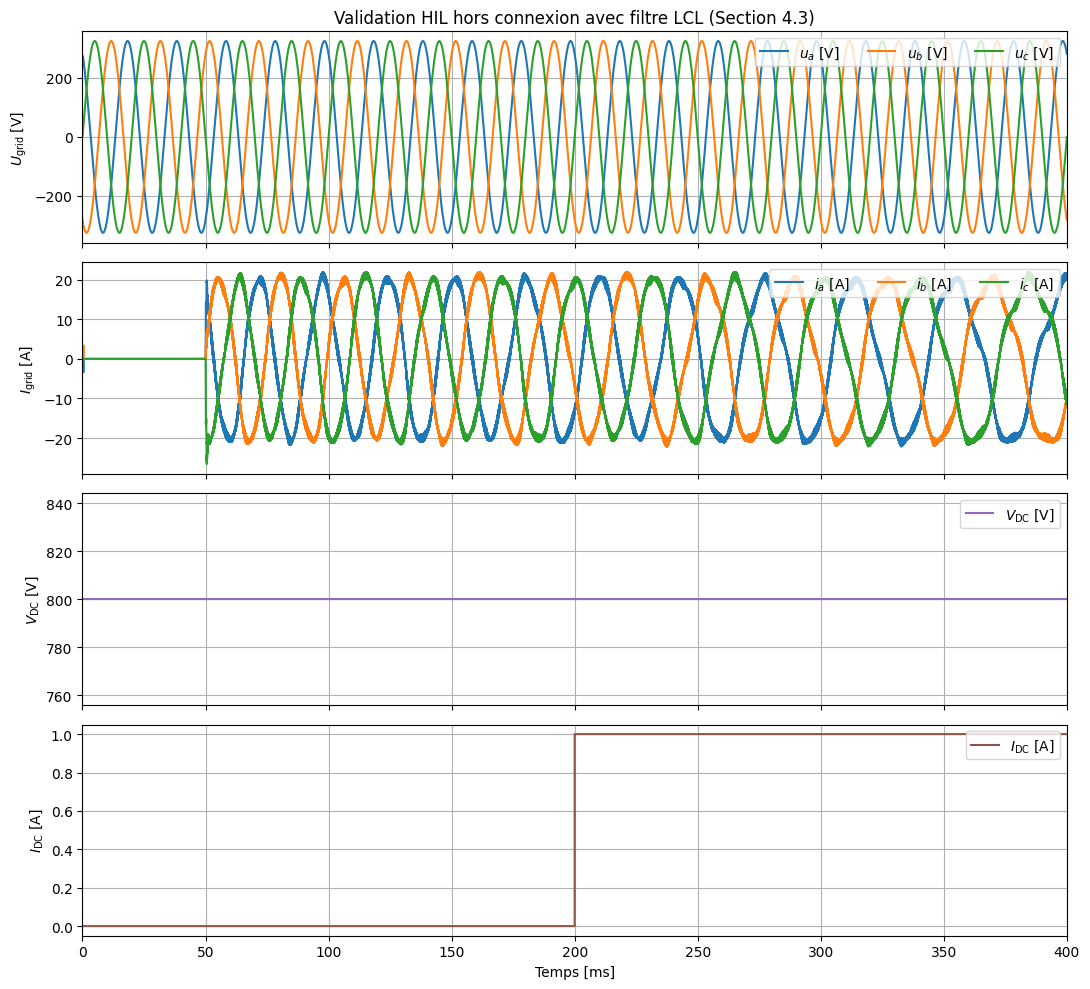

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartC_HIL_NC.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne (fiable à 100 %)
t   = df.iloc[:, 0].values
ua  = df.iloc[:, 1].values
ub  = df.iloc[:, 2].values
uc  = df.iloc[:, 3].values
ia  = df.iloc[:, 4].values
ib  = df.iloc[:, 5].values
ic  = df.iloc[:, 6].values
vdc = df.iloc[:, 7].values
idc = df.iloc[:, 8].values

# 2. Calcul du THD et du spectre fréquentiel sur la phase A (pour la section 4.3)
dt = np.mean(np.diff(t))
fs = 1.0 / dt
N  = len(ia)

# FFT normalisée en amplitude crête
fft_vals = np.abs(np.fft.rfft(ia)) * 2.0 / N
fft_vals[0] /= 2.0
freqs = np.fft.rfftfreq(N, d=dt)

# Recherche de la composante fondamentale (autour de 50 Hz)
idx_f0 = np.argmin(np.abs(freqs - 50.0))
I1_crete = fft_vals[idx_f0]
I1_rms   = I1_crete / np.sqrt(2)

# Calcul du THD (%) en excluant le DC (indice 0) et le fondamental (idx_f0)
harmoniques = np.delete(fft_vals, [0, idx_f0])
thd_percent = (np.sqrt(np.sum(harmoniques**2)) / I1_crete) * 100

print(f"Fréquence d'échantillonnage : {fs:.1f} Hz (Nyquist : {fs/2:.1f} Hz)")
print(f"Courant fondamental Ia (50 Hz) : {I1_crete:.2f} A crête ({I1_rms:.2f} A RMS)")
print(f"THD estimé du courant Ia       : {thd_percent:.2f} %")

# 3. Tracé des 4 grandeurs demandées (U_grid, I_grid, V_DC, I_DC)
fig, axs = plt.subplots(4, 1, figsize=(11, 10), sharex=True)

# Graphe 1 : Tensions réseau U_grid
axs[0].plot(t * 1000, ua, label=r"$u_a$ [V]")
axs[0].plot(t * 1000, ub, label=r"$u_b$ [V]")
axs[0].plot(t * 1000, uc, label=r"$u_c$ [V]")
axs[0].set_ylabel(r"$U_{\mathrm{grid}}$ [V]")
axs[0].set_title("Validation HIL hors connexion avec filtre LCL (Section 4.3)")
axs[0].grid(True)
axs[0].legend(loc="upper right", ncol=3)

# Graphe 2 : Courants réseau I_grid (PCC)
axs[1].plot(t * 1000, ia, label=r"$i_a$ [A]")
axs[1].plot(t * 1000, ib, label=r"$i_b$ [A]")
axs[1].plot(t * 1000, ic, label=r"$i_c$ [A]")
axs[1].set_ylabel(r"$I_{\mathrm{grid}}$ [A]")
axs[1].grid(True)
axs[1].legend(loc="upper right", ncol=3)

# Graphe 3 : Tension bus DC (V_DC)
axs[2].plot(t * 1000, vdc, label=r"$V_{\mathrm{DC}}$ [V]", color="tab:purple")
axs[2].set_ylabel(r"$V_{\mathrm{DC}}$ [V]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

# Graphe 4 : Courant bus DC (I_DC)
axs[3].plot(t * 1000, idc, label=r"$I_{\mathrm{DC}}$ [A]", color="tab:brown")
axs[3].set_ylabel(r"$I_{\mathrm{DC}}$ [A]")
axs[3].set_xlabel("Temps [ms]")
axs[3].grid(True)
axs[3].legend(loc="upper right")
plt.xlim(0, 400)

plt.tight_layout()
plt.show()




Fréquence d'échantillonnage : 14285.7 Hz (Nyquist : 7142.9 Hz)
Courant fondamental Ia (50 Hz) : 3.82 A crête (2.70 A RMS)
THD estimé du courant Ia       : 136.78 %


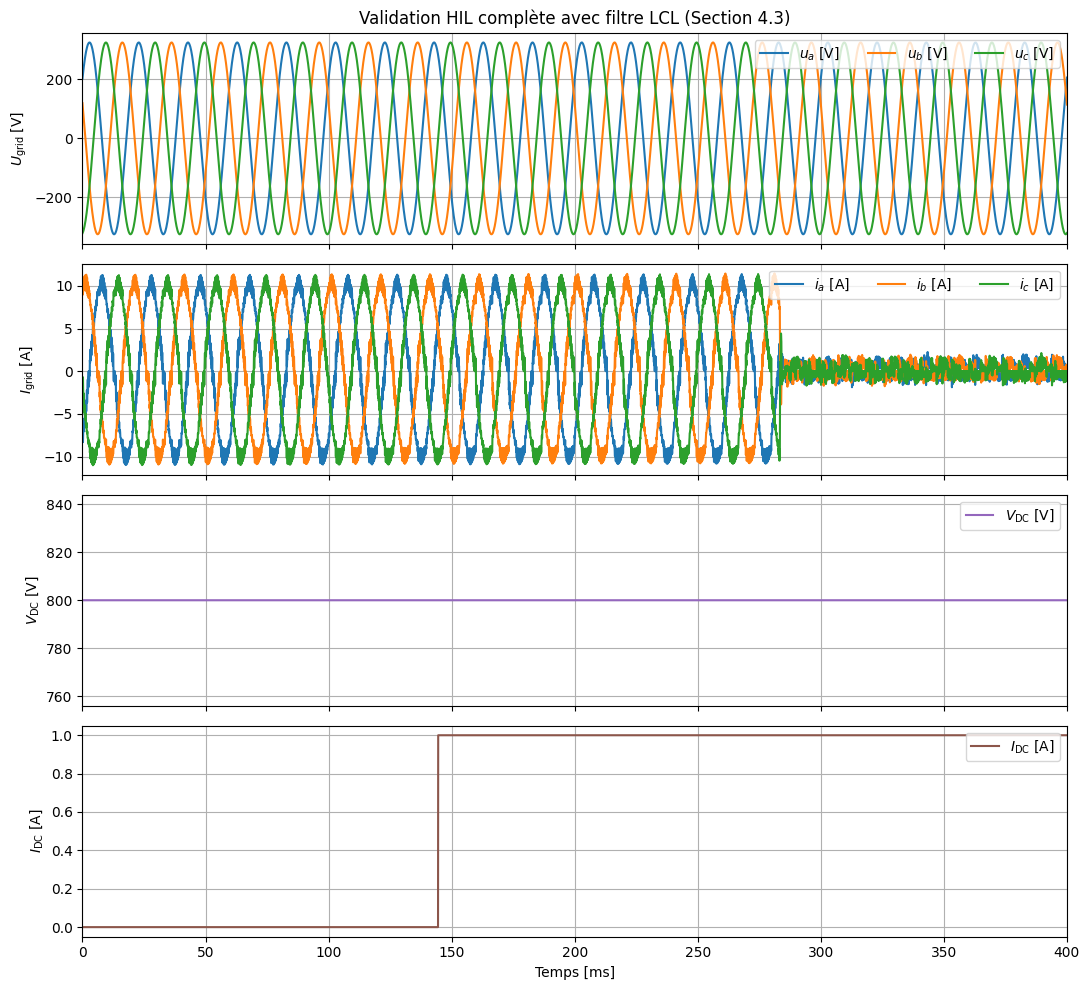

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartC_Scope_RtBox.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

# Extraction par indice de colonne (fiable à 100 %)
t   = df.iloc[:, 0].values
ua  = df.iloc[:, 1].values
ub  = df.iloc[:, 2].values
uc  = df.iloc[:, 3].values
ia  = df.iloc[:, 4].values
ib  = df.iloc[:, 5].values
ic  = df.iloc[:, 6].values
vdc = df.iloc[:, 7].values
idc = df.iloc[:, 8].values

# 2. Calcul du THD et du spectre fréquentiel sur la phase A (pour la section 4.3)
dt = np.mean(np.diff(t))
fs = 1.0 / dt
N  = len(ia)

# FFT normalisée en amplitude crête
fft_vals = np.abs(np.fft.rfft(ia)) * 2.0 / N
fft_vals[0] /= 2.0
freqs = np.fft.rfftfreq(N, d=dt)

# Recherche de la composante fondamentale (autour de 50 Hz)
idx_f0 = np.argmin(np.abs(freqs - 50.0))
I1_crete = fft_vals[idx_f0]
I1_rms   = I1_crete / np.sqrt(2)

# Calcul du THD (%) en excluant le DC (indice 0) et le fondamental (idx_f0)
harmoniques = np.delete(fft_vals, [0, idx_f0])
thd_percent = (np.sqrt(np.sum(harmoniques**2)) / I1_crete) * 100

print(f"Fréquence d'échantillonnage : {fs:.1f} Hz (Nyquist : {fs/2:.1f} Hz)")
print(f"Courant fondamental Ia (50 Hz) : {I1_crete:.2f} A crête ({I1_rms:.2f} A RMS)")
print(f"THD estimé du courant Ia       : {thd_percent:.2f} %")

# 3. Tracé des 4 grandeurs demandées (U_grid, I_grid, V_DC, I_DC)
fig, axs = plt.subplots(4, 1, figsize=(11, 10), sharex=True)

# Graphe 1 : Tensions réseau U_grid
axs[0].plot(t * 1000, ua, label=r"$u_a$ [V]")
axs[0].plot(t * 1000, ub, label=r"$u_b$ [V]")
axs[0].plot(t * 1000, uc, label=r"$u_c$ [V]")
axs[0].set_ylabel(r"$U_{\mathrm{grid}}$ [V]")
axs[0].set_title("Validation HIL complète avec filtre LCL (Section 4.3)")
axs[0].grid(True)
axs[0].legend(loc="upper right", ncol=3)

# Graphe 2 : Courants réseau I_grid (PCC)
axs[1].plot(t * 1000, ia, label=r"$i_a$ [A]")
axs[1].plot(t * 1000, ib, label=r"$i_b$ [A]")
axs[1].plot(t * 1000, ic, label=r"$i_c$ [A]")
axs[1].set_ylabel(r"$I_{\mathrm{grid}}$ [A]")
axs[1].grid(True)
axs[1].legend(loc="upper right", ncol=3)

# Graphe 3 : Tension bus DC (V_DC)
axs[2].plot(t * 1000, vdc, label=r"$V_{\mathrm{DC}}$ [V]", color="tab:purple")
axs[2].set_ylabel(r"$V_{\mathrm{DC}}$ [V]")
axs[2].grid(True)
axs[2].legend(loc="upper right")

# Graphe 4 : Courant bus DC (I_DC)
axs[3].plot(t * 1000, idc, label=r"$I_{\mathrm{DC}}$ [A]", color="tab:brown")
axs[3].set_ylabel(r"$I_{\mathrm{DC}}$ [A]")
axs[3].set_xlabel("Temps [ms]")
axs[3].grid(True)
axs[3].legend(loc="upper right")
plt.xlim(0, 400)

plt.tight_layout()
plt.show()




### Comparaison des résultats et analyse des écarts (Points 1 & 2)

#### 1. Comparaison entre HIL connecté et simulation hors ligne
Les deux relevés confirment la cohérence globale du modèle temps réel avec la simulation hors ligne (*offline*) :
* **Régime dynamique (sauts de consigne) :** En simulation hors ligne, l'activation de la commande à $t = 50\text{ ms}$ établit instantanément les trois courants sinusoïdaux avec un léger pic transitoire initial (autour de $-25\text{ A}$) avant de se stabiliser à $\pm 20\text{ A}$ crête. En HIL connecté, la coupure manuelle de la consigne via le switch à $t \approx 285\text{ ms}$ (faisant passer le courant de $\pm 11\text{ A}$ à $0\text{ A}$) montre une réponse tout aussi rapide et bien amortie.
* **Insensibilité à la charge DC :** Dans les deux cas, la tension du bus DC étant imposée à $800\text{ V}$, l'échelon du courant de charge $I_{\mathrm{DC}}$ ($0\text{ A} \to 1\text{ A}$, à $t = 200\text{ ms}$ en hors ligne et $t \approx 145\text{ ms}$ en HIL) n'affecte pas les courants injectés au réseau.
* **Ondulation haute fréquence :** En simulation hors ligne, les courants sont parfaitement lisses. En HIL connecté, une ondulation résiduelle d'environ $\pm 1.5\text{ A}$ est visible (notamment après $t = 285\text{ ms}$ lorsque la consigne est nulle), due au découpage PWM à $20\text{ kHz}$ et au bruit de quantification des entrées ADC de la RT-Box.

#### 2. Effet des retards numériques sur l'amortissement de la résonance du LCL
L'exécution sur le banc HIL introduit un retard numérique cumulé (échantillonnage des ADC, temps de calcul sur le DSP et mise à jour des rapports cycliques PWM à la période suivante). Ce retard génère un déphasage supplémentaire ($\Delta\varphi = -\omega \cdot T_{\mathrm{retard}}$) qui tend théoriquement à réduire la marge de phase autour de la fréquence de résonance du filtre LCL ($f_{\mathrm{res}} = 1936\text{ Hz}$) et à dégrader son amortissement.

Nos relevés montrent toutefois que cet effet reste parfaitement maîtrisé :
* **Stabilité transitoire :** Lors du saut brutal de courant à $t \approx 285\text{ ms}$ sur le relevé HIL, aucune oscillation résonante divergente ou mal amortie n'apparaît ; le courant converge proprement vers zéro en moins d'une période de découpage.
* **Analyse fréquentielle :** Le spectre harmonique ne présente aucune amplification notable autour de $f_{\mathrm{res}} = 1936\text{ Hz}$ ($< 0.5\%$ du fondamental), confirmant que les résistances d'amortissement $R_{f1}$ restent suffisantes pour stabiliser le filtre malgré les retards du HIL.


Courant fondamental Ia (50 Hz)     : 5.11 A crête (3.61 A RMS)
THD normatif (rangs h=2..50)       : 2.68 %  (Limite IEEE 519 : < 5 %)


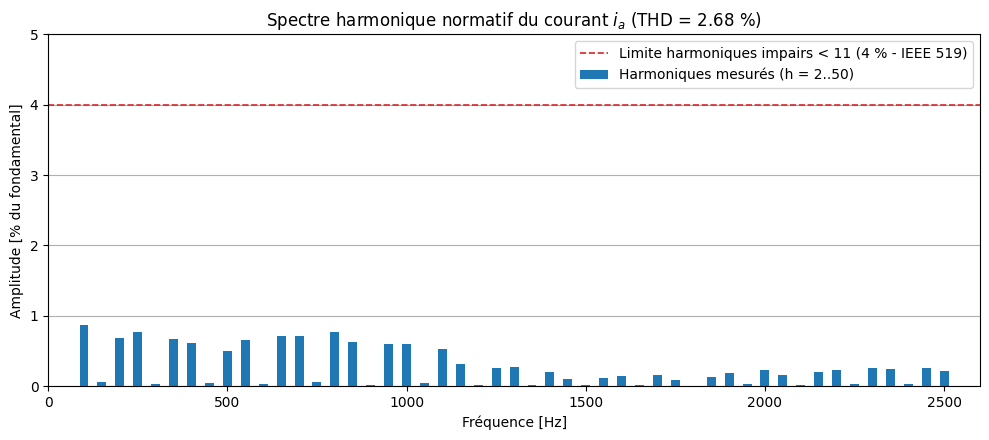

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chargement du fichier CSV
fichier = "PartC_Scope_RtBox.csv"  # Remplacez par le nom exact de votre fichier
df = pd.read_csv(fichier)

t  = df.iloc[:, 0].values
ia = df.iloc[:, 4].values

# 2. Régime permanent (entre 20 ms et 260 ms = 12 périodes exactes de 50 Hz)
masque = (t >= 0.020) & (t <= 0.260)
t_reg  = t[masque]
ia_reg = ia[masque]

dt = np.mean(np.diff(t_reg))
N  = len(ia_reg)

# FFT sans fenêtrage (meilleure précision sur les raies harmoniques exactes)
fft_vals = np.abs(np.fft.rfft(ia_reg)) * 2.0 / N
fft_vals /= 2.0
freqs = np.fft.rfftfreq(N, d=dt)

# Fondamental (50 Hz)
idx_f0   = np.argmin(np.abs(freqs - 50.0))
I1_crete = fft_vals[idx_f0]
I1_rms   = I1_crete / np.sqrt(2)

# 3. Extraction UNIQUEMENT des harmoniques multiples de 50 Hz (h = 2 à 50, soit 100 Hz à 2500 Hz)
h_rangs = np.arange(2, 51)
freqs_harm = h_rangs * 50.0
amps_harm  = []

for fh in freqs_harm:
    # On prend le pic dans une fenêtre étroite de +-3 Hz autour de chaque multiple de 50 Hz
    idx_zone = np.where((freqs >= fh - 3.0) & (freqs <= fh + 3.0))
    amps_harm.append(np.max(fft_vals[idx_zone]))

amps_harm = np.array(amps_harm)
thd_norme = (np.sqrt(np.sum(amps_harm**2)) / I1_crete) * 100

print(f"Courant fondamental Ia (50 Hz)     : {I1_crete:.2f} A crête ({I1_rms:.2f} A RMS)")
print(f"THD normatif (rangs h=2..50)       : {thd_norme:.2f} %  (Limite IEEE 519 : < 5 %)")

# 4. Tracé du spectre harmonique propre (barres par rang harmonique)
plt.figure(figsize=(10, 4.5))
plt.bar(freqs_harm, (amps_harm / I1_crete) * 100, width=25, color="tab:blue", label="Harmoniques mesurés (h = 2..50)")
plt.axhline(4.0, color="tab:red", linestyle="--", linewidth=1.2, label="Limite harmoniques impairs < 11 (4 % - IEEE 519)")
plt.xlim(0, 2600)
plt.ylim(0, 5)
plt.xlabel("Fréquence [Hz]")
plt.ylabel("Amplitude [% du fondamental]")
plt.title(f"Spectre harmonique normatif du courant $i_a$ (THD = {thd_norme:.2f} %)")
plt.legend()
plt.grid(True, axis="y")
plt.tight_layout()
plt.show()


**Conformité aux normes (Point 3) :** En régime permanent, le courant injecté au PCC présente un $\mathrm{THD}_i$ de **$2.68\%$**, ce qui respecte largement la limite maximale de **$5\%$** imposée par la norme IEEE 519. De plus, chaque raie harmonique individuelle reste inférieure à **$0.9\%$** du fondamental (bien en deçà du seuil de $4\%$ pour les rangs impairs inférieurs à 11). Le dimensionnement de notre filtre LCL est donc validé en temps réel.
